In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
# import rapids_singlecell as rsc
import decoupler as dc
import palantir

from matplotlib.pyplot import rc_context
from matplotlib import pyplot as plt
import matplotlib as mpl
from copy import copy
import seaborn as sns
from adjustText import adjust_text

import math
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

import yaml
with open("config/config.yml") as stream:
    try:
        config = yaml.safe_load(stream)
    except yaml.YAMLError as exc:
        print(exc)

pd.set_option("display.max_columns", None)

sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.logging.print_header()
sc.settings.set_figure_params(dpi=100, facecolor='white')

# set up a color map with gray for zero expression
reds = copy(mpl.cm.Reds)
reds.set_under("lightgray")

In [2]:
#https://github.com/scverse/anndata/issues/339
import scipy
scipy.__version__

'1.16.3'

In [3]:
palantir.__version__

'1.4.3'

helpful reading
- [Woodall et al., Nature Microbiology 2024](https://www.nature.com/articles/s41564-024-01658-1#ethics) for basaloid, IFN-gamma geneset scores in nasal epithelial cells (NOT included in HLCA)

## download data

In [10]:
# human lung cell atlas
# https://data.humancellatlas.org/hca-bio-networks/lung/atlases/lung-v1-0#
import os
import requests

def get_h5ad(url,path):
    response = requests.get(url, stream=True)
    response.raise_for_status()

    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path),exist_ok=True)
        with open(path,'wb') as f:
            for chunk in response.iter_content(chunk_size=8192):
                f.write(chunk)
        print("download completed.")
    else:
        print("already downloaded.")

## HLCA - Human lung cell atlas
data integrated from 49 (core) or 84 (full with various disease states) datasets.
Integrated with scANVI

In [ ]:
hlca_V1_url = config["data"]["HLCA"]["core_h5ad_url"]
hlca_V1_path = config["data"]["HLCA"]["core_h5ad_path"]
get_h5ad(hlca_V1_url,hlca_V1_path)
adata = sc.read(hlca_V1_path)

NameError: name 'config' is not defined

In [ ]:
adata.layers["scANVI"] = adata.X.copy()
adata.layers["raw"] = adata.raw.X.copy()
adata = adata[:, ~adata.var["feature_name"].duplicated()].copy() # bandage fix

NameError: name 'adata' is not defined

In [ ]:
print(adata.X.max())
print(adata.raw.X.max())

11.255894
34950.0


In [ ]:
adata.obs

,suspension_type,donor_id,is_primary_data,assay_ontology_term_id,cell_type_ontology_term_id,development_stage_ontology_term_id,disease_ontology_term_id,self_reported_ethnicity_ontology_term_id,tissue_ontology_term_id,sex_ontology_term_id,BMI,age_or_mean_of_age_range,age_range,anatomical_region_ccf_score,ann_coarse_for_GWAS_and_modeling,ann_finest_level,ann_level_1,ann_level_2,ann_level_3,ann_level_4,ann_level_5,cause_of_death,dataset,entropy_dataset_leiden_3,entropy_original_ann_level_1_leiden_3,entropy_original_ann_level_2_clean_leiden_3,entropy_original_ann_level_3_clean_leiden_3,entropy_subject_ID_leiden_3,fresh_or_frozen,leiden_1,leiden_2,leiden_3,leiden_4,leiden_5,log10_total_counts,lung_condition,mixed_ancestry,n_genes_detected,original_ann_highest_res,original_ann_level_1,original_ann_level_2,original_ann_level_3,original_ann_level_4,original_ann_level_5,original_ann_nonharmonized,reannotation_type,reference_genome,sample,scanvi_label,sequencing_platform,size_factors,smoking_status,study,subject_type,tissue_dissociation_protocol,tissue_level_2,tissue_level_3,tissue_sampling_method,tissue_type,cell_type,assay,disease,sex,tissue,self_reported_ethnicity,development_stage,observation_joinid
GCGACCATCCCTAACC_SC22,cell,homosapiens_None_2023_None_sikkemalisa_001_d10...,False,EFO:0009899,CL:0000583,HsapDv:0000143,PATO:0000461,unknown,UBERON:0008946,PATO:0000383,NaN,49.0,NaN,0.97,Alveolar macrophages,Alveolar macrophages,Immune,Myeloid,Macrophages,Alveolar macrophages,None,intracranial hemorrhage,Misharin_Budinger_2018,1.664049,0.177918,0.182714,0.277385,2.602398,fresh,1,1.0,1.0.0,1.0.0.0,NaN,4.016197,Healthy,NaN,2438,4,Immune,Myeloid,Macrophages,Alveolar macrophages,None,Alveolar macrophages,Correctly annotated,Homo_sapiens.GRCh38.84,SC22,Macrophages,Illumina HiSeq 4000,0.998238,active,Misharin_Budinger_2018,organ_donor,Collagenase D + DNAse,parenchyma lower lobe,NaN,donor_lung,tissue,alveolar macrophage,10x 3' v2,normal,female,lung parenchyma,unknown,49-year-old stage,y3(xbM64-M
P2_1_GCGCAACCAGTTAACC,cell,homosapiens_None_2023_None_sikkemalisa_001_d10...,False,EFO:0009899,CL:0000623,HsapDv:0000140,PATO:0000461,unknown,UBERON:0008946,PATO:0000384,33.100,46.0,NaN,0.97,Innate lymphoid cell NK,NK cells,Immune,Lymphoid,Innate lymphoid cell NK,NK cells,None,NaN,Krasnow_2020,1.461924,0.013459,0.015608,0.326962,2.729274,fresh,1,1.3,1.3.0,1.3.0.0,NaN,3.203848,Healthy (tumor adjacent),NaN,700,4,Immune,Lymphoid,Innate lymphoid cell NK,NK cells,None,Natural Killer,Correctly annotated,Homo_sapiens.GRCh38.84,distal 2,Non-T/B cells,Illumina NovaSeq 6000,0.172927,never,Krasnow_2020,alive_disease,Collagenase + Elastase + DNAse,parenchyma right middle lobe,NaN,surgical_resection,tissue,natural killer cell,10x 3' v2,normal,male,lung parenchyma,unknown,46-year-old stage,A>+$XL~PxD
GCTCTGTAGTGCTGCC_SC27,cell,homosapiens_None_2023_None_sikkemalisa_001_d10...,False,EFO:0009899,CL:0002063,HsapDv:0000141,PATO:0000461,unknown,UBERON:0008946,PATO:0000383,NaN,47.0,NaN,0.97,AT2,AT2,Epithelial,Alveolar epithelium,AT2,None,None,intracranial hemorrhage,Misharin_Budinger_2018,1.381972,0.280016,0.208872,0.388602,2.006138,fresh,0,0.1,0.1.2,0.1.2.0,NaN,3.493458,Healthy,NaN,1200,3,Epithelial,Alveolar epithelium,AT2,None,None,Alveolar epithelial type 2 cells,Correctly annotated,Homo_sapiens.GRCh38.84,SC27,AT2,Illumina HiSeq 4000,0.343101,active,Misharin_Budinger_2018,organ_donor,Collagenase D + DNAse,parenchyma lower lobe,NaN,donor_lung,tissue,pulmonary alveolar type 2 cell,10x 3' v2,normal,female,lung parenchyma,unknown,47-year-old stage,5jcAkve8k5
P2_8_TTAGGACGTTCAGGCC,cell,homosapiens_None_2023_None_sikkemalisa_001_d10...,False,EFO:0009899,CL:0000583,HsapDv:0000140,PATO:0000461,unknown,UBERON:0001005,PATO:0000384,33.100,46.0,NaN,0.81,Alveolar macrophages,Alveolar Mph CCL3+,Immune,Myeloid,Macrophages,Alveolar macrophages,Alveolar Mph CCL3+,NaN,Krasnow_2020,1.005008,0.002307,0.019563,0.062629,1.192024,fresh,1,1.0,1.0.2,1.0.2.0,NaN,4.242591,Healthy (tumor adjacent

In [ ]:
adata.var["ENSEMBL_ID"] = adata.var.index
adata.var_names = adata.var["feature_name"]
adata.var.index = adata.var["feature_name"]
adata.var_names_make_unique()

/home/mark/miniconda3/envs/decoupler/lib/python3.12/site-packages/anndata/_core/anndata.py:865: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['TSPAN6', 'TNMD', 'DPM1', 'SCYL3', 'C1orf112']

    Inferred to be: categorical

  names = self._prep_dim_index(names, "var")


In [ ]:
adata

AnnData object with n_obs × n_vars = 584944 × 27944
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'sex_ontology_term_id', 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'dataset', 'entropy_dataset_leiden_3', 'entropy_original_ann_level_1_leiden_3', 'entropy_original_ann_level_2_clean_leiden_3', 'entropy_original_ann_level_3_clean_leiden_3', 'entropy_subject_ID_leiden_3', 'fresh_or_frozen', 'leiden_1', 'leiden_2', 'leiden_3', 'leiden_4', 'leiden_5', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'n_genes_detected', 'original_ann_highest_res', 'original_ann_level_1', 'original_ann_level_2', 'origi

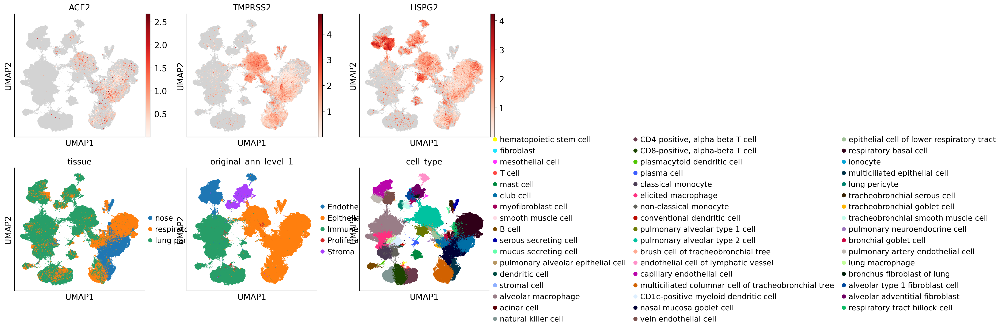

In [ ]:
with rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(
        adata = adata,
        color = [
            "ACE2","TMPRSS2","HSPG2",
            "tissue","original_ann_level_1",
            "cell_type"],
        ncols=3,size=3,
        use_raw=False,layer = "scANVI",
        color_map=reds,vmin=0.00001,
        show=False
    )
# plt.savefig("figures/lung/lung_umap_plot.pdf",dpi=300,bbox_inches='tight')

In [ ]:
adata_plot = adata[
            (adata.obs["original_ann_level_1"]=="Epithelial")
        ]

In [ ]:
adata.obs[["tissue","original_ann_level_1","ann_coarse_for_GWAS_and_modeling","cell_type"]].value_counts().reset_index(name="n").query('n>100')

,tissue,original_ann_level_1,ann_coarse_for_GWAS_and_modeling,cell_type,n
0,respiratory airway,Epithelial,Basal,respiratory basal cell,78230
1,lung parenchyma,Immune,Alveolar macrophages,alveolar macrophage,71171
2,lung parenchyma,Epithelial,AT2,pulmonary alveolar type 2 cell,59339
3,nose,Epithelial,Secretory,nasal mucosa goblet cell,33179
4,lung parenchyma,Immune,Monocyte-derived Mph,elicited macrophage,26007
...,...,...,...,...,...
102,respiratory airway,Epithelial,Tuft,brush cell of tracheobronchial tree,139
103,respiratory airway,Epithelial,Neuroendocrine,pulmonary neuroendocrine cell,137
104,nose,Endothelial,EC venous,vein endothelial cell,123
105,respiratory airway,Stroma,Myofibroblasts,myofibroblast cell,115


In [ ]:
adata_plot.obs[["tissue","original_ann_level_1","ann_coarse_for_GWAS_and_modeling","cell_type"]].value_counts().reset_index(name="n").query('n>100').sort_values("tissue")

,tissue,original_ann_level_1,ann_coarse_for_GWAS_and_modeling,cell_type,n
30,nose,Epithelial,SMG duct,acinar cell,264
12,nose,Epithelial,Basal,respiratory tract hillock cell,2438
33,nose,Epithelial,SMG mucous,mucus secreting cell,187
9,nose,Epithelial,Multiciliated,multiciliated columnar cell of tracheobronchia...,4597
16,nose,Epithelial,SMG serous,serous secreting cell,1460
8,nose,Epithelial,Multiciliated,multiciliated epithelial cell,5156
3,nose,Epithelial,Secretory,club cell,25620
2,nose,Epithelial,Secretory,nasal mucosa goblet cell,33179
35,nose,Epithelial,Ionocyte,ionocyte,140
18,nose,Epithelial,Basal,respiratory basal cell,1212


/tmp/ipykernel_396712/4215345345.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_plot.obs["cell_type"] = adata_plot.obs["cell_type"].cat.remove_unused_categories()


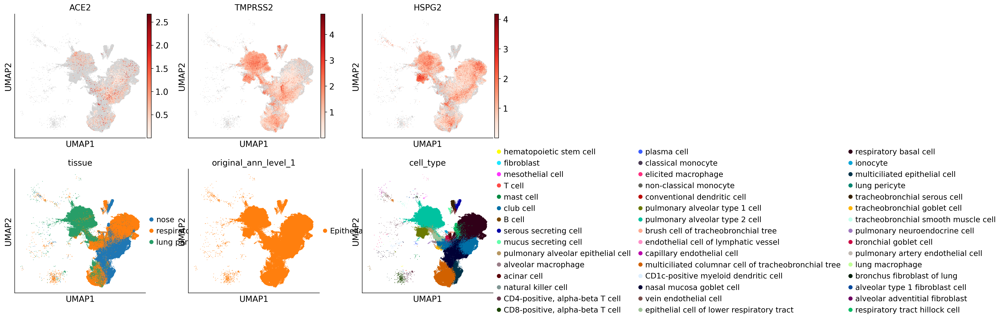

In [ ]:
adata_plot.obs["cell_type"] = adata_plot.obs["cell_type"].cat.remove_unused_categories()
with rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(
        adata = adata_plot,
        color = [
            "ACE2","TMPRSS2","HSPG2",
            "tissue","original_ann_level_1","cell_type",
            ],
        ncols=3,size=3,
        use_raw=False,layer = "scANVI",
        color_map=reds,vmin=0.00001,
        show=False
    )
# plt.savefig("figures/lung/lung_umap_plot.pdf",dpi=300,bbox_inches='tight')

In [ ]:
adata.obs["tissue"].cat.categories

Index(['nose', 'respiratory airway', 'lung parenchyma'], dtype='str')

In [ ]:
valid_combos = (
    adata_plot.obs
    .groupby(["tissue", "original_ann_level_1", "ann_coarse_for_GWAS_and_modeling"])
    .size()   # counts per combination
    .reset_index(name="n")
    .query("n > 100")  # keep only combinations with >100 cells
    .query('ann_coarse_for_GWAS_and_modeling != "T cell lineage"')
)
valid_combos.sort_values("tissue")
# SMG = submucosal glands

,tissue,original_ann_level_1,ann_coarse_for_GWAS_and_modeling,n
2,nose,Epithelial,Basal,3650
7,nose,Epithelial,Ionocyte,140
12,nose,Epithelial,Multiciliated,9753
14,nose,Epithelial,SMG duct,264
15,nose,Epithelial,SMG mucous,187
16,nose,Epithelial,SMG serous,1473
17,nose,Epithelial,Secretory,58805
49,respiratory airway,Epithelial,Tuft,139
48,respiratory airway,Epithelial,Transitional Club-AT2 cells,696
45,respiratory airway,Epithelial,Secretory,14474


In [ ]:
# Create a set of tuples for fast membership check
valid_tuples = set(
    zip(
        valid_combos["tissue"],
        valid_combos["original_ann_level_1"],
        valid_combos["ann_coarse_for_GWAS_and_modeling"]
    )
)
# Apply mask to obs
mask = adata_plot.obs.apply(
    lambda r: (r["tissue"], r["original_ann_level_1"], r["ann_coarse_for_GWAS_and_modeling"]) in valid_tuples,
    axis=1
)

In [ ]:
adata_plot2 = adata_plot[mask].copy()

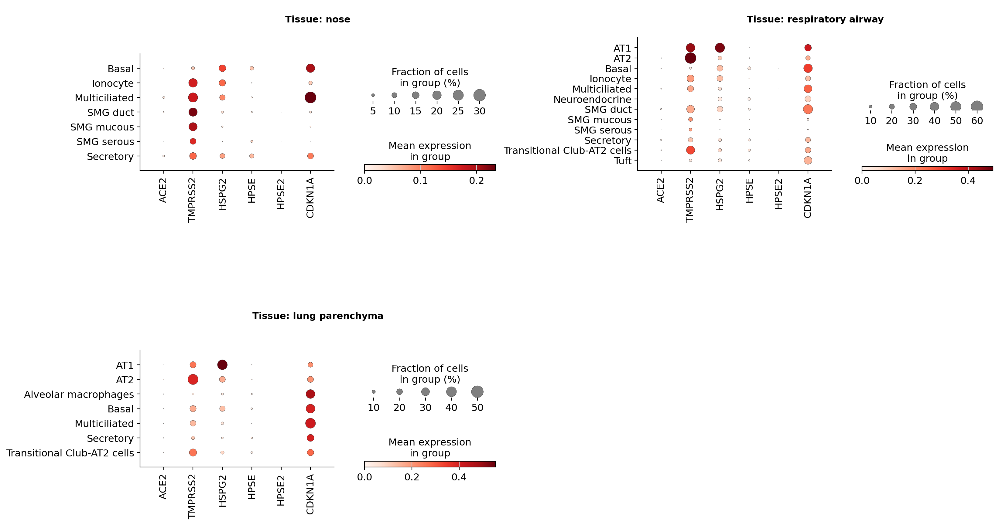

In [ ]:
tissues = adata_plot.obs["tissue"].cat.categories
n = len(tissues)

ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(18, 5 * nrows)
)

axes = axes.flatten()  # ← important

with PdfPages("figures/lung/HLCA_dotplots_by_tissue.pdf") as pdf:
    for ax, tissue in zip(axes, tissues):
        sc.pl.dotplot(
            adata=adata_plot2[
                adata_plot2.obs["tissue"] == tissue
            ],
            var_names=["ACE2", "TMPRSS2","HSPG2","HPSE","HPSE2","CDKN1A"
                    #  "XYLT2","SLC35B2"
                    ] ,
            groupby="ann_coarse_for_GWAS_and_modeling",
            use_raw=False,show=False,
            # dot_max=1,dot_min=0,
            ax=ax
        )
        ax.set_title(
            f"Tissue: {tissue}",fontsize=11,
            fontweight="bold",pad=0,y=0.9
        )

    # Hide unused axes (if odd number of tissues)
    for ax in axes[len(tissues):]:
        ax.axis("off")

    fig.subplots_adjust(hspace=0.8, wspace=0.4)
    pdf.savefig(fig)
    plt.show()
    plt.close(fig)

## Madisson et al., Nature Genetics 2023

In [ ]:
MadisoonV1_url = config["data"]["madisson_NatGen2023"]["h5ad_url"]
MadisoonV1_path = config["data"]["madisson_NatGen2023"]["h5ad_path"]
get_h5ad(MadisoonV1_url,MadisoonV1_path)
adata = sc.read(MadisoonV1_path)

already downloaded.


In [ ]:
adata

AnnData object with n_obs × n_vars = 193108 × 1147
    obs: 'Celltypes', 'Celltypes_master_high', 'Celltypes_master_higher', 'Celltypes_master_higher_immune', 'Loc_true', 'Material', 'Donor', 'Donor_ID_2', 'Gender', 'Sample', 'ID', 'Protocol_plot', 'Version', 'Study', 'PoolDon', 'DonorPool', 'scDonor_snBatch', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'mt', 'gene_ids-0', 'n_cells-0', 'n_cells_by_counts-0', 'mean_counts-0', 'pct_dropout_by_counts-0', 'total_counts-0', 'gene_ids-1', 'n_cells-1', 'n_cells_by_counts-1', 'mean_counts-1', 'pct_dropout_by_counts-1', 'total_counts-1', 'feature_types-1', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'Celltypes_colors', 'Celltypes_int_F_colors', 'Celltypes_int_colors', 'Celltypes_int_updB_colors', 'Celltypes_master_high_colors', 'ID_colors', 'Loc_true_colors', 'hvg', 'leiden', 'leiden_co

In [ ]:
print(adata.X.max())
print(adata.raw.X.max())

10.0
9.026224


In [ ]:
adata.obs

,Celltypes,Celltypes_master_high,Celltypes_master_higher,Celltypes_master_higher_immune,Loc_true,Material,Donor,Donor_ID_2,Gender,Sample,ID,Protocol_plot,Version,Study,PoolDon,DonorPool,scDonor_snBatch,n_genes,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt
AAACCTGGTGTGAATA-1-WTDAtest7887999-0,AT1,Epithelia,Epithelia,AT1,d_LowLeftPar,cells,A32,411C,M,WTDAtest7887999,A32-LNG-1-SC-45N-1,LibCD45neg_TrypLibUndigest,10x3prime_v2,dissociation,nan,nan,A32_cells,1943,1943,5356.075684,186.790329,3.487448
AAACGGGCAACCGCCA-1-WTDAtest7887999-0,B_plasma_IgA,Immune,Immune,B_cell,d_LowLeftPar,cells,A32,411C,M,WTDAtest7887999,A32-LNG-1-SC-45N-1,LibCD45neg_TrypLibUndigest,10x3prime_v2,dissociation,nan,nan,A32_cells,226,226,768.994751,5.476773,0.712199
AACCATGGTACAGCAG-1-WTDAtest7887999-0,Monocyte_CD16,Immune,Immune,Monocyte,d_LowLeftPar,cells,A32,411C,M,WTDAtest7887999,A32-LNG-1-SC-45N-1,LibCD45neg_TrypLibUndigest,10x3prime_v2,dissociation,nan,nan,A32_cells,847,847,1901.789185,108.158295,5.687187
AACGTTGGTGTCCTCT-1-WTDAtest7887999-0,CD8_EM/EMRA,Immune,Immune,CD8,d_LowLeftPar,cells,A32,411C,M,WTDAtest7887999,A32-LNG-1-SC-45N-1,LibCD45neg_TrypLibUndigest,10x3prime_v2,dissociation,nan,nan,A32_cells,767,767,1783.324097,85.630554,4.801738
AACTCCCTCCTAGTGA-1-WTDAtest7887999-0,Macro_intravascular,Immune,Immune,Macrophage_other,d_LowLeftPar,cells,A32,411C,M,WTDAtest7887999,A32-LNG-1-SC-45N-1,LibCD45neg_TrypLibUndigest,10x3prime_v2,dissociation,nan,nan,A32_cells,799,799,1314.895386,97.600655,7.422694
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGGTTGTAATGCGG-1-WSSS_A_LNG8757929-1,T_reg,Immune,Immune,CD4,b_Bronchi.2.3,nuclei,A42,nan,nan,WSSS_A_LNG8757929,WSSS_A_LNG8757929,nuclei,nan,nan,A42,A42none,A42_nuclei,1556,1556,2975.571777,0.000000,0.000000
TTTGGTTGTGCCCTTT-1-WSSS_A_LNG8757929-1,SMG_Mucous,Epithelia,Epithelia,Submucosal_Glands,b_Bronchi.2.3,nuclei,A42,nan,nan,WSSS_A_LNG8757929,WSSS_A_LNG8757929,nuclei,nan,nan,A42,A42none,A42_nuclei,2723,2723,7334.214355,0.000000,0.000000
TTTGGTTTCAAGAGTA-1-WSSS_A_LNG8757929-1,Basal,Epithelia,Epithelia,Epi_Basal,b_Bronchi.2.3,nuclei,A42,nan,nan,WSSS_A_LNG8757929,WSSS_A_LNG8757929,nuclei,nan,nan,A42,A42none,A42_nuclei,500,500,626.389465,0.000000,0.000000
TTTGTTGAGCGAGTCA-1-WSSS_A_LNG8757929-1,SMG_Mucous,Epithelia,Epithelia,Submucosal_Glands,b_Bronchi.2.3,nuclei,A42,nan,nan,WSSS_A_LNG8757929,WSSS_A_LNG8757929,nuclei,nan,nan,A42,A42none,A42_nuclei,2576,2576,6651.600586,0.000000,0.000000


In [ ]:
adata.var

,mt,gene_ids-0,n_cells-0,n_cells_by_counts-0,mean_counts-0,pct_dropout_by_counts-0,total_counts-0,gene_ids-1,n_cells-1,n_cells_by_counts-1,mean_counts-1,pct_dropout_by_counts-1,total_counts-1,feature_types-1,n_cells,highly_variable,means,dispersions,dispersions_norm,highly_variable_nbatches,highly_variable_intersection,mean,std
HES4,False,HES4,16580,16580,0.302786,88.689619,44385.750000,ENSG00000188290,5369,5369,0.047040,95.454930,5556.719727,Gene Expression,18879,True,0.348015,2.407703,0.858933,2,True,-4.553251e-11,0.512652
TNFRSF18,False,TNFRSF18,5391,5391,0.055908,96.322421,8195.559570,ENSG00000186891,570,570,0.004692,99.517473,554.286743,Gene Expression,5383,True,0.090583,2.411408,0.957952,2,True,-2.240157e-11,0.252654
TNFRSF4,False,TNFRSF4,5113,5113,0.054750,96.512064,8025.812988,ENSG00000186827,521,521,0.004022,99.558953,475.164764,Gene Expression,5170,True,0.103728,2.507761,1.110371,2,True,1.818045e-11,0.274860
AL645728.1,False,AL645728.1,1166,1166,0.008344,99.204590,1223.174438,ENSG00000215014,367,367,0.002795,99.689320,330.200958,Gene Expression,1251,True,0.020191,2.200457,0.519287,2,True,-9.707694e-12,0.115668
TTC34,False,TTC34,707,707,0.005823,99.517706,853.601624,ENSG00000215912,2557,2557,0.034357,97.835399,4058.525635,Gene Expression,1571,True,0.040115,2.175078,0.452723,2,True,-1.262883e-11,0.133543
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
UBASH3A,False,UBASH3A,2057,2057,0.015399,98.596776,2257.323975,ENSG00000160185,1330,1330,0.011449,98.874103,1352.410767,Gene Expression,2619,True,0.076424,2.345723,0.911611,2,True,2.340285e-12,0.203516
RSPH1,False,RSPH1,3765,3765,0.404490,97.431629,59294.632812,ENSG00000160188,3671,3671,0.087606,96.892354,10348.668945,Gene Expression,5024,True,0.237395,2.757026,1.647012,2,True,-2.383287e-11,0.381427
COL18A1,False,COL18A1,13232,13232,0.149136,90.973525,21861.937500,ENSG00000182871,6512,6512,0.064490,94.487336,7618.034180,Gene Expression,16562,True,0.321884,2.337140,0.801880,2,True,9.382796e-12,0.458006
COL6A1,False,COL6A1,14127,14127,0.513421,90.362983,75262.882812,ENSG00000142156,10117,10117,0.120751,91.435561,14264.091797,Gene Expression,19712,True,0.514242,2.488781,0.826094,2,True,-8.717349e-12,0.586709


In [ ]:
# https://www.nature.com/articles/s41586-022-04474-x/figures/11
substrings = ["basal","cili","secret","alv","aci"]

filtered = [x for x in adata.obs["Celltypes"].unique() if any(sub in x for sub in substrings)]
print(filtered)

['Macro_alveolar', 'Fibro_alveolar', 'Macro_alveolar_metallothioneins', 'Suprabasal']


In [ ]:
adata.obs.groupby(["Celltypes","Celltypes_master_high"]).size().reset_index(name="count")

,Celltypes,Celltypes_master_high,count
0,AT1,Epithelia,7315
1,AT2,Epithelia,18192
2,B_memory,Immune,1753
3,B_naive,Immune,638
4,B_plasma_IgA,Immune,844
...,...,...,...
77,Secretory_Club,Epithelia,2149
78,Secretory_Goblet,Epithelia,1632
79,Suprabasal,Epithelia,1918
80,T_reg,Immune,808


In [ ]:
adata_unique_Celltypes = adata.obs["Celltypes"].unique().tolist()
adata_unique_Celltypes

['AT1 ',
 'B_plasma_IgA',
 'Monocyte_CD16',
 'CD8_EM/EMRA',
 'Macro_intravascular',
 'CD8_EM',
 'AT2',
 'Macro_alveolar',
 'Fibro_adventitial',
 'ILC',
 'Monocyte_CD14',
 'NK_CD11d',
 'MAIT',
 'Dividing_AT2',
 'T_reg',
 'CD4_EM/Effector',
 'NK_CD16hi',
 'CD8_TRM/EM',
 'Endothelia_Lymphatic',
 'Endothelia_vascular_Cap_a',
 'DC_plasmacytoid',
 'DC_2',
 'CD4_TRM',
 'CD4_naive/CM',
 'Mast_cell ',
 'SMG_Mucous',
 'Dividing_Basal',
 'Ciliated',
 'Secretory_Club',
 'Muscle_smooth_pulmonary',
 'NKT',
 'B_memory',
 'DC_1',
 'Macro_CHIT1',
 'Macro_interstitial',
 'gdT',
 'Endothelia_vascular_Cap_g',
 'Endothelia_vascular_venous_systemic',
 'Endothelia_vascular_arterial_systemic',
 'Fibro_myofibroblast',
 'Endothelia_vascular_arterial_pulmonary',
 'Endothelia_vascular_venous_pulmonary',
 'Fibro_alveolar',
 'Secretory_Goblet',
 'Fibro_immune_recruiting',
 'Basal',
 'Muscle_pericyte_pulmonary',
 'Fibro_peribronchial',
 'B_plasma_IgG',
 'Macro_alveolar_metallothioneins',
 'Macro_intermediate',
 'CD8

In [ ]:
substrings = ["secretory","basal","alveolar","cili","club","goblet","suprabasal"]
filtered_Celltypess = [s for s in adata_unique_Celltypes if any (sub in s for sub in substrings)]
filtered_Celltypess

['Macro_alveolar',
 'Fibro_alveolar',
 'Macro_alveolar_metallothioneins',
 'Suprabasal']

In [ ]:
adata

AnnData object with n_obs × n_vars = 193108 × 1147
    obs: 'Celltypes', 'Celltypes_master_high', 'Celltypes_master_higher', 'Celltypes_master_higher_immune', 'Loc_true', 'Material', 'Donor', 'Donor_ID_2', 'Gender', 'Sample', 'ID', 'Protocol_plot', 'Version', 'Study', 'PoolDon', 'DonorPool', 'scDonor_snBatch', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'mt', 'gene_ids-0', 'n_cells-0', 'n_cells_by_counts-0', 'mean_counts-0', 'pct_dropout_by_counts-0', 'total_counts-0', 'gene_ids-1', 'n_cells-1', 'n_cells_by_counts-1', 'mean_counts-1', 'pct_dropout_by_counts-1', 'total_counts-1', 'feature_types-1', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'Celltypes_colors', 'Celltypes_int_F_colors', 'Celltypes_int_colors', 'Celltypes_int_updB_colors', 'Celltypes_master_high_colors', 'ID_colors', 'Loc_true_colors', 'hvg', 'leiden', 'leiden_co

In [ ]:
adata.var

,mt,gene_ids-0,n_cells-0,n_cells_by_counts-0,mean_counts-0,pct_dropout_by_counts-0,total_counts-0,gene_ids-1,n_cells-1,n_cells_by_counts-1,mean_counts-1,pct_dropout_by_counts-1,total_counts-1,feature_types-1,n_cells,highly_variable,means,dispersions,dispersions_norm,highly_variable_nbatches,highly_variable_intersection,mean,std
HES4,False,HES4,16580,16580,0.302786,88.689619,44385.750000,ENSG00000188290,5369,5369,0.047040,95.454930,5556.719727,Gene Expression,18879,True,0.348015,2.407703,0.858933,2,True,-4.553251e-11,0.512652
TNFRSF18,False,TNFRSF18,5391,5391,0.055908,96.322421,8195.559570,ENSG00000186891,570,570,0.004692,99.517473,554.286743,Gene Expression,5383,True,0.090583,2.411408,0.957952,2,True,-2.240157e-11,0.252654
TNFRSF4,False,TNFRSF4,5113,5113,0.054750,96.512064,8025.812988,ENSG00000186827,521,521,0.004022,99.558953,475.164764,Gene Expression,5170,True,0.103728,2.507761,1.110371,2,True,1.818045e-11,0.274860
AL645728.1,False,AL645728.1,1166,1166,0.008344,99.204590,1223.174438,ENSG00000215014,367,367,0.002795,99.689320,330.200958,Gene Expression,1251,True,0.020191,2.200457,0.519287,2,True,-9.707694e-12,0.115668
TTC34,False,TTC34,707,707,0.005823,99.517706,853.601624,ENSG00000215912,2557,2557,0.034357,97.835399,4058.525635,Gene Expression,1571,True,0.040115,2.175078,0.452723,2,True,-1.262883e-11,0.133543
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
UBASH3A,False,UBASH3A,2057,2057,0.015399,98.596776,2257.323975,ENSG00000160185,1330,1330,0.011449,98.874103,1352.410767,Gene Expression,2619,True,0.076424,2.345723,0.911611,2,True,2.340285e-12,0.203516
RSPH1,False,RSPH1,3765,3765,0.404490,97.431629,59294.632812,ENSG00000160188,3671,3671,0.087606,96.892354,10348.668945,Gene Expression,5024,True,0.237395,2.757026,1.647012,2,True,-2.383287e-11,0.381427
COL18A1,False,COL18A1,13232,13232,0.149136,90.973525,21861.937500,ENSG00000182871,6512,6512,0.064490,94.487336,7618.034180,Gene Expression,16562,True,0.321884,2.337140,0.801880,2,True,9.382796e-12,0.458006
COL6A1,False,COL6A1,14127,14127,0.513421,90.362983,75262.882812,ENSG00000142156,10117,10117,0.120751,91.435561,14264.091797,Gene Expression,19712,True,0.514242,2.488781,0.826094,2,True,-8.717349e-12,0.586709


In [ ]:
adata

AnnData object with n_obs × n_vars = 193108 × 1147
    obs: 'Celltypes', 'Celltypes_master_high', 'Celltypes_master_higher', 'Celltypes_master_higher_immune', 'Loc_true', 'Material', 'Donor', 'Donor_ID_2', 'Gender', 'Sample', 'ID', 'Protocol_plot', 'Version', 'Study', 'PoolDon', 'DonorPool', 'scDonor_snBatch', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'mt', 'gene_ids-0', 'n_cells-0', 'n_cells_by_counts-0', 'mean_counts-0', 'pct_dropout_by_counts-0', 'total_counts-0', 'gene_ids-1', 'n_cells-1', 'n_cells_by_counts-1', 'mean_counts-1', 'pct_dropout_by_counts-1', 'total_counts-1', 'feature_types-1', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'Celltypes_colors', 'Celltypes_int_F_colors', 'Celltypes_int_colors', 'Celltypes_int_updB_colors', 'Celltypes_master_high_colors', 'ID_colors', 'Loc_true_colors', 'hvg', 'leiden', 'leiden_co

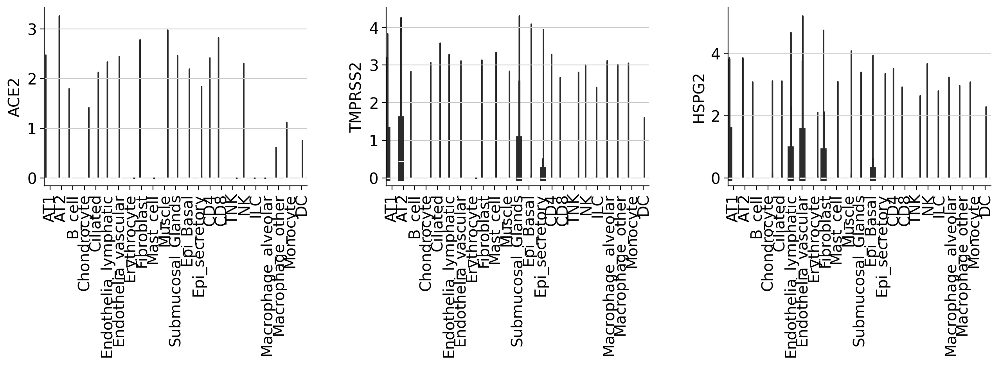

In [ ]:
with rc_context({"figure.figsize": (4.5, 3)}):
    sc.pl.violin(
        adata = adata,
        # adata[(adata.obs["disease"] == "normal") & (adata.obs["tissue"] == "lung parenchyma") & (adata.obs["Celltypes"].isin(filtered_Celltypess))],
        keys=["ACE2", "TMPRSS2","HSPG2"],
        groupby="Celltypes_master_higher_immune",
        # use_raw=False,layer="soupX",
        stripplot=False,  # remove the internal dots
        inner="box",  # adds a boxplot inside violins
        rotation = 90
    )

In [ ]:
adata[adata.obs["Celltypes_master_higher"]=="Epithelia"]

View of AnnData object with n_obs × n_vars = 51806 × 1147
    obs: 'Celltypes', 'Celltypes_master_high', 'Celltypes_master_higher', 'Celltypes_master_higher_immune', 'Loc_true', 'Material', 'Donor', 'Donor_ID_2', 'Gender', 'Sample', 'ID', 'Protocol_plot', 'Version', 'Study', 'PoolDon', 'DonorPool', 'scDonor_snBatch', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'mt', 'gene_ids-0', 'n_cells-0', 'n_cells_by_counts-0', 'mean_counts-0', 'pct_dropout_by_counts-0', 'total_counts-0', 'gene_ids-1', 'n_cells-1', 'n_cells_by_counts-1', 'mean_counts-1', 'pct_dropout_by_counts-1', 'total_counts-1', 'feature_types-1', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'Celltypes_colors', 'Celltypes_int_F_colors', 'Celltypes_int_colors', 'Celltypes_int_updB_colors', 'ID_colors', 'Loc_true_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca'

In [ ]:
adata.obs

,Celltypes,Celltypes_master_high,Celltypes_master_higher,Celltypes_master_higher_immune,Loc_true,Material,Donor,Donor_ID_2,Gender,Sample,ID,Protocol_plot,Version,Study,PoolDon,DonorPool,scDonor_snBatch,n_genes,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt
AAACCTGGTGTGAATA-1-WTDAtest7887999-0,AT1,Epithelia,Epithelia,AT1,d_LowLeftPar,cells,A32,411C,M,WTDAtest7887999,A32-LNG-1-SC-45N-1,LibCD45neg_TrypLibUndigest,10x3prime_v2,dissociation,nan,nan,A32_cells,1943,1943,5356.075684,186.790329,3.487448
AAACGGGCAACCGCCA-1-WTDAtest7887999-0,B_plasma_IgA,Immune,Immune,B_cell,d_LowLeftPar,cells,A32,411C,M,WTDAtest7887999,A32-LNG-1-SC-45N-1,LibCD45neg_TrypLibUndigest,10x3prime_v2,dissociation,nan,nan,A32_cells,226,226,768.994751,5.476773,0.712199
AACCATGGTACAGCAG-1-WTDAtest7887999-0,Monocyte_CD16,Immune,Immune,Monocyte,d_LowLeftPar,cells,A32,411C,M,WTDAtest7887999,A32-LNG-1-SC-45N-1,LibCD45neg_TrypLibUndigest,10x3prime_v2,dissociation,nan,nan,A32_cells,847,847,1901.789185,108.158295,5.687187
AACGTTGGTGTCCTCT-1-WTDAtest7887999-0,CD8_EM/EMRA,Immune,Immune,CD8,d_LowLeftPar,cells,A32,411C,M,WTDAtest7887999,A32-LNG-1-SC-45N-1,LibCD45neg_TrypLibUndigest,10x3prime_v2,dissociation,nan,nan,A32_cells,767,767,1783.324097,85.630554,4.801738
AACTCCCTCCTAGTGA-1-WTDAtest7887999-0,Macro_intravascular,Immune,Immune,Macrophage_other,d_LowLeftPar,cells,A32,411C,M,WTDAtest7887999,A32-LNG-1-SC-45N-1,LibCD45neg_TrypLibUndigest,10x3prime_v2,dissociation,nan,nan,A32_cells,799,799,1314.895386,97.600655,7.422694
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGGTTGTAATGCGG-1-WSSS_A_LNG8757929-1,T_reg,Immune,Immune,CD4,b_Bronchi.2.3,nuclei,A42,nan,nan,WSSS_A_LNG8757929,WSSS_A_LNG8757929,nuclei,nan,nan,A42,A42none,A42_nuclei,1556,1556,2975.571777,0.000000,0.000000
TTTGGTTGTGCCCTTT-1-WSSS_A_LNG8757929-1,SMG_Mucous,Epithelia,Epithelia,Submucosal_Glands,b_Bronchi.2.3,nuclei,A42,nan,nan,WSSS_A_LNG8757929,WSSS_A_LNG8757929,nuclei,nan,nan,A42,A42none,A42_nuclei,2723,2723,7334.214355,0.000000,0.000000
TTTGGTTTCAAGAGTA-1-WSSS_A_LNG8757929-1,Basal,Epithelia,Epithelia,Epi_Basal,b_Bronchi.2.3,nuclei,A42,nan,nan,WSSS_A_LNG8757929,WSSS_A_LNG8757929,nuclei,nan,nan,A42,A42none,A42_nuclei,500,500,626.389465,0.000000,0.000000
TTTGTTGAGCGAGTCA-1-WSSS_A_LNG8757929-1,SMG_Mucous,Epithelia,Epithelia,Submucosal_Glands,b_Bronchi.2.3,nuclei,A42,nan,nan,WSSS_A_LNG8757929,WSSS_A_LNG8757929,nuclei,nan,nan,A42,A42none,A42_nuclei,2576,2576,6651.600586,0.000000,0.000000


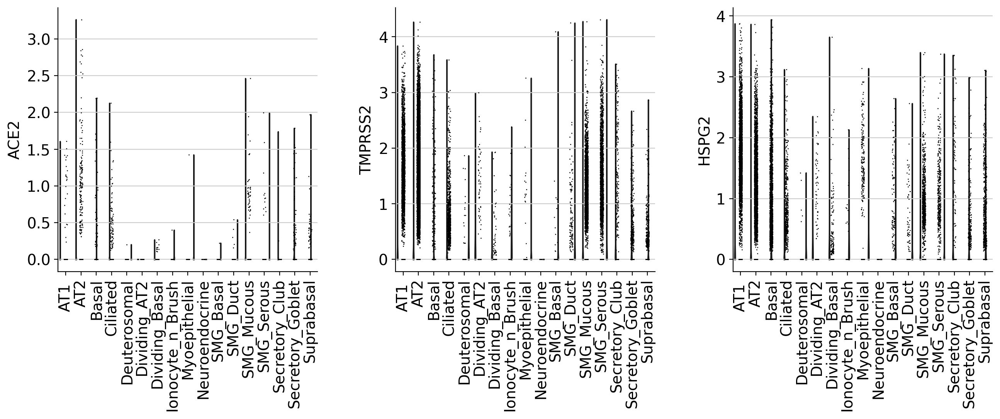

In [ ]:
with rc_context({"figure.figsize": (4.5, 4.5)}):
    sc.pl.violin(
        adata = adata[adata.obs["Celltypes_master_higher"]=="Epithelia"],
        keys=["ACE2", "TMPRSS2","HSPG2"],
        groupby="Celltypes",
        # use_raw=False,layer="soupX",
        size=1, # stripplot=False,  # remove the internal dots
        # inner="box",  # adds a boxplot inside violins
        rotation = 90,
    )

In [ ]:
adata.obs["Celltypes"].unique()

['AT1 ', 'B_plasma_IgA', 'Monocyte_CD16', 'CD8_EM/EMRA', 'Macro_intravascular', ..., 'Schwann_nonmyelinating', 'Chondrocyte', 'Schwann_Myelinating', 'Fibro_perichondrial', 'Myoepithelial']
Length: 80
Categories (80, str): ['AT1 ', 'AT2', 'B_memory', 'B_naive', ..., 'Secretory_Goblet', 'Suprabasal', 'T_reg', 'gdT']

In [ ]:
adata.obs["Celltypes"].isin(["AT1","AT2","Basal","Ciliated","Secretory_Club","Secretory_Globet","Suprabasal"])

AAACCTGGTGTGAATA-1-WTDAtest7887999-0      False
AAACGGGCAACCGCCA-1-WTDAtest7887999-0      False
AACCATGGTACAGCAG-1-WTDAtest7887999-0      False
AACGTTGGTGTCCTCT-1-WTDAtest7887999-0      False
AACTCCCTCCTAGTGA-1-WTDAtest7887999-0      False
                                          ...  
TTTGGTTGTAATGCGG-1-WSSS_A_LNG8757929-1    False
TTTGGTTGTGCCCTTT-1-WSSS_A_LNG8757929-1    False
TTTGGTTTCAAGAGTA-1-WSSS_A_LNG8757929-1     True
TTTGTTGAGCGAGTCA-1-WSSS_A_LNG8757929-1    False
TTTGTTGTCTTCTGGC-1-WSSS_A_LNG8757929-1    False
Name: Celltypes, Length: 193108, dtype: bool

In [ ]:
adata.obs["tissue_type"] = np.select(
    [
        adata.obs["Loc_true"].str.contains("Trachea",case=False,na=False),
        adata.obs["Loc_true"].str.contains("Bronchi",case=False,na=False),
        adata.obs["Loc_true"].str.contains("Par",case=False,na=False),
    ],
    ["Trachea","Bronchi","Parenchyma"],
    default="Other"
)
adata.obs["tissue_type"] = pd.Categorical(adata.obs["tissue_type"],categories=["Trachea","Bronchi","Parenchyma"])
adata.obs

,Celltypes,Celltypes_master_high,Celltypes_master_higher,Celltypes_master_higher_immune,Loc_true,Material,Donor,Donor_ID_2,Gender,Sample,ID,Protocol_plot,Version,Study,PoolDon,DonorPool,scDonor_snBatch,n_genes,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,tissue_type
AAACCTGGTGTGAATA-1-WTDAtest7887999-0,AT1,Epithelia,Epithelia,AT1,d_LowLeftPar,cells,A32,411C,M,WTDAtest7887999,A32-LNG-1-SC-45N-1,LibCD45neg_TrypLibUndigest,10x3prime_v2,dissociation,nan,nan,A32_cells,1943,1943,5356.075684,186.790329,3.487448,Parenchyma
AAACGGGCAACCGCCA-1-WTDAtest7887999-0,B_plasma_IgA,Immune,Immune,B_cell,d_LowLeftPar,cells,A32,411C,M,WTDAtest7887999,A32-LNG-1-SC-45N-1,LibCD45neg_TrypLibUndigest,10x3prime_v2,dissociation,nan,nan,A32_cells,226,226,768.994751,5.476773,0.712199,Parenchyma
AACCATGGTACAGCAG-1-WTDAtest7887999-0,Monocyte_CD16,Immune,Immune,Monocyte,d_LowLeftPar,cells,A32,411C,M,WTDAtest7887999,A32-LNG-1-SC-45N-1,LibCD45neg_TrypLibUndigest,10x3prime_v2,dissociation,nan,nan,A32_cells,847,847,1901.789185,108.158295,5.687187,Parenchyma
AACGTTGGTGTCCTCT-1-WTDAtest7887999-0,CD8_EM/EMRA,Immune,Immune,CD8,d_LowLeftPar,cells,A32,411C,M,WTDAtest7887999,A32-LNG-1-SC-45N-1,LibCD45neg_TrypLibUndigest,10x3prime_v2,dissociation,nan,nan,A32_cells,767,767,1783.324097,85.630554,4.801738,Parenchyma
AACTCCCTCCTAGTGA-1-WTDAtest7887999-0,Macro_intravascular,Immune,Immune,Macrophage_other,d_LowLeftPar,cells,A32,411C,M,WTDAtest7887999,A32-LNG-1-SC-45N-1,LibCD45neg_TrypLibUndigest,10x3prime_v2,dissociation,nan,nan,A32_cells,799,799,1314.895386,97.600655,7.422694,Parenchyma
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGGTTGTAATGCGG-1-WSSS_A_LNG8757929-1,T_reg,Immune,Immune,CD4,b_Bronchi.2.3,nuclei,A42,nan,nan,WSSS_A_LNG8757929,WSSS_A_LNG8757929,nuclei,nan,nan,A42,A42none,A42_nuclei,1556,1556,2975.571777,0.000000,0.000000,Bronchi
TTTGGTTGTGCCCTTT-1-WSSS_A_LNG8757929-1,SMG_Mucous,Epithelia,Epithelia,Submucosal_Glands,b_Bronchi.2.3,nuclei,A42,nan,nan,WSSS_A_LNG8757929,WSSS_A_LNG8757929,nuclei,nan,nan,A42,A42none,A42_nuclei,2723,2723,7334.214355,0.000000,0.000000,Bronchi
TTTGGTTTCAAGAGTA-1-WSSS_A_LNG8757929-1,Basal,Epithelia,Epithelia,Epi_Basal,b_Bronchi.2.3,nuclei,A42,nan,nan,WSSS_A_LNG8757929,WSSS_A_LNG8757929,nuclei,nan,nan,A42,A42none,A42_nuclei,500,500,626.389465,0.000000,0.000000,Bronchi
TTTGTTGAGCGAGTCA-1-WSSS_A_LNG8757929-1,SMG_Mucous,Epithelia,Epithelia,Submucosal_Glands,b_Bronchi.2.3,nuclei,A42,nan,nan,WSSS_A_LNG8757929,WSSS_A_LNG8757929,nuclei,nan,nan,A42,A42none,A42_nuclei,2576,2576,6651.600586,0.000000,0.000000,Bronchi


In [ ]:
from itertools import product
# https://www.nature.com/articles/s41586-022-04474-x/figures/11
genes_of_interest = ["ACE2", "TMPRSS2","HSPG2"] 

ncols = 3
nrows = 3
figsize =5
wspace = 0.5

fig, axs = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(ncols * figsize + figsize * wspace * (ncols - 1), nrows * figsize),
)
plt.subplots_adjust(wspace=wspace,hspace=1)
# This produces two Axes objects in a single Figure
print("axes:", axs)
for (i,tissue), (j,gene) in product(enumerate(adata.obs["tissue_type"].cat.categories),enumerate(genes_of_interest)):
    ax = axs[i][j]

    sc.pl.violin(
            adata = adata[
                (adata.obs["Celltypes_master_higher"]=="Epithelia") &
                (adata.obs["Celltypes"].isin(["AT1 ","AT2","Basal","Ciliated","Secretory_Club","Secretory_Goblet","Suprabasal"])) &
                (adata.obs["tissue_type"]==tissue)
                ],
            keys=gene,
            groupby="Celltypes",
            # use_raw=False,layer="soupX",
            size=0.5, # stripplot=False,  # remove the internal dots
            # inner="box",  # adds a boxplot inside violins
            rotation = 90,
            ax=ax,
            show=False
        )
    ax.set_title(tissue)
fig = plt.gcf() # get current figure
fig.suptitle(f"Lung epithelial cells", fontsize=14, fontweight="bold",x=0.5, y=0.95)
fig.savefig("figures/lung/lung_violin_plot.pdf",dpi=300,bbox_inches='tight')
plt.close()

axes: [[<Axes: > <Axes: > <Axes: >]
 [<Axes: > <Axes: > <Axes: >]
 [<Axes: > <Axes: > <Axes: >]]


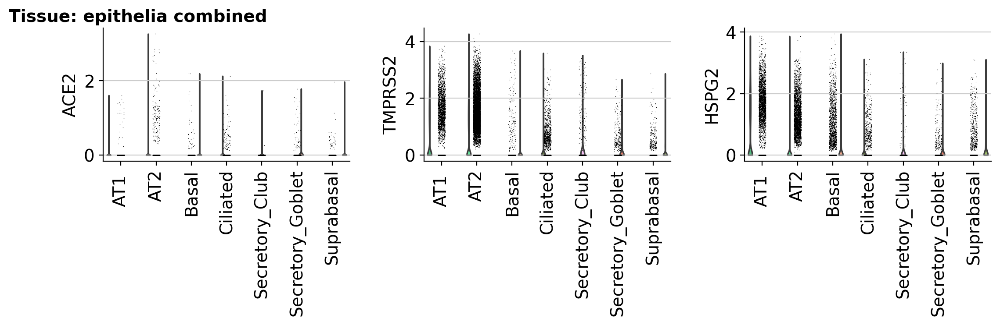

In [ ]:
with rc_context({"figure.figsize": (4, 2)}):
    axes = sc.pl.violin(
        adata = adata[
            (adata.obs["Celltypes_master_higher"]=="Epithelia") &
            (adata.obs["Celltypes"].isin(["AT1 ","AT2","Basal","Ciliated","Secretory_Club","Secretory_Goblet","Suprabasal"]))
            ],
        keys=["ACE2", "TMPRSS2","HSPG2"],
        groupby="Celltypes",
        # use_raw=False,layer="soupX",
        size=0.5, # stripplot=False,  # remove the internal dots
        # inner="box",  # adds a boxplot inside violins
        rotation = 90,
        show=False
    )
    fig = plt.gcf() # get current figure
    fig.suptitle(f"Tissue: epithelia combined", fontsize=14, fontweight="bold",x=0.1, y=1.02)
    plt.show()

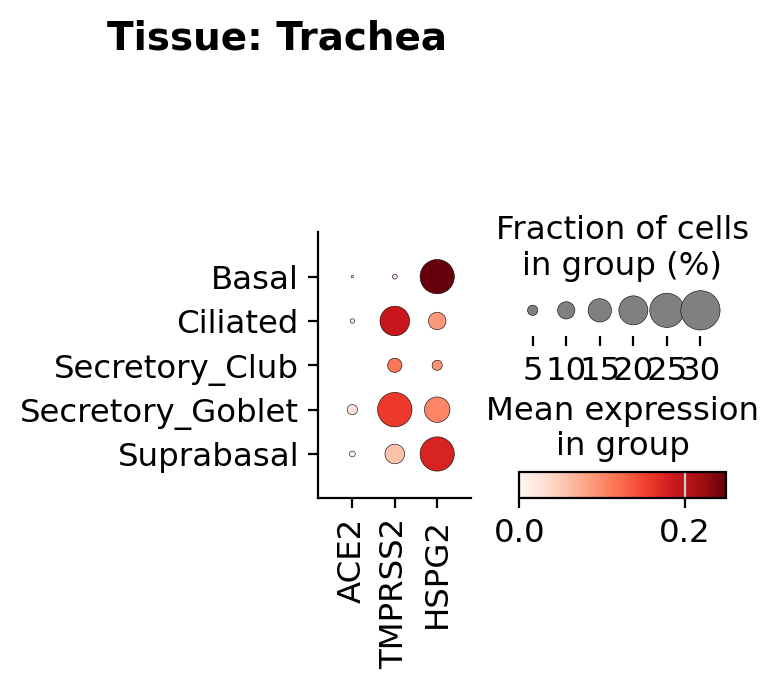

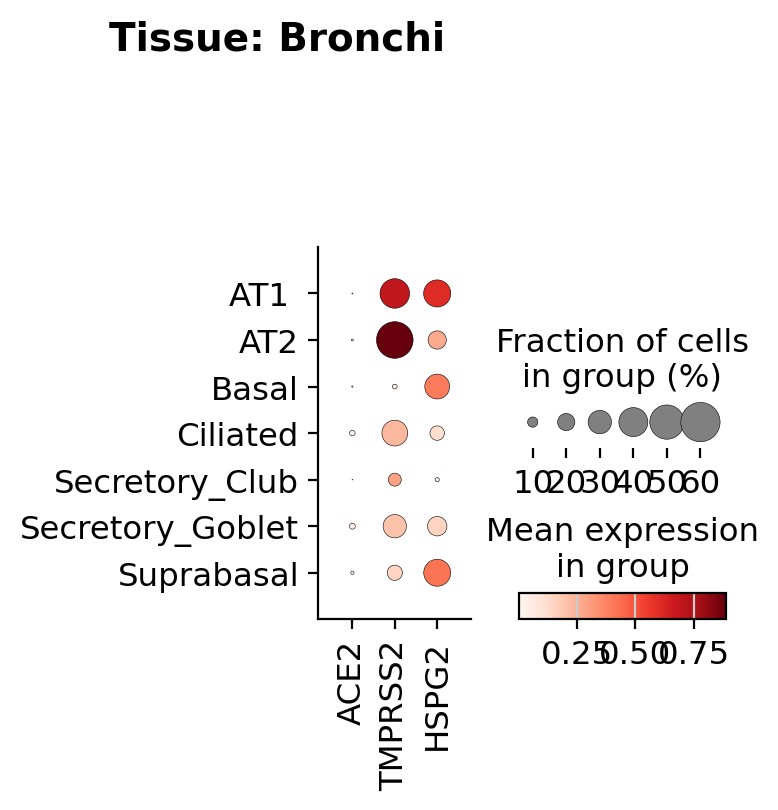

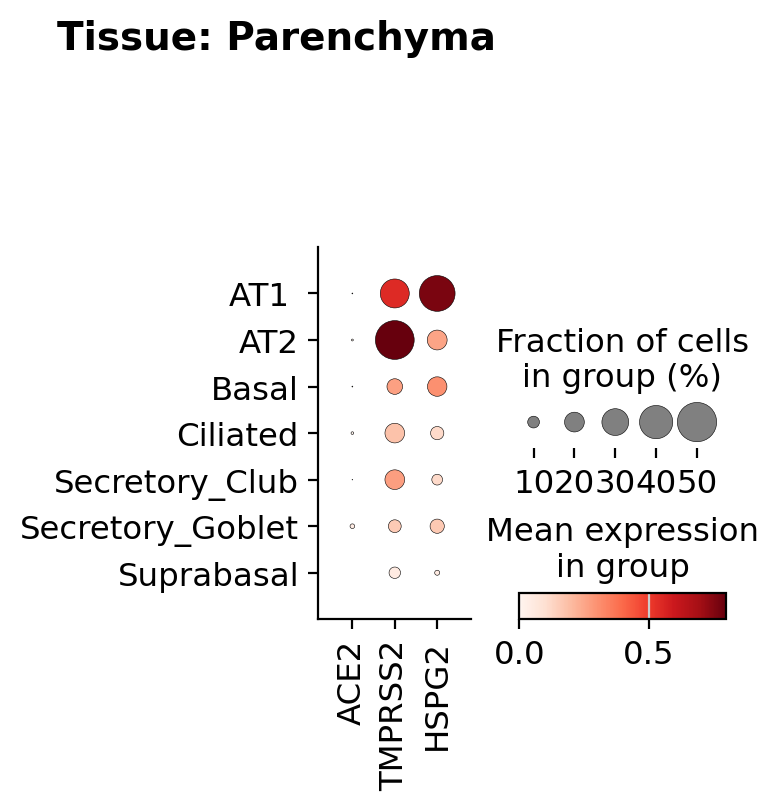

In [ ]:
for tissue in adata.obs["tissue_type"].cat.categories:
    with rc_context({"figure.figsize": (3,1)}):
        axes = sc.pl.dotplot(
            adata = adata[
                (adata.obs["Celltypes_master_higher"]=="Epithelia") &
                (adata.obs["Celltypes"].isin(["AT1 ","AT2","Basal","Ciliated","Secretory_Club","Secretory_Goblet","Suprabasal"])) &
                (adata.obs["tissue_type"]==tissue)
                ],
            var_names=["ACE2", "TMPRSS2","HSPG2"],
            groupby="Celltypes",
            show=False
        )
        fig = plt.gcf() # get current figure
        fig.suptitle(f"Tissue: {tissue}", fontsize=14, fontweight="bold",x=0.1, y=1.02)
        plt.show()

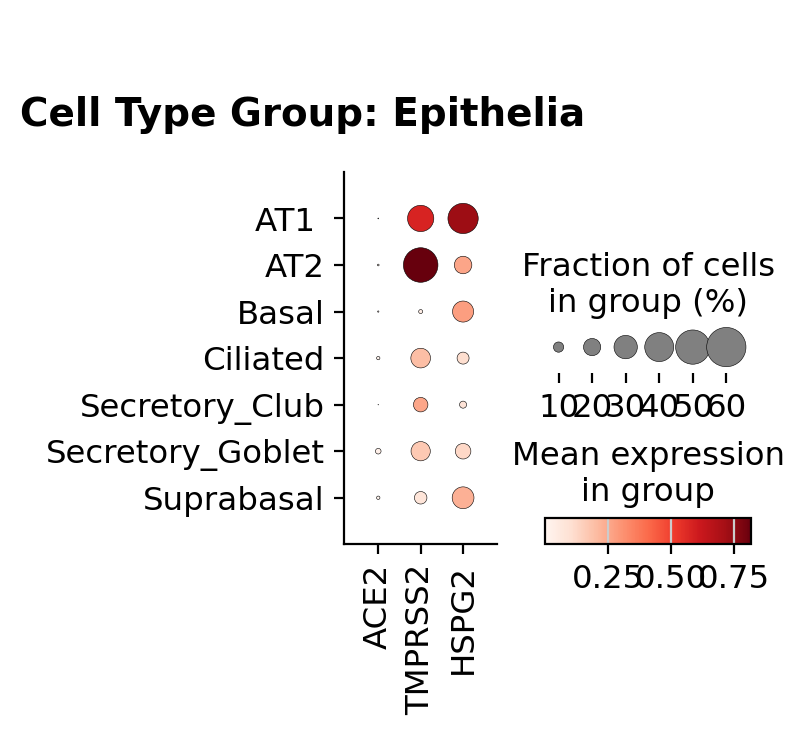

In [ ]:
with rc_context({"figure.figsize": (6,2)}):
    axes = sc.pl.dotplot(
        adata = adata[
            (adata.obs["Celltypes_master_higher"]=="Epithelia") &
            (adata.obs["Celltypes"].isin(["AT1 ","AT2","Basal","Ciliated","Secretory_Club","Secretory_Goblet","Suprabasal"]))
            ],
        var_names=["ACE2", "TMPRSS2","HSPG2"],
        groupby="Celltypes",
        show=False,)
    fig = plt.gcf() # get current figure
    fig.suptitle(f"Cell Type Group: Epithelia", fontsize=14, fontweight="bold",x=0.1, y=0.8)
    fig.savefig("figures/lung/lung_dotplot.pdf",dpi=300,bbox_inches='tight')

In [ ]:
adata.obs[adata.obs["Celltypes_master_higher"].isna()]

,Celltypes,Celltypes_master_high,Celltypes_master_higher,Celltypes_master_higher_immune,Loc_true,Material,Donor,Donor_ID_2,Gender,Sample,ID,Protocol_plot,Version,Study,PoolDon,DonorPool,scDonor_snBatch,n_genes,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,tissue_type
AAACGAAAGTAGGATT-1-HCA_A_LNG9387709-1,SMG_Mucous,Epithelia,NaN,Submucosal_Glands,b_Bronchi.2.3,nuclei,A47,nan,nan,HCA_A_LNG9387709,HCA_A_LNG9387709,nuclei,nan,nan,Pool1,A47Pool1,Pool1,509,509,663.904358,2.250843,0.339031,Bronchi
AAAGTGACACTACACA-1-HCA_A_LNG9387709-1,AT2,Epithelia,NaN,AT2,e_TopLeftPar,nuclei,A48,nan,nan,HCA_A_LNG9387709,HCA_A_LNG9387709,nuclei,nan,nan,Pool1,A48Pool1,Pool1,2905,2905,6317.049805,1.979164,0.031331,Parenchyma
AAAGTGATCTCGTCAC-1-HCA_A_LNG9387709-1,AT2,Epithelia,NaN,AT2,e_TopLeftPar,nuclei,A48,nan,nan,HCA_A_LNG9387709,HCA_A_LNG9387709,nuclei,nan,nan,Pool1,A48Pool1,Pool1,2023,2023,3822.034180,24.188694,0.632875,Parenchyma
AACAAAGGTGAGTTTC-1-HCA_A_LNG9387709-1,Secretory_Club,Epithelia,NaN,Epi_secretory,e_TopLeftPar,nuclei,A48,nan,nan,HCA_A_LNG9387709,HCA_A_LNG9387709,nuclei,nan,nan,Pool1,A48Pool1,Pool1,728,728,905.957825,0.718927,0.079355,Parenchyma
AACCATGGTCTACAAC-1-HCA_A_LNG9387709-1,Secretory_Club,Epithelia,NaN,Epi_secretory,e_TopLeftPar,nuclei,A48,nan,nan,HCA_A_LNG9387709,HCA_A_LNG9387709,nuclei,nan,nan,Pool1,A48Pool1,Pool1,1299,1299,2071.966553,1.615932,0.077990,Parenchyma
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TGCGGCAGTGGGATTG-1-WSSS_A_LNG8757929-1,SMG_Duct,Epithelia,NaN,Submucosal_Glands,b_Bronchi.2.3,nuclei,A42,nan,nan,WSSS_A_LNG8757929,WSSS_A_LNG8757929,nuclei,nan,nan,A42,A42none,A42_nuclei,2768,2768,5751.869141,0.000000,0.000000,Bronchi
TGCTTGCCACAGGATG-1-WSSS_A_LNG8757929-1,SMG_Duct,Epithelia,NaN,Submucosal_Glands,b_Bronchi.2.3,nuclei,A42,nan,nan,WSSS_A_LNG8757929,WSSS_A_LNG8757929,nuclei,nan,nan,A42,A42none,A42_nuclei,2827,2827,6380.427734,0.000000,0.000000,Bronchi
TGGGATTAGTAACCGG-1-WSSS_A_LNG8757929-1,Neuroendocrine,Epithelia,NaN,Epi_secretory,b_Bronchi.2.3,nuclei,A42,nan,nan,WSSS_A_LNG8757929,WSSS_A_LNG8757929,nuclei,nan,nan,A42,A42none,A42_nuclei,3928,3928,9011.415039,0.399624,0.004435,Bronchi
TTCCTAATCCGACATA-1-WSSS_A_LNG8757929-1,SMG_Duct,Epithelia,NaN,Submucosal_Glands,b_Bronchi.2.3,nuclei,A42,nan,nan,WSSS_A_LNG8757929,WSSS_A_LNG8757929,nuclei,nan,nan,A42,A42none,A42_nuclei,1141,1141,1834.188354,0.000000,0.000000,Bronchi


In [ ]:
conditions = [
    adata.obs["Loc_true"] == "a_Trachea",
    adata.obs["Loc_true"].isin(["b_Bronchi.2.3", "c_Bronchi.4"]),
    adata.obs["Loc_true"].isin(["d_LowLeftPar", "e_TopLeftPar"]),
]

choices = [
    "Trachea",
    "Bronchi",
    "Lung Parenchyma"
]
adata.obs["sample_location"] = np.select(conditions, choices, default="Other")
adata.obs["sample_location"] = adata.obs["sample_location"].astype("category").cat.reorder_categories(choices,ordered=True)
adata.uns["sample_location_colors"] = ['#8b5a00', '#cd8500', '#eecfa1']

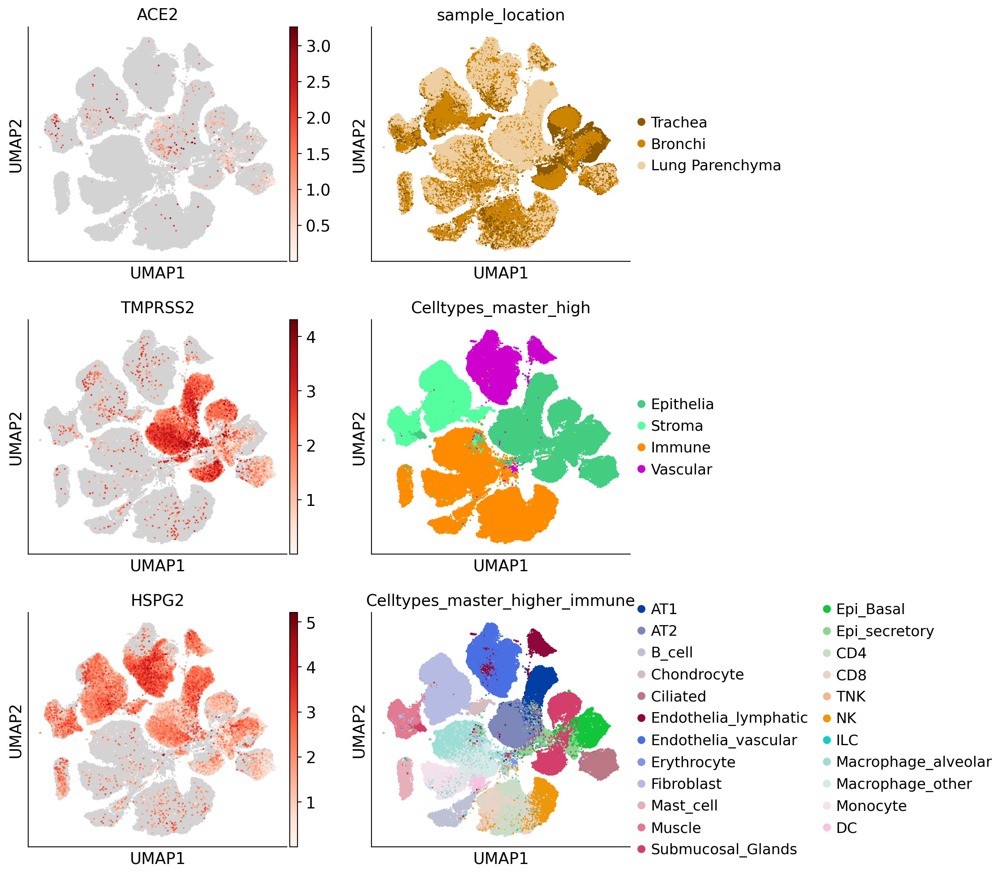

In [ ]:
with rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(
        adata = adata,
        color = [
            "ACE2","sample_location",
            "TMPRSS2","Celltypes_master_high",
            "HSPG2","Celltypes_master_higher_immune",
            ],
        ncols=2,size=10,
        use_raw=True,
        color_map=reds,vmin=0.00001,
        show=False
        # layer="soupX",
    )
plt.savefig("figures/lung/lung_umap_plot.pdf",dpi=300,bbox_inches='tight')

/home/mark/miniconda3/envs/decoupler/lib/python3.12/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


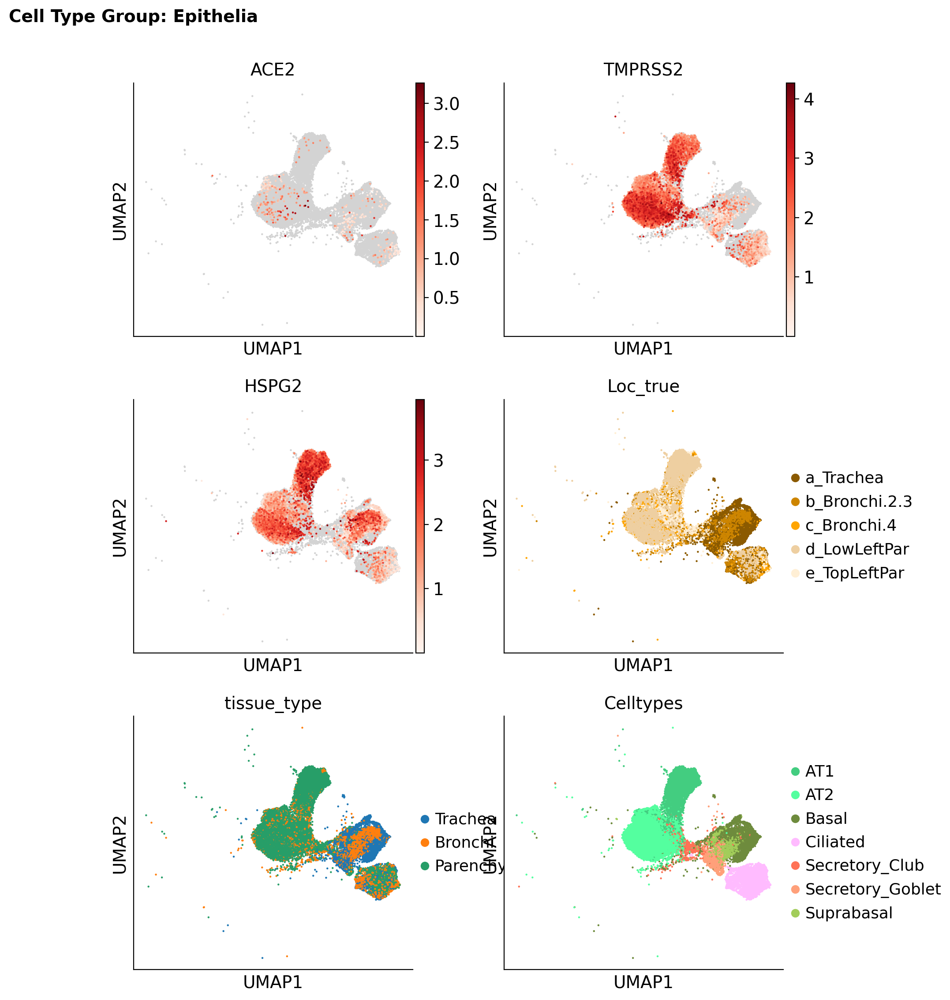

In [ ]:
with rc_context({"figure.figsize": (4, 4)}):
    axes = sc.pl.umap(
        adata = adata[
            (adata.obs["Celltypes_master_higher"]=="Epithelia") &
            (adata.obs["Celltypes"].isin(["AT1 ","AT2","Basal","Ciliated","Secretory_Club","Secretory_Goblet","Suprabasal"]))
            ],
        color = [
            "ACE2", "TMPRSS2","HSPG2","Loc_true","tissue_type",
            "Celltypes"
            ],
        ncols=2,size=10,
        use_raw=True,
        color_map=reds,vmin=0.00001,
        show =False
        # layer="soupX",
    )
    fig = plt.gcf() # get current figure
    fig.suptitle(f"Cell Type Group: Epithelia", fontsize=14, fontweight="bold",x=0.1, y=0.95)
    plt.show()

In [ ]:
adata_Bo = adata[
            (adata.obs["Celltypes_master_higher"]=="Epithelia") &
            (adata.obs["Celltypes"].isin(["AT1 ","AT2","Basal","Ciliated","Secretory_Club","Secretory_Goblet","Suprabasal"]))
            ]

In [ ]:
expr_genes = ["ACE2","TMPRSS2","HSPG2"]

expr_df = pd.DataFrame(adata_Bo.raw[:,expr_genes].X.toarray(),
             columns=expr_genes,
             index = adata_Bo.obs_names)
expr_df = expr_df.join(adata_Bo.obs["Celltypes"])
expr_df

,ACE2,TMPRSS2,HSPG2,Celltypes
AAACCTGGTGTGAATA-1-WTDAtest7887999-0,0.0,1.014165,0.000000,AT1
AACTTTCCAAGCCGTC-1-WTDAtest7887999-0,0.0,0.000000,1.653960,AT1
AATCGGTGTAGCGCAA-1-WTDAtest7887999-0,0.0,0.000000,0.000000,AT2
ACATCAGGTGAGTGAC-1-WTDAtest7887999-0,0.0,0.000000,0.787203,AT2
ACATCAGGTTCGCGAC-1-WTDAtest7887999-0,0.0,0.000000,0.000000,AT1
...,...,...,...,...
TTTCATGAGAGAATCT-1-WSSS_A_LNG8757929-1,0.0,0.000000,2.428370,Basal
TTTGACTCAACCACAT-1-WSSS_A_LNG8757929-1,0.0,0.737461,0.000000,Ciliated
TTTGATCGTATCCTTT-1-WSSS_A_LNG8757929-1,0.0,0.000000,0.000000,Basal
TTTGGAGTCCATCTCG-1-WSSS_A_LNG8757929-1,0.0,0.000000,1.702689,Suprabasal


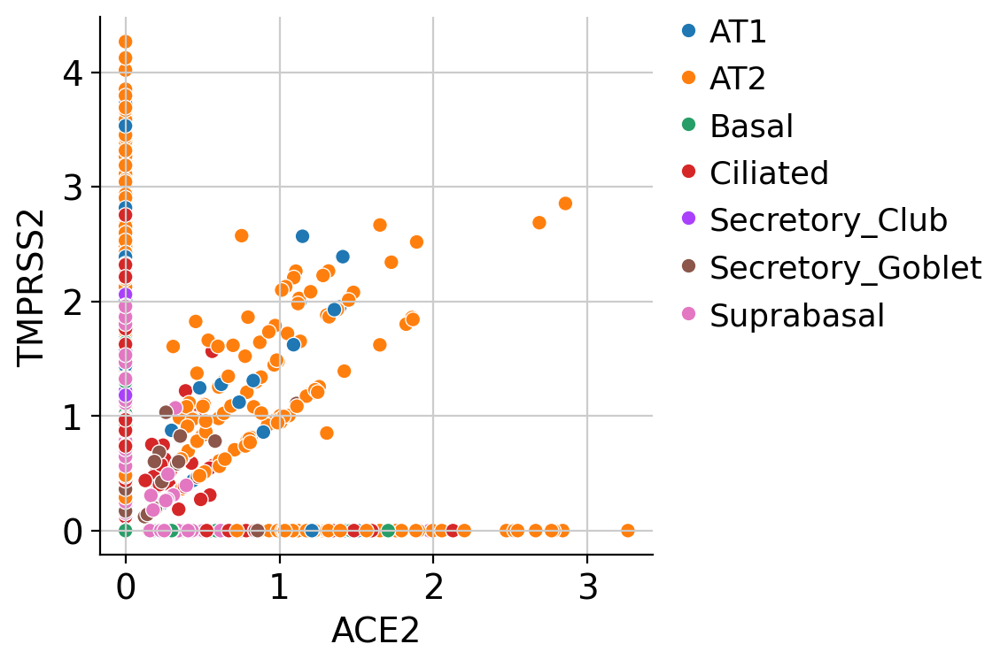

In [ ]:
sns.scatterplot(
    data = expr_df,
    x="ACE2",y="TMPRSS2",
    hue = "Celltypes"
)
# Move legend outside the plot
plt.legend(
    bbox_to_anchor=(1.05, 1),   # position legend to the right of plot
    loc="upper left",
    borderaxespad=0
)
plt.savefig("figures/lung/lung_ACE2_VS_TMPRSS2.pdf", dpi=300, bbox_inches='tight')

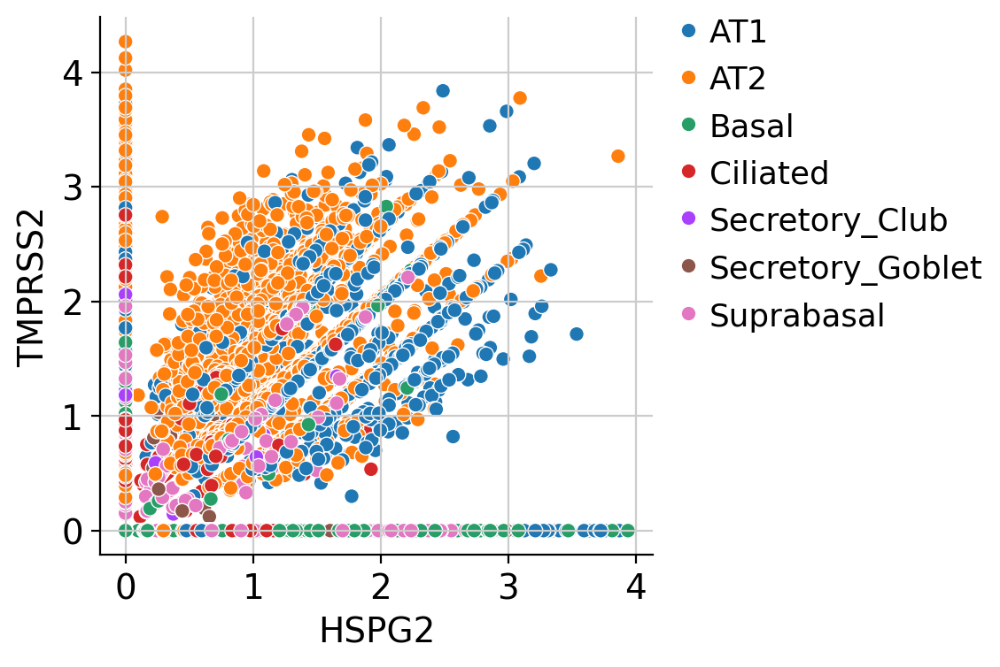

In [ ]:
sns.scatterplot(
    data = expr_df,
    x="HSPG2",y="TMPRSS2",
    hue = "Celltypes"
)
# Move legend outside the plot
plt.legend(
    bbox_to_anchor=(1.05, 1),   # position legend to the right of plot
    loc="upper left",
    borderaxespad=0
)
plt.savefig("lung_HSPG2_VS_TMPRSS2.pdf", dpi=300, bbox_inches='tight')

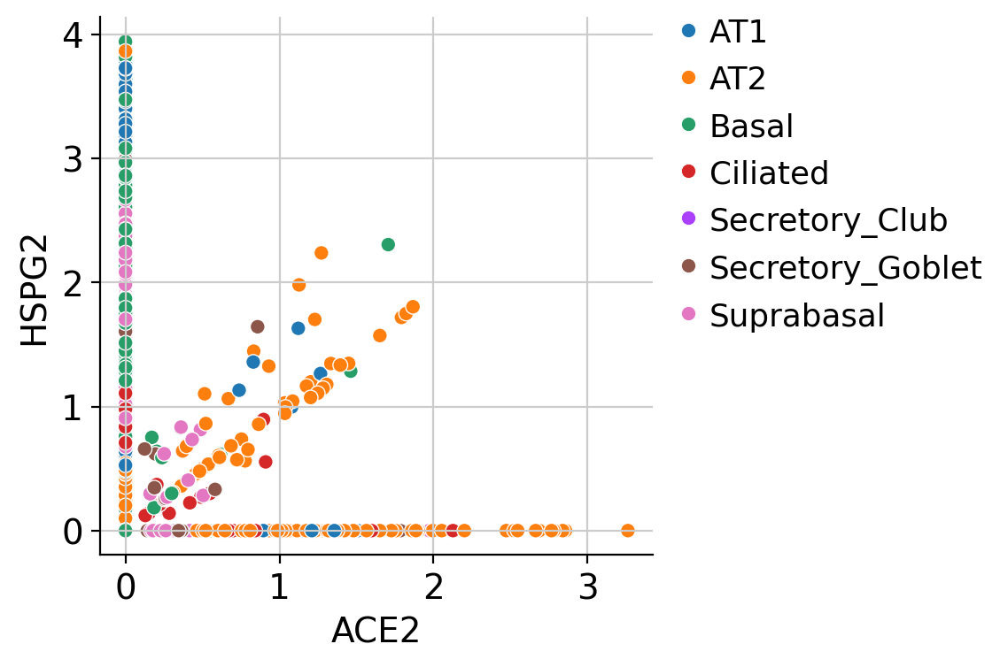

In [ ]:
sns.scatterplot(
    data = expr_df,
    x="ACE2",y="HSPG2",
    hue = "Celltypes"
)
# Move legend outside the plot
plt.legend(
    bbox_to_anchor=(1.05, 1),   # position legend to the right of plot
    loc="upper left",
    borderaxespad=0
)
plt.savefig("figures/lung/lung_HSPG2_VS_ACE2.pdf", dpi=300, bbox_inches='tight')

## Age specific nasal epithelial response to SARS-CoV-2 infection 
Woodall et al. Nat. Micro 2024

Extended Data fig. 6 - Could the increased basoloid-like cell in COVID-19 older adult patients be an underlying cause of increased vulnerability?

In [ ]:
Woodall_url = config["data"]["Woodall_NatMicro2024"]["in_vivo"]["h5ad_url"]
Woodall_path = "data/COVID_cell_atlas/in_vivo_object_cxg_with_raw_counts.h5ad"
get_h5ad(Woodall_url,Woodall_path)
woodall_adata = sc.read(Woodall_path)
woodall_adata

already downloaded.


AnnData object with n_obs × n_vars = 577234 × 17591
    obs: 'age_group', 'age_harmonised', 'age_status', 'file_of_origin', 'author_ann_harmonised', 'author_ann_harmonised_broad', 'donor_harmonised', 'age_status_granular', 'score_IFN_alpha', 'score_IFN_gamma', 'score_EMT', 'score_BASALOID', 'annotation_v1', 'status'
    var: 'featureid-0', 'gene_ids-1', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'age_status_colors', 'annotation_v1_colors'
    obsm: 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [ ]:
woodall_adata.obs

,age_group,age_harmonised,age_status,file_of_origin,author_ann_harmonised,author_ann_harmonised_broad,donor_harmonised,age_status_granular,score_IFN_alpha,score_IFN_gamma,score_EMT,score_BASALOID,annotation_v1,status
Delorey_2021_COVID_only.h5ad:02-P005175-S053-R01-AATCACGAGGGTCACA,old_adult,60-65,elderly-COVID19,Delorey_2021_COVID_only.h5ad,Secretory,Secretory,D1,old_adult-COVID19,-0.077939,0.068120,0.157006,0.418843,AT2,COVID19
Delorey_2021_COVID_only.h5ad:02-P005175-S053-R01-GGTAACTAGTCCTACA,old_adult,60-65,elderly-COVID19,Delorey_2021_COVID_only.h5ad,AT1,AT1,D1,old_adult-COVID19,0.024214,0.111761,0.179795,0.310751,AT1,COVID19
Delorey_2021_COVID_only.h5ad:02-P005175-S053-R01-CATCCGTTCGCAAGAG,old_adult,60-65,elderly-COVID19,Delorey_2021_COVID_only.h5ad,KRT8+ PATS/ADI/DATPs,KRT8+ PATS/ADI/DATPs,D1,old_adult-COVID19,-0.038762,0.155381,0.258357,0.716596,AT2,COVID19
Delorey_2021_COVID_only.h5ad:02-P005175-S053-R01-TTCGGTCAGCTTTCCC,old_adult,60-65,elderly-COVID19,Delorey_2021_COVID_only.h5ad,KRT8+ PATS/ADI/DATPs,KRT8+ PATS/ADI/DATPs,D1,old_adult-COVID19,0.296413,0.208366,0.236939,0.714845,AT2,COVID19
Delorey_2021_COVID_only.h5ad:02-P005175-S053-R01-TTAGGCATCCTCACTG,old_adult,60-65,elderly-COVID19,Delorey_2021_COVID_only.h5ad,Secretory,Secretory,D1,old_adult-COVID19,0.139501,0.097040,0.138514,0.361797,AT2,COVID19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Melms_2021.h5ad:AGCTTCCAGGCATGCA-1_27,old_adult,58.0,elderly-COVID19,Melms_2021.h5ad,ECM-high epithelial,ECM-high epithelial,L22cov,old_adult-COVID19,-0.078560,0.026703,0.227514,-0.100314,AT2,COVID19
Melms_2021.h5ad:GCACGGTCAGAAGTTA-1_27,old_adult,58.0,elderly-COVID19,Melms_2021.h5ad,AT2,AT2,L22cov,old_adult-COVID19,0.279772,0.033921,-0.060741,-0.086155,Goblet/Secretory,COVID19
Melms_2021.h5ad:TTGTGGATCATAGGCT-1_27,old_adult,58.0,elderly-COVID19,Melms_2021.h5ad,AT2,AT2,L22cov,old_adult-COVID19,-0.066474,0.053662,-0.058798,-0.056902,AT2,COVID19
Melms_2021.h5ad:GCCGATGAGTAAACGT-1_27,old_adult,58.0,elderly-COVID19,Melms_2021.h5ad,AT2,AT2,L22cov,old_adult-COVID19,-0.090820,0.002190,0.127114,0.035694,Goblet/Secretory,COVID19


In [ ]:
woodall_adata.var[woodall_adata.var['featureid-0'].str.contains("SARS")]

,featureid-0,gene_ids-1,highly_variable,means,dispersions,dispersions_norm
SARS,SARS,ENSG00000031698,False,0.469940,1.652668,-0.606461
SARS2,SARS2,ENSG00000104835,False,0.082744,1.578136,-0.984576


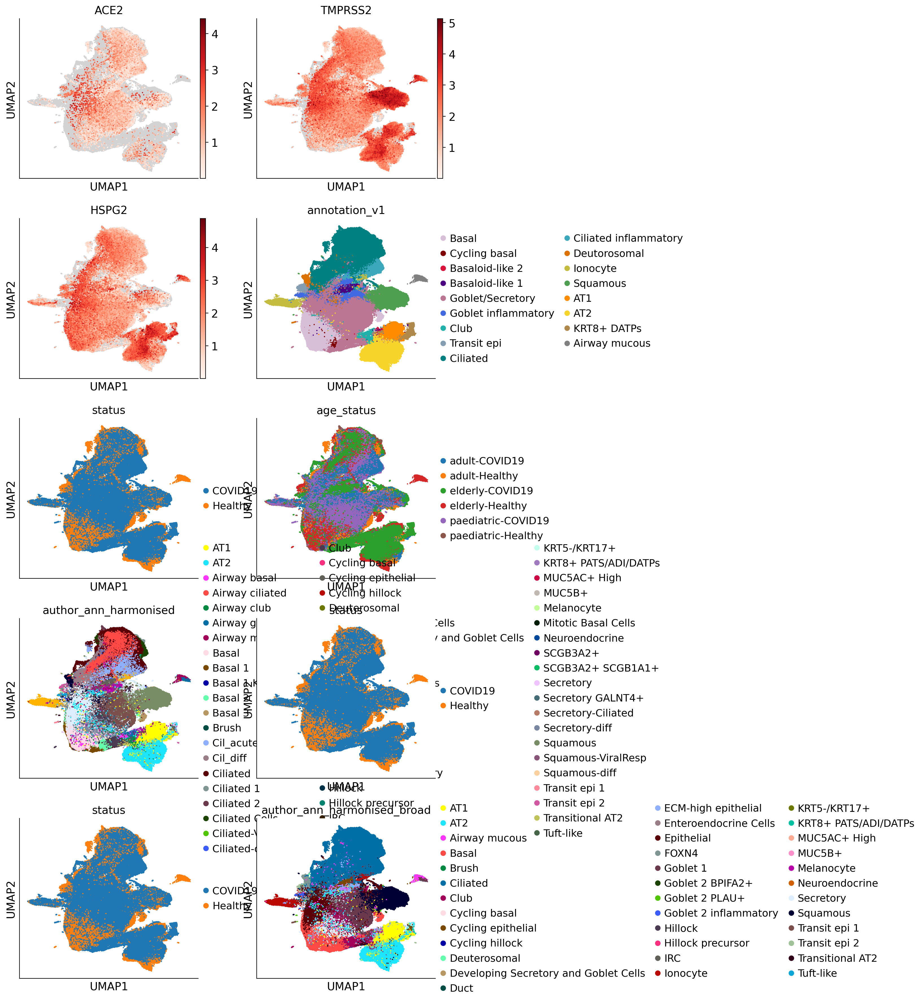

In [ ]:
with rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(
        adata = woodall_adata,
        color = [
            "ACE2", "TMPRSS2","HSPG2",
            "annotation_v1","status","age_status",
            "author_ann_harmonised","status",
            "status","author_ann_harmonised_broad"
            ],
        ncols=2,size=10,
        use_raw=False,
        color_map=reds,vmin=0.00001,
        show=False
        # layer="soupX",
    )
plt.savefig("figures/lung/woodall_umap_plot.pdf",dpi=300,bbox_inches='tight')

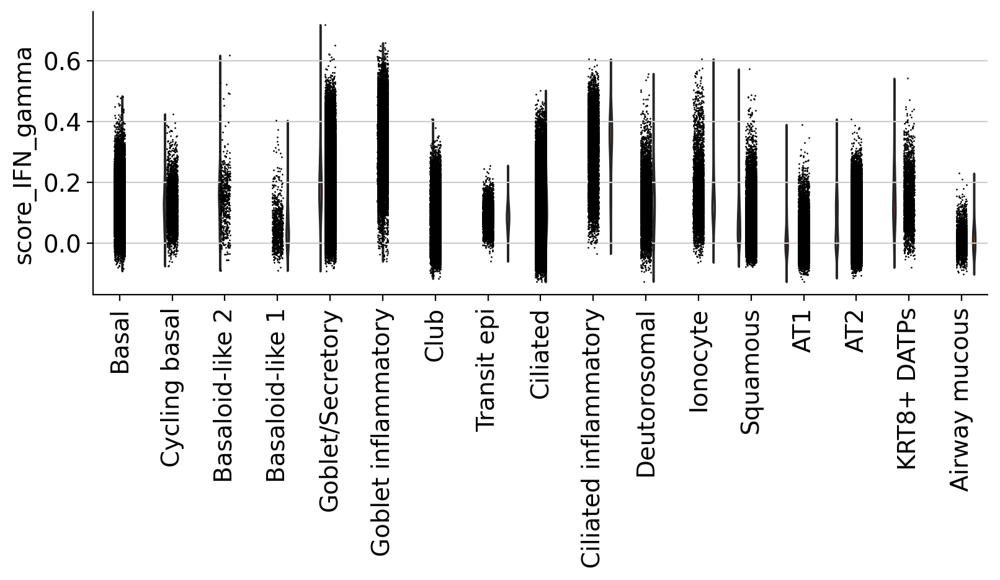

In [ ]:
# violin plot like Fig.3b
with rc_context({"figure.figsize": (8, 3)}):
    sc.pl.violin(
        adata = woodall_adata,
        keys = ["score_IFN_gamma"],
            groupby="annotation_v1",
        use_raw=False,show=False, rotation=90)

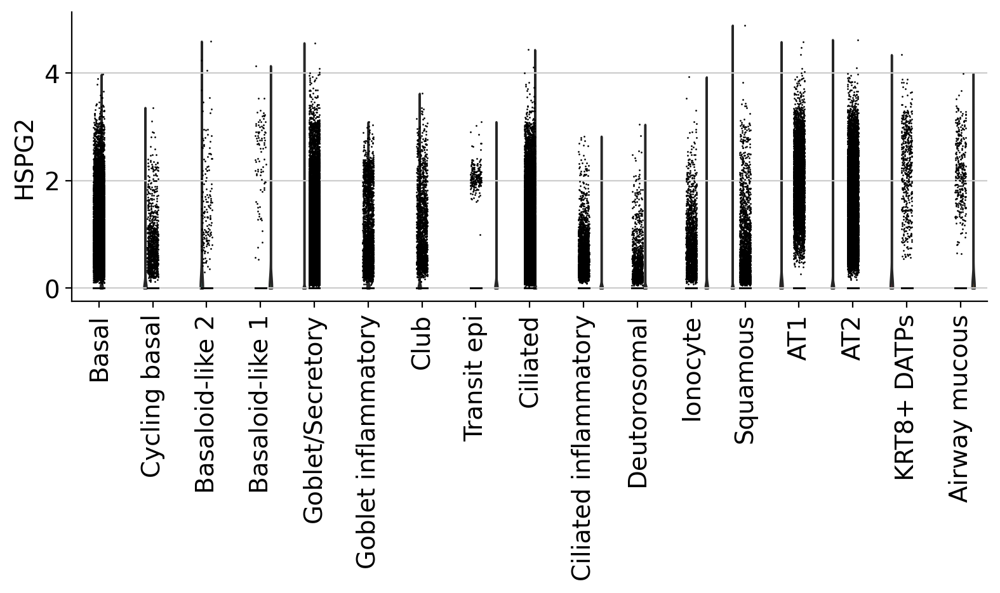

In [ ]:
# note higher HSPG2 in basaloid-like 2 cells? Which increased ITGB6 production and enhanced viral pathogenesis 
with rc_context({"figure.figsize": (8, 3)}):
    sc.pl.violin(
        adata = woodall_adata,
        keys = ["HSPG2"],
            groupby="annotation_v1",
        use_raw=False,show=False, rotation=90)

In [ ]:
woodall_adata.obs[["age_harmonised","age_status"]].value_counts()

age_harmonised  age_status        
21.0            adult-COVID19         15591
30              adult-Healthy         13512
70y             elderly-COVID19       12542
16 years        paediatric-Healthy    12391
71.0            elderly-COVID19       10730
                                      ...  
NA              adult-COVID19             0
                paediatric-Healthy        0
                paediatric-COVID19        0
                adult-Healthy             0
                elderly-Healthy           0
Name: count, Length: 972, dtype: int64

### in vitro data

In [11]:
Woodall_inVitro_url = config["data"]["Woodall_NatMicro2024"]["in_vitro"]["h5ad_url"]
Woodall_inVitro_path = config["data"]["Woodall_NatMicro2024"]["in_vitro"]["h5ad_path"]
Woodall_inVitro_raw_url = config["data"]["Woodall_NatMicro2024"]["in_vitro"]["raw_h5ad_url"]
Woodall_inVitro_raw_path = config["data"]["Woodall_NatMicro2024"]["in_vitro"]["raw_h5ad_path"]
# get_h5ad(Woodall_inVitro_url,Woodall_inVitro_path)
get_h5ad(Woodall_inVitro_raw_url,Woodall_inVitro_raw_path)
Woodall_inVitro_adata = sc.read(Woodall_inVitro_path)
Woodall_inVitro_adata

already downloaded.


AnnData object with n_obs × n_vars = 139598 × 26447
    obs: 'sample', 'treatment', 'time', 'pool', 'sample_name', 'kit_version', 'spike-in_primer', 'scrublet_score', 'doublet_bh_pval', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'souporcell_cluster', 'donor_id', 'age_group', 'gender', 'S_score', 'G2M_score', 'phase', 'bbknn_batch', 'cell_annotation', 'age_treatment', 'score_IFN_alpha', 'score_IFN_gamma', 'score_BASALOID'
    var: 'gene_ids', 'n_counts', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'ribo'
    uns: 'age_group_colors', 'age_treatment_colors', 'cell_annotation_colors', 'donor_id_colors', 'kit_version_colors', 'pool_colors', 'sample_colors', 'spike-in_primer_colors', 'treatment_colors'
    obsm: 'X_pca', 'X_umap'
    obsp: 'connectivities', 'distances'

In [6]:
Woodall_inVitro_adata_mock = Woodall_inVitro_adata[Woodall_inVitro_adata.obs["time"] == "4h"].copy()
Woodall_inVitro_adata_mock

NameError: name 'Woodall_inVitro_adata' is not defined

In [ ]:
# Woodall_inVitro_raw_adata = sc.read(Woodall_inVitro_raw_path)
# # Subset raw cells to match processed obs_names
# cells_mask = np.isin(Woodall_inVitro_raw_adata.obs_names, Woodall_inVitro_adata.obs_names)
# raw_sub = Woodall_inVitro_raw_adata[cells_mask].X.copy()

# # Subset raw genes to match processed var_names
# genes_mask = np.isin(Woodall_inVitro_raw_adata.var_names, Woodall_inVitro_adata.var_names)
# raw_sub = raw_sub[:, genes_mask]

# # Assign
# Woodall_inVitro_adata.layers["raw_counts"] = raw_sub

### pseudobulking

#### compare paediatric goblet 2 inflammatory vs goblet 2 PLAU+

In [12]:
Woodall_inVitro_adata_sub = Woodall_inVitro_adata[
    Woodall_inVitro_adata.obs["cell_annotation"].isin(["Goblet 2 PLAU+","Goblet 2 inflammatory"]) &
    # woodall_adata.obs["age_status"].isin(["paediatric-Healthy","paediatric-COVID19"])
    Woodall_inVitro_adata.obs["age_group"].isin(["Paediatric"]) &
    Woodall_inVitro_adata.obs["time"].isin(["72h"])
    ].copy()
# Woodall_inVitro_adata_sub.X = Woodall_inVitro_adata_sub.layers["raw_counts"]

In [ ]:
woodall_pb = dc.pp.pseudobulk(
    adata = Woodall_inVitro_adata_sub,
    sample_col = "cell_annotation",
    groups_col = "sample_name",
    layer = "raw_counts",
    mode = "sum",
    # min_cells = 10,
    # min_counts = 10
)
# woodall_pb.layers['raw_counts'] = woodall_pb.X.copy()
# sc.pp.normalize_total(woodall_pb, target_sum=1e4)
# sc.pp.log1p(woodall_pb)
# sc.pp.scale(woodall_pb, max_value=10)
# sc.tl.pca(woodall_pb)
# # Return raw counts to X
# dc.swap_layer(woodall_pb, 'raw_counts', X_layer_key=None, inplace=True)

woodall_pb

KeyError: 'raw_counts'

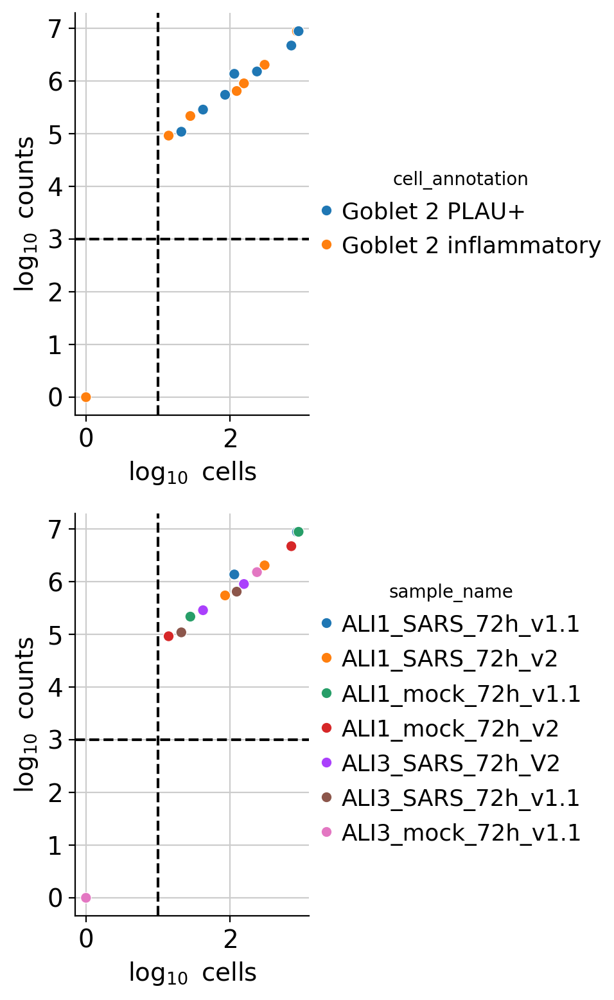

In [ ]:
dc.pl.filter_samples(
    adata=woodall_pb,
    groupby=["cell_annotation", "sample_name"],
    min_cells=10,
    min_counts=1000,
    figsize=(5, 8),
)

In [ ]:
dc.pp.filter_samples(woodall_pb, min_cells=10, min_counts=1000)

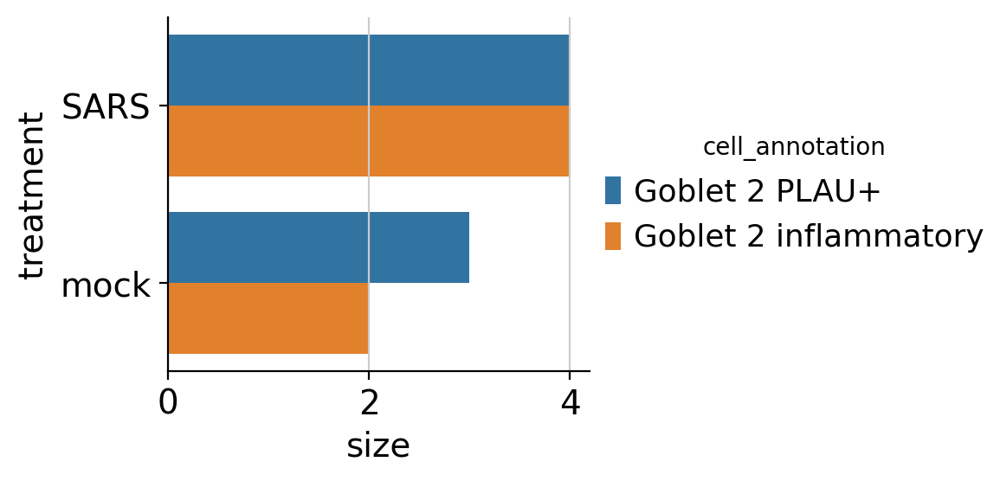

In [ ]:
dc.pl.obsbar(adata=woodall_pb, y="treatment", hue="cell_annotation", figsize=(6, 3))

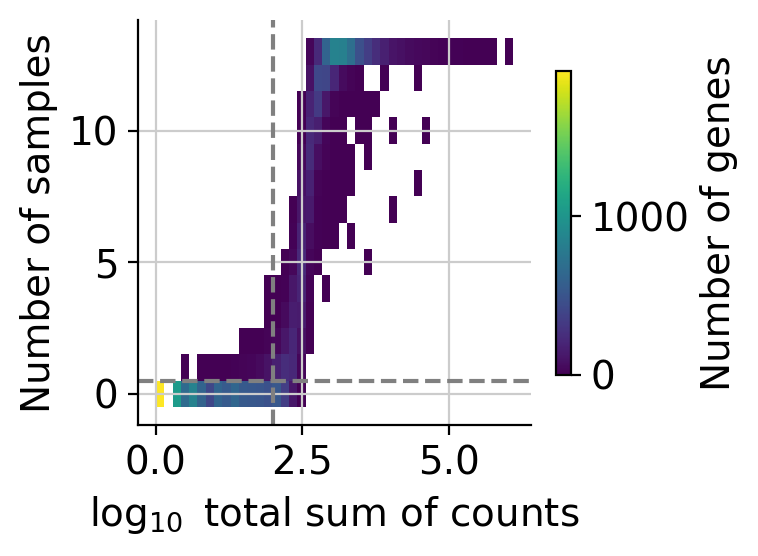

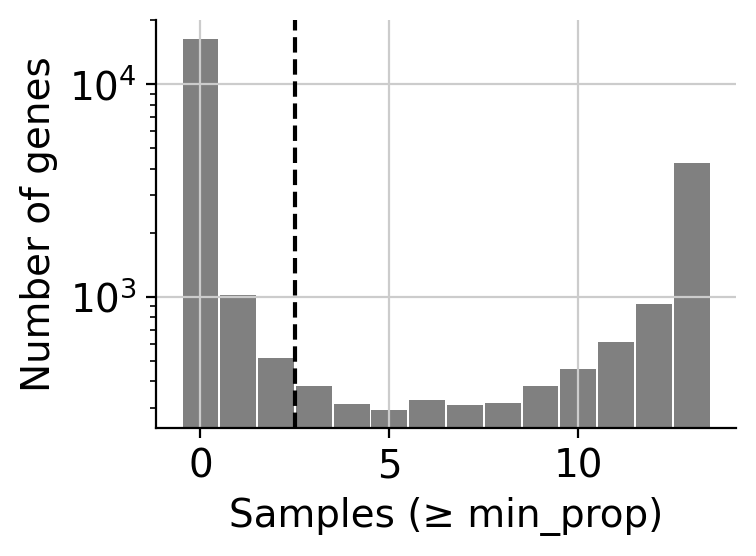

In [ ]:
dc.pl.filter_by_expr(
    adata=woodall_pb,
    group="sample_name",
    min_count=10,min_total_count=100,
    large_n=5,
    min_prop=0.7,
)
dc.pl.filter_by_prop(
    adata=woodall_pb,
    min_prop=0.1,
    min_smpls=3,
)

In [ ]:
dc.pp.filter_by_expr(
    adata=woodall_pb,
    group="sample_name",
    min_count=10,min_total_count=100,
    large_n=5,
    min_prop=0.7,
)
dc.pp.filter_by_prop(
    adata=woodall_pb,
    min_prop=0.1,
    min_smpls=3,
)

In [ ]:
# Import DESeq2
from pydeseq2.dds import DeseqDataSet, DefaultInference
from pydeseq2.ds import DeseqStats

In [ ]:
woodall_pb.obs

,cell_annotation,sample_name,sample,treatment,time,pool,kit_version,spike-in_primer,age_group,bbknn_batch,age_treatment,psbulk_cells,psbulk_counts
Goblet 2 PLAU+_ALI1_SARS_72h_v1.1,Goblet 2 PLAU+,ALI1_SARS_72h_v1.1,CV001_KM9465190,SARS,72h,ALI1,v1.1,NONE,Paediatric,ALI1-v1.1,Paediatric-SARS,113.0,1368987.0
Goblet 2 inflammatory_ALI1_SARS_72h_v1.1,Goblet 2 inflammatory,ALI1_SARS_72h_v1.1,CV001_KM9465190,SARS,72h,ALI1,v1.1,NONE,Paediatric,ALI1-v1.1,Paediatric-SARS,842.0,8789995.0
Goblet 2 PLAU+_ALI1_SARS_72h_v2,Goblet 2 PLAU+,ALI1_SARS_72h_v2,CV001_KM9505824,SARS,72h,ALI1,v2,NONE,Paediatric,ALI1-v2,Paediatric-SARS,84.0,547468.0
Goblet 2 inflammatory_ALI1_SARS_72h_v2,Goblet 2 inflammatory,ALI1_SARS_72h_v2,CV001_KM9505824,SARS,72h,ALI1,v2,NONE,Paediatric,ALI1-v2,Paediatric-SARS,299.0,2034236.0
Goblet 2 PLAU+_ALI1_mock_72h_v1.1,Goblet 2 PLAU+,ALI1_mock_72h_v1.1,CV001_KM9465189,mock,72h,ALI1,v1.1,NONE,Paediatric,ALI1-v1.1,Paediatric-mock,886.0,8828289.0
Goblet 2 inflammatory_ALI1_mock_72h_v1.1,Goblet 2 inflammatory,ALI1_mock_72h_v1.1,CV001_KM9465189,mock,72h,ALI1,v1.1,NONE,Paediatric,ALI1-v1.1,Paediatric-mock,27.0,216814.0
Goblet 2 PLAU+_ALI1_mock_72h_v2,Goblet 2 PLAU+,ALI1_mock_72h_v2,CV001_KM9505823,mock,72h,ALI1,v2,NONE,Paediatric,ALI1-v2,Paediatric-mock,703.0,4708491.0
Goblet 2 inflammatory_ALI1_mock_72h_v2,Goblet 2 inflammatory,ALI1_mock_72h_v2,CV001_KM9505823,mock,72h,ALI1,v2,NONE,Paediatric,ALI1-v2,Paediatric-mock,13.0,91971.0
Goblet 2 PLAU+_ALI3_SARS_72h_V2,Goblet 2 PLAU+,ALI3_SARS_72h_V2,CV001_KM9505916,SARS,72h,ALI3,v2,spike-in_HIGH,Paediatric,ALI3-v2,Paediatric-SARS,41.0,286770.0
Goblet 2 inflammatory_ALI3_SARS_72h_V2,Goblet 2 inflammatory,ALI3_SARS_72h_V2,CV001_KM9505916,SARS,72h,ALI3,v2,spike-in_HIGH,Paediatric,ALI3-v2,Paediatric-SARS,154.0,901999.0


In [ ]:
# Build DESeq2 object
inference = DefaultInference(n_cpus=1)
dds = DeseqDataSet(
    adata=woodall_pb,
    design_factors=["cell_annotation","bbknn_batch"],
    refit_cooks=True,
    inference=inference,
)

# Compute LFCs
dds.deseq2()

# Extract contrast between conditions
stat_res = DeseqStats(dds, contrast=["cell_annotation", "Goblet 2 inflammatory","Goblet 2 PLAU+"], inference=inference)

# Compute Wald test
stat_res.summary()

/tmp/ipykernel_2033028/1562575519.py:3: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds = DeseqDataSet(
Fitting size factors...
... done in 0.00 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 6.10 seconds.

Fitting dispersion trend curve...
/home/mark/miniconda3/envs/decoupler/lib/python3.12/site-packages/pydeseq2/dds.py:822: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)
... done in 0.12 seconds.

Fitting MAP dispersions...
... done in 6.48 seconds.

Fitting LFCs...
... done in 3.86 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...


Log2 fold change & Wald test p-value: cell_annotation Goblet 2 inflammatory vs Goblet 2 PLAU+
                    baseMean  log2FoldChange     lfcSE      stat  \
NOC2L              28.835046       -0.255649  0.172078 -1.485661   
PLEKHN1            13.237249        0.968471  0.346722  2.793219   
HES4              607.704900        0.331758  0.149085  2.225297   
ISG15            1560.124315        3.603041  0.695094  5.183527   
AGRN              215.788020        0.106325  0.137276  0.774540   
...                      ...             ...       ...       ...   
AC007325.4         12.504287        0.090743  0.217771  0.416692   
AC007325.2         17.120961        0.615393  0.430516  1.429430   
AC004556.1         48.969635        0.018671  0.138479  0.134831   
AC240274.1         12.077740       -0.279443  0.234584 -1.191231   
VIRAL_SARS-CoV2  1064.330685        4.825793  2.112183  2.284741   

                       pvalue      padj  
NOC2L            1.373687e-01  0.505901  
PLEKH

... done in 0.90 seconds.



In [ ]:
# Extract results
results_df = stat_res.results_df
results_df

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
NOC2L,28.835046,-0.255649,0.172078,-1.485661,1.373687e-01,0.505901
PLEKHN1,13.237249,0.968471,0.346722,2.793219,5.218642e-03,0.065225
HES4,607.704900,0.331758,0.149085,2.225297,2.606129e-02,0.200917
ISG15,1560.124315,3.603041,0.695094,5.183527,2.177289e-07,0.000012
AGRN,215.788020,0.106325,0.137276,0.774540,4.386117e-01,0.800389
...,...,...,...,...,...,...
AC007325.4,12.504287,0.090743,0.217771,0.416692,6.769034e-01,0.912869
AC007325.2,17.120961,0.615393,0.430516,1.429430,1.528807e-01,0.528261
AC004556.1,48.969635,0.018671,0.138479,0.134831,8.927457e-01,0.974735
AC240274.1,12.077740,-0.279443,0.234584,-1.191231,2.335630e-01,0.634025


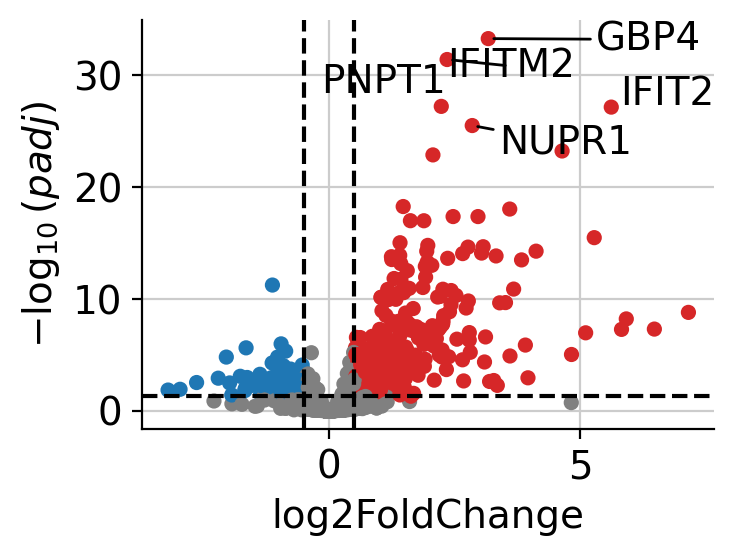

In [ ]:
dc.pl.volcano(results_df, x="log2FoldChange", y="padj")

In [ ]:
log2fc_cutoff = 0.5
padj_cutoff = 0.05
top_n = 20
custom_genes = ["HSPG2","TMPRSS2","ACE2","HSPE1","VIRAL_SARS-CoV2","ISG15","IFITM1","IFIT1","IFIT2"]

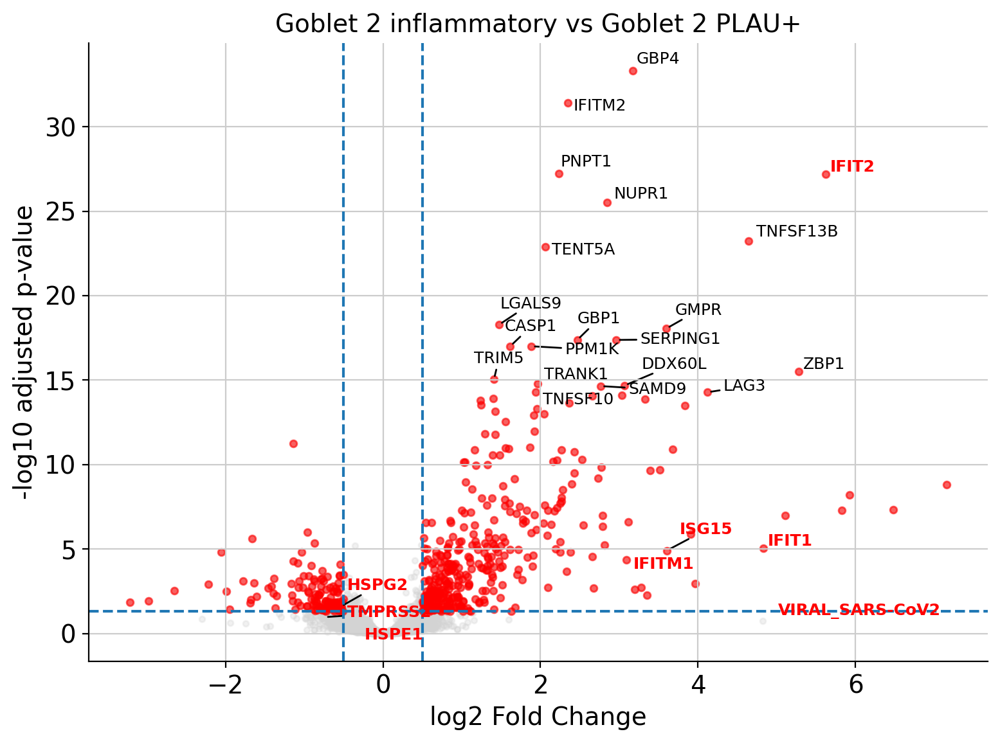

In [ ]:
df = results_df.copy()

# Clean
df = df.dropna(subset=["log2FoldChange", "padj"])
df["neglog10_padj"] = -np.log10(df["padj"])

# Significant points
sig_mask = (
    (df["padj"] < padj_cutoff) &
    (np.abs(df["log2FoldChange"]) > log2fc_cutoff)
)

# Top genes by padj
top_genes = (
    df.sort_values("pvalue")
      .head(top_n)
      .index
)

# Genes to label
label_genes = set(top_genes).union(custom_genes)

# ---- Plot ----
plt.figure(figsize=(8, 6))

# Background
plt.scatter(
    df["log2FoldChange"],
    df["neglog10_padj"],
    c="lightgrey",
    s=10,
    alpha=0.3
)

# Significant points in red
plt.scatter(
    df.loc[sig_mask, "log2FoldChange"],
    df.loc[sig_mask, "neglog10_padj"],
    c="red",
    s=15,
    alpha=0.6
)

# Threshold lines
plt.axhline(-np.log10(padj_cutoff), linestyle="--")
plt.axvline(log2fc_cutoff, linestyle="--")
plt.axvline(-log2fc_cutoff, linestyle="--")

# ---- Labels with color logic ----
texts = []

for gene in label_genes:
    if gene not in df.index:
        continue

    color = "red" if gene in custom_genes else "black"

    texts.append(
        plt.text(
            df.loc[gene, "log2FoldChange"],
            df.loc[gene, "neglog10_padj"],
            gene,
            fontsize=9,
            color=color,
            weight="bold" if gene in custom_genes else "normal"
        )
    )

adjust_text(texts, arrowprops=dict(arrowstyle="-", lw=1))

# Labels
plt.xlabel("log2 Fold Change")
plt.ylabel("-log10 adjusted p-value")
plt.title("Goblet 2 inflammatory vs Goblet 2 PLAU+")

plt.tight_layout()
plt.show()

In [ ]:
df_X = results_df[results_df.index.str.contains("ISG|HSPG2|TMPRSS2|ACE|HSPE|SARS|CDK")].sort_values("padj")
df_X

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
ISG20,191.823993,2.791522,0.457561,6.100874,1.054899e-09,1.001216e-07
ISG15,1560.124315,3.603041,0.695094,5.183527,2.177289e-07,1.239894e-05
HSPG2,194.509409,-0.538397,0.169295,-3.180233,1.471564e-03,2.571575e-02
CDK17,20.601583,0.649390,0.239224,2.714572,6.636152e-03,7.851248e-02
CDK18,12.513880,0.731050,0.278491,2.625044,8.663773e-03,9.549155e-02
TMPRSS2,74.543099,-0.744281,0.289258,-2.573069,1.008012e-02,1.070950e-01
CDK2AP2,67.950827,-0.306146,0.127312,-2.404691,1.618613e-02,1.486687e-01
CDK6,89.420204,-0.285302,0.119673,-2.384006,1.712534e-02,1.551269e-01
CDK2AP1,92.269667,-0.328277,0.138721,-2.366446,1.795980e-02,1.591417e-01
VIRAL_SARS-CoV2,1064.330685,4.825793,2.112183,2.284741,2.232800e-02,1.840982e-01


In [ ]:
collectri = dc.op.collectri(organism="human")
collectri

,source,target,weight,resources,references,sign_decision
0,MYC,TERT,1.0,DoRothEA-A;ExTRI;HTRI;NTNU.Curated;Pavlidis202...,10022128;10491298;10606235;10637317;10723141;1...,PMID
1,SPI1,BGLAP,1.0,ExTRI,10022617,default activation
2,SMAD3,JUN,1.0,ExTRI;NTNU.Curated;TFactS;TRRUST,10022869;12374795,PMID
3,SMAD4,JUN,1.0,ExTRI;NTNU.Curated;TFactS;TRRUST,10022869;12374795,PMID
4,STAT5A,IL2,1.0,ExTRI,10022878;11435608;17182565;17911616;22854263;2...,default activation
...,...,...,...,...,...,...
42985,NFKB,hsa-miR-143-3p,1.0,ExTRI,19472311,default activation
42986,AP1,hsa-miR-206,1.0,ExTRI;GEREDB;NTNU.Curated,19721712,PMID
42987,NFKB,hsa-miR-21,1.0,ExTRI,20813833;22387281,default activation
42988,NFKB,hsa-miR-224-5p,1.0,ExTRI,23474441;23988648,default activation


In [ ]:
data = results_df.dropna()[["stat"]].T.rename(index={"stat": "Goblet 2 inflammatory vs Goblet 2 PLAU+"})
data

NOC2L   PLEKHN1      HES4  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -1.485661  2.793219  2.225297   

                                            ISG15     AGRN  AL390719.2  \
Goblet 2 inflammatory vs Goblet 2 PLAU+  5.183527  0.77454    1.842724   

                                             SDF4   B3GALT6    UBE2J2  \
Goblet 2 inflammatory vs Goblet 2 PLAU+  0.870458 -0.268787 -1.544634   

                                            ACAP3     PUSL1  INTS11      CPTP  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -2.236233 -1.422454  0.1432 -0.002302   

                                             DVL1  AURKAIP1     CCNL2  MRPL20  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -0.136529  0.034058 -0.265895   -1.87   

                                          ANKRD65      VWA1    ATAD3B  \
Goblet 2 inflammatory vs Goblet 2 PLAU+  0.087789  0.025186 -0.033489   

                                           ATAD3A     SSU72      MIB2  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -0.576911 -1.116893 -0.808257   

                                           CDK11B  SLC35E2B    CDK11A  \
Goblet 2 inflammatory vs Goblet 2 PLAU+  1.301388 -0.477219  0.672776   

                                         SLC35E2A      NADK      GNB1  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -1.241283  3.283746 -0.986615   

                                            PRKCZ    FAAP20       SKI  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -0.689192 -0.431062 -1.278431   

                                             RER1    PEX10     PLCH2  \
Goblet 2 inflammatory vs Goblet 2 PLAU+  0.287154  0.40621  1.713361   

                                         AL139246.5  TNFRSF14   FAM213B  \
Goblet 2 inflammatory vs Goblet 2 PLAU+   -1.598658  0.390013  1.607478   

                                            MMEL1  ARHGEF16    TPRG1L  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -1.383225  -0.55655 -1.147281   

                                           WRAP73    LRRC47    CEP104  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -0.767482  0.830811  0.944711   

                                         C1orf174  RPL22   RNF207      ICMT  \
Goblet 2 inflammatory vs Goblet 2 PLAU+  0.980614 -1.519 -1.03254 -0.223431   

                                           GPR153     ACOT7      HES2  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -0.087012  1.447194  2.214457   

                                             NOL9  ZBTB48    KLHL21   DNAJC11  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -0.388519  1.3329 -0.540369  0.062311   

                                           CAMTA1     VAMP3     PER3  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -1.523872  0.388586  1.20457   

                                            PARK7    ERRFI1      RERE  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -1.529949 -1.886901 -0.000173   

                                            ENO1    GPR157  MIR34AHG  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -1.54332 -0.278549 -1.205816   

                                             H6PD     SPSB1  SLC25A33  \
Goblet 2 inflammatory vs Goblet 2 PLAU+  0.431321  3.609352 -0.954041   

                                           CLSTN1  CTNNBIP1      LZIC  \
Goblet 2 inflammatory vs Goblet 2 PLAU+  1.502717 -1.136928  0.258814   

                                            UBE4B     KIF1B       PGD  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -1.401371 -1.088867 -1.707986   

                                             DFFA     PEX14     CASZ1  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -1.351835  0.214797  0.672841   

                                           TARDBP       SRM   EXOSC10  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -0.198312 -0.718412  2.012963   

                                             MTOR    UBIAD1    FBXO2  \
Goblet 2 inflammatory vs Goblet 2 PLAU+ -0.820609  0.317928  0.00312   

                                           FBXO44     FBXO6    MAD2L2  \
Goblet 2 inflammatory vs Goblet 2 PLAU+  0.351438  4.803971  1.755167   

                 

In [ ]:
# Run
tf_acts, tf_padj = dc.mt.ulm(data=data, net=collectri)

# Filter by sign padj
msk = (tf_padj.T < 0.05).iloc[:, 0]
tf_acts = tf_acts.loc[:, msk]

tf_acts

,AP1,BRCA1,CIITA,ETS1,FLI1,FOSL1,HIVEP2,IRF1,IRF2,IRF3,IRF6,IRF7,IRF9,JUN,JUND,NFATC2,NFKB,NFKB1,NR1D1,NR2E3,NR3C1,PITX1,PITX2,REL,RELA,SIN3A,SP1,SPI1,SSRP1,STAT1,STAT2,STAT5A,TCF3
Goblet 2 inflammatory vs Goblet 2 PLAU+,3.513056,3.928724,3.53274,3.200043,3.079482,3.737521,4.664315,12.017113,10.58036,5.253991,3.566399,3.137996,10.153701,3.250172,3.370115,3.167647,3.612194,5.842483,-3.280451,3.677883,3.262727,-3.012361,-3.02746,3.473867,5.804686,4.02134,3.784378,3.816184,2.997989,12.291651,8.752321,3.066844,3.162912


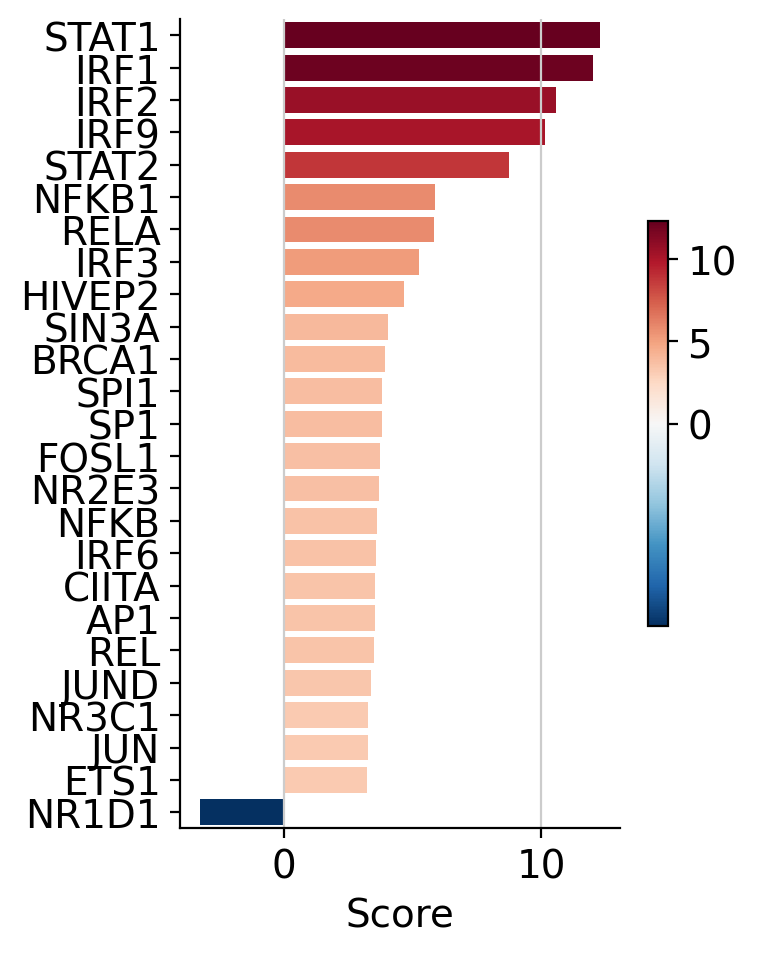

In [ ]:
dc.pl.barplot(data=tf_acts, name="Goblet 2 inflammatory vs Goblet 2 PLAU+", figsize=(4, 5))

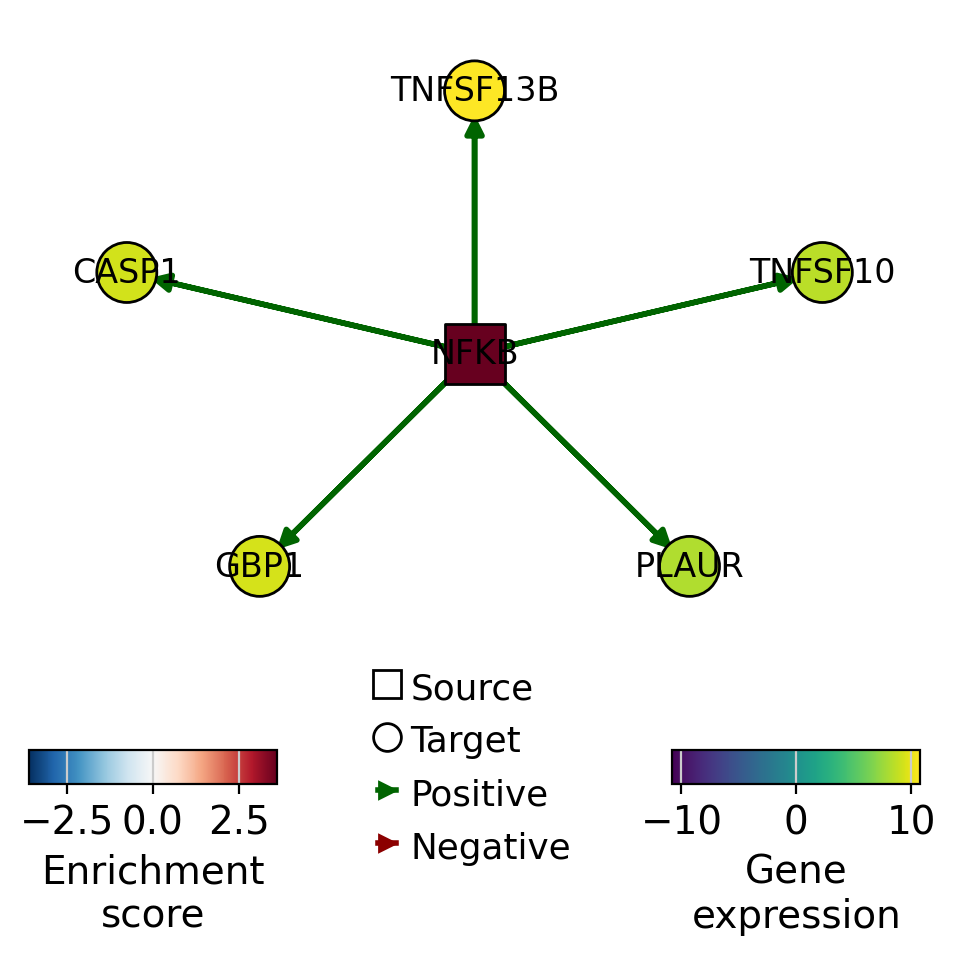

In [ ]:
dc.pl.network(
    net=collectri,
    data=data,
    score=tf_acts,
    sources=["STAT3", "NFKB"],
    targets=5,
    figsize=(5, 5),
    vcenter=True,
    by_abs=True,
    size_node=15,
)


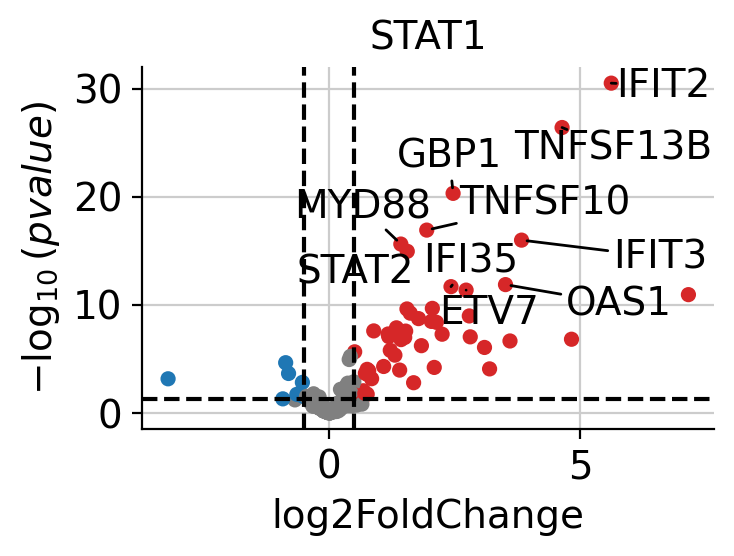

In [ ]:
dc.pl.volcano(
    data=results_df,
    x="log2FoldChange",
    y="pvalue",
    net=collectri,
    name="STAT1",
    top=10,
)

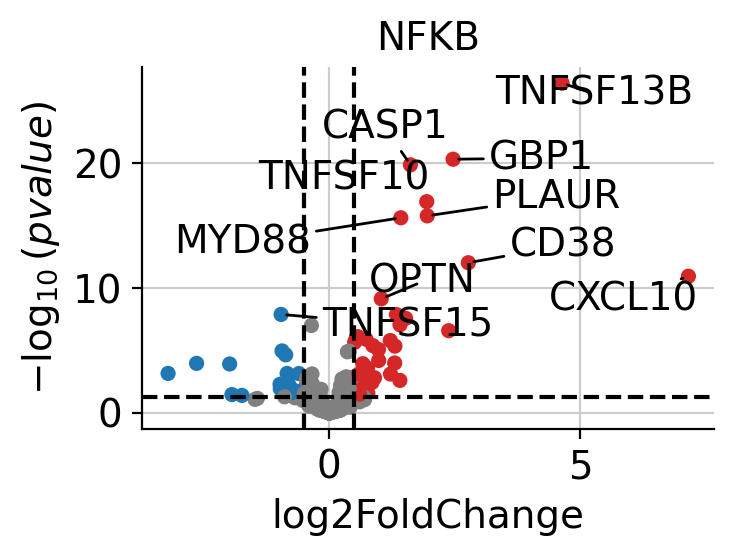

In [ ]:
dc.pl.volcano(
    data=results_df,
    x="log2FoldChange",
    y="pvalue",
    net=collectri,
    name="NFKB",
    top=10,
)

#### compare elderly basaloid-like 2 cells (fig 5)

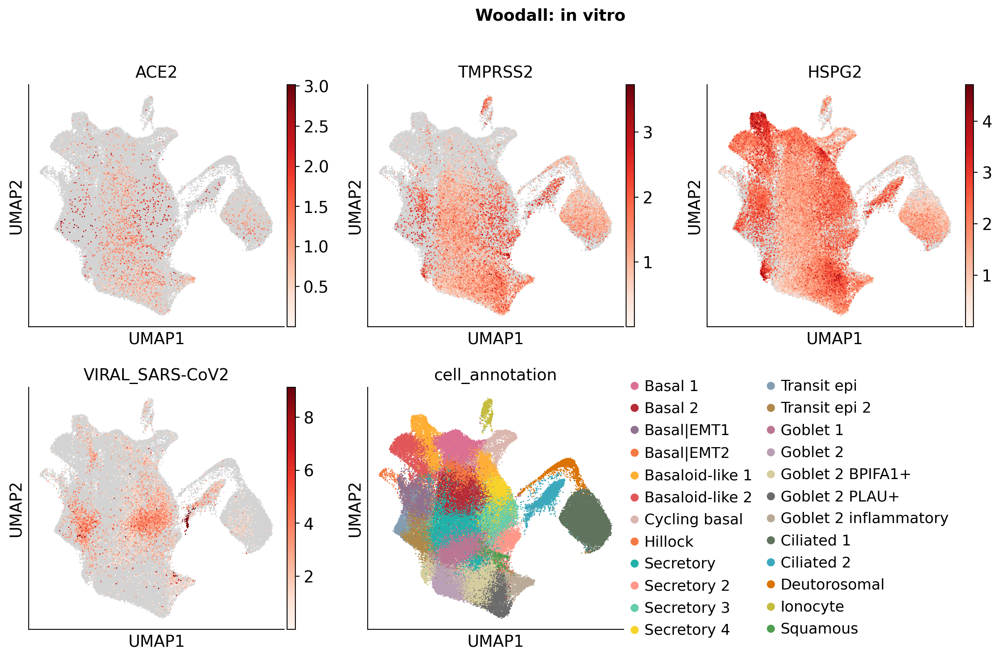

In [13]:
with rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(
        adata = Woodall_inVitro_adata,
        color = [
            "ACE2", "TMPRSS2","HSPG2","VIRAL_SARS-CoV2",
            "cell_annotation"],
        ncols=3,size=5,
        use_raw=False,
        color_map=reds,vmin=0.00001,
        show=False
        # layer="soupX",
    )
    fig = plt.gcf() # get current figure
    fig.suptitle(f"Woodall: in vitro", fontsize=14, fontweight="bold",x=0.5, y=1)
    fig.savefig("figures/lung/Woodall_invitro_umap.pdf",dpi=300,bbox_inches='tight')

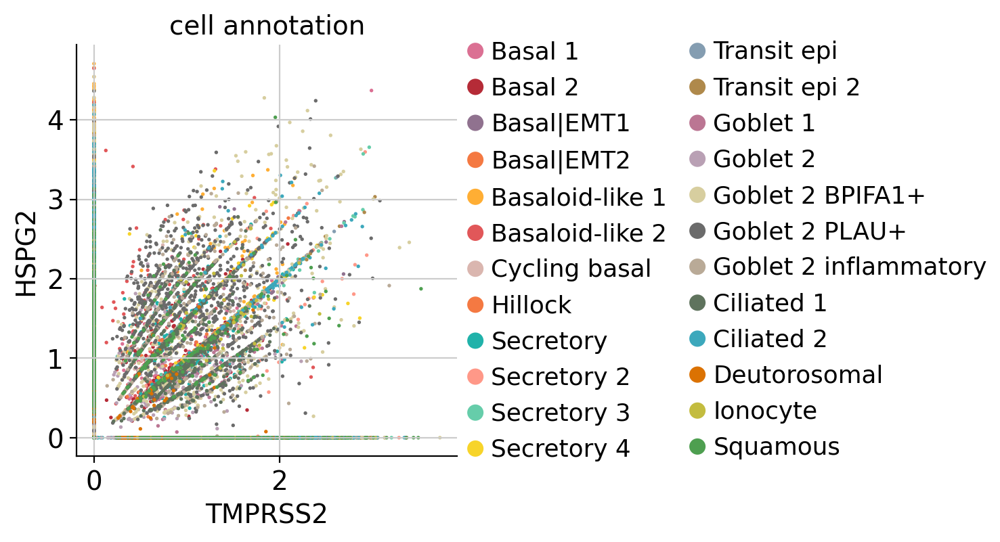

In [14]:
with rc_context({"figure.figsize": (4, 4)}):
    sc.pl.scatter(
        adata = Woodall_inVitro_adata,
        x = "TMPRSS2",y="HSPG2",color = "cell_annotation",
        size=15
    )

In [15]:
categories = Woodall_inVitro_adata.obs['cell_annotation'].cat.categories
colors = Woodall_inVitro_adata.uns['cell_annotation_colors']
color_palette = dict(zip(categories, colors))

In [41]:
selected_cells = ["Cycling basal","Basal 1", "Secretory 3", "Transit epi","Deutorosomal","Ciliated 1"]

# Extract original color palette mapping from AnnData
categories = Woodall_inVitro_adata.obs['cell_annotation'].cat.categories
colors = Woodall_inVitro_adata.uns['cell_annotation_colors']
color_palette = dict(zip(categories, colors))

# --- Block 1: ACE2 vs HSPG2 ---
df_ace2 = sc.get.obs_df(
    Woodall_inVitro_adata, keys=['ACE2', 'HSPG2', 'cell_annotation']
)
df_ace2 = df_ace2[df_ace2['cell_annotation'].isin(selected_cells)]
df_ace2['cell_annotation'] = df_ace2[
    'cell_annotation'
].cat.remove_unused_categories()

df_ace2_nonzero = df_ace2[(df_ace2['ACE2'] > 0) & (df_ace2['HSPG2'] > 0)]

fig, ax = plt.subplots(figsize=(7, 6))

sns.scatterplot(
    data=df_ace2,
    x='ACE2',
    y='HSPG2',
    hue='cell_annotation',
    hue_order=selected_cells,
    palette=color_palette,
    ax=ax,
    alpha=0.6,
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
for cell_type, group in df_ace2_nonzero.groupby(
    'cell_annotation', observed=True
):
  if len(group) > 1:
    sns.regplot(
        data=group,
        x='ACE2',
        y='HSPG2',
        scatter=False,
        ax=ax,
        color=color_palette.get(cell_type),
        truncate=False,
    )

ax.set_title(
    'HSPG2 vs ACE2 expression', fontsize=14, fontweight='bold', pad=12
)
plt.savefig(
    'figures/lung/revision_Woodall_inVitro_ACE2vsHSPG2_scatter.pdf',
    bbox_inches='tight',
)
plt.close()


# --- Block 2: TMPRSS2 vs HSPG2 ---
df_tmprss2 = sc.get.obs_df(
    Woodall_inVitro_adata, keys=['TMPRSS2', 'HSPG2', 'cell_annotation']
)
df_tmprss2 = df_tmprss2[df_tmprss2['cell_annotation'].isin(selected_cells)]
df_tmprss2['cell_annotation'] = df_tmprss2[
    'cell_annotation'
].cat.remove_unused_categories()

df_tmprss2_nonzero = df_tmprss2[
    (df_tmprss2['TMPRSS2'] > 0) & (df_tmprss2['HSPG2'] > 0)
]

fig, ax = plt.subplots(figsize=(7, 6))

sns.scatterplot(
    data=df_tmprss2,
    x='TMPRSS2',
    y='HSPG2',
    hue='cell_annotation',
    palette=color_palette,
    hue_order=selected_cells,
    ax=ax,
    alpha=0.6,
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
for cell_type, group in df_tmprss2_nonzero.groupby(
    'cell_annotation', observed=True
):
  if len(group) > 1:
    sns.regplot(
        data=group,
        x='TMPRSS2',
        y='HSPG2',
        scatter=False,
        ax=ax,
        color=color_palette.get(cell_type),
        truncate=False,
    )

ax.set_title(
    'HSPG2 vs TMPRSS2 expression', fontsize=14, fontweight='bold', pad=12
)
plt.savefig(
    'figures/lung/revision_Woodall_inVitro_TMPRSS2vsHSPG2_scatter.pdf',
    bbox_inches='tight',
)
plt.close()

In [18]:
selected_cells = ["Basal 1", "Secretory 3", "Transit epi","Deutorosomal"]

# --- Block 1: ACE2 vs HSPG2 ---
# Create non-zero subset for regression
df_ace2 = sc.get.obs_df(
    Woodall_inVitro_adata, keys=['ACE2', 'HSPG2', 'cell_annotation']
)
df_ace2 = df_ace2[df_ace2['cell_annotation'].isin(selected_cells)]
df_ace2['cell_annotation'] = df_ace2[
    'cell_annotation'
].cat.remove_unused_categories()
df_ace2_nonzero = df_ace2[(df_ace2['ACE2'] > 0) & (df_ace2['HSPG2'] > 0)]

fig, ax = plt.subplots(figsize=(7, 6))

# 1. Plot all data points (including zeros)
sns.scatterplot(
    data=df_ace2,
    x='ACE2',
    y='HSPG2',
    hue='cell_annotation',
    palette=color_palette,
    ax=ax,
    alpha=0.6,
)

# 2. Overlay regression lines calculated ONLY on non-zero points per cell category
for cell_type, group in df_ace2_nonzero.groupby('cell_annotation'):
  if len(group) > 1:  # Requires at least 2 points to fit a line
    # Retrieve matching color from palette if color_palette is a dict, or let seaborn assign
    color = (
        color_palette[cell_type]
        if isinstance(color_palette, dict)
        else None
    )
    sns.regplot(
        data=group,
        x='ACE2',
        y='HSPG2',
        scatter=False,  # Don't duplicate scatter points
        ax=ax,
        color=color,
        truncate=False,
    )

ax.set_title(
    'HSPG2 vs ACE2 expression', fontsize=14, fontweight='bold', pad=12
)
plt.savefig(
    'figures/lung/revision_Woodall_inVitro_ACE2vsHSPG2_scatter.pdf',
    bbox_inches='tight',
)
plt.close()

# --- Block 2: TMPRSS2 vs HSPG2 ---
# Extract metadata & gene expression into a DataFrame
df_tmprss2 = sc.get.obs_df(
    Woodall_inVitro_adata, keys=['TMPRSS2', 'HSPG2', 'cell_annotation']
)
df_tmprss2 = df_tmprss2[df_tmprss2['cell_annotation'].isin(selected_cells)]
df_tmprss2['cell_annotation'] = df_tmprss2[
    'cell_annotation'
].cat.remove_unused_categories()

# Filter out zero-expression values specifically for fitting the regression lines
df_tmprss2_nonzero = df_tmprss2[
    (df_tmprss2['TMPRSS2'] > 0) & (df_tmprss2['HSPG2'] > 0)
]

fig, ax = plt.subplots(figsize=(7, 6))

# 1. Plot ALL data points (including zeros)
sns.scatterplot(
    data=df_tmprss2,
    x='TMPRSS2',
    y='HSPG2',
    hue='cell_annotation',
    palette=color_palette,
    ax=ax,
    alpha=0.6,
)

# 2. Overlay regression lines calculated ONLY on non-zero points per cell category
for cell_type, group in df_tmprss2_nonzero.groupby('cell_annotation'):
  if len(group) > 1:  # Requires at least 2 points to fit a line
    color = (
        color_palette[cell_type]
        if isinstance(color_palette, dict)
        else None
    )
    sns.regplot(
        data=group,
        x='TMPRSS2',
        y='HSPG2',
        scatter=False,  # Avoid duplicating scatter points
        ax=ax,
        color=color,
        truncate=False,
    )

ax.set_title(
    'HSPG2 vs TMPRSS2 expression', fontsize=14, fontweight='bold', pad=12
)
plt.savefig(
    'figures/lung/revision_Woodall_inVitro_TMPRSS2vsHSPG2_scatter.pdf',
    bbox_inches='tight',
)
plt.close()

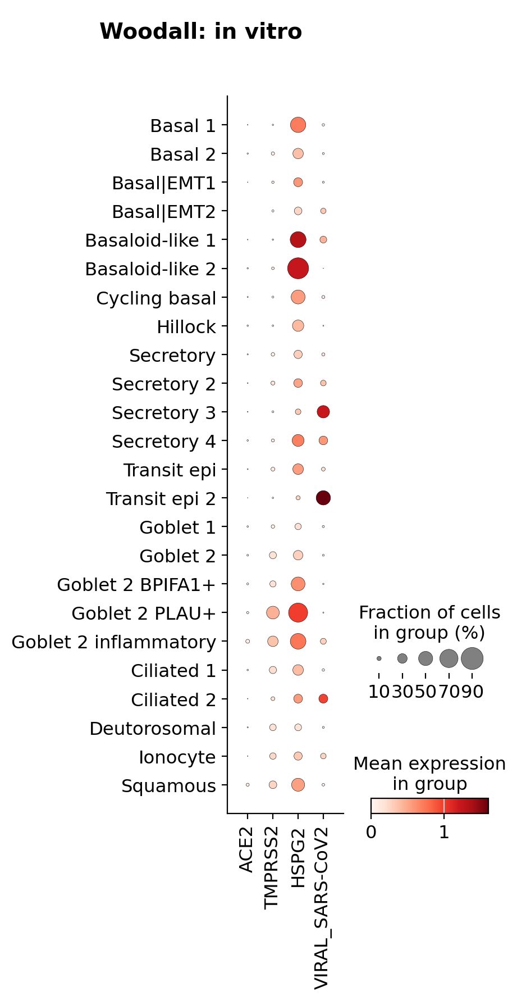

In [ ]:
with rc_context({"figure.figsize": (6,2)}):
    axes = sc.pl.dotplot(
        adata = Woodall_inVitro_adata[Woodall_inVitro_adata.obs["time"] == "72h"],
        var_names=["ACE2", "TMPRSS2","HSPG2","VIRAL_SARS-CoV2"],
        groupby="cell_annotation",use_raw=False,
        show=False)
    fig = plt.gcf() # get current figure
    fig.suptitle(f"Woodall: in vitro", fontsize=14, fontweight="bold",x=0.1, y=0.9)
    fig.savefig("figures/lung/Woodall_invitro_dotplot.pdf",dpi=300,bbox_inches='tight')

In [ ]:
Woodall_inVitro_adata.obs

,sample,treatment,time,pool,sample_name,kit_version,spike-in_primer,scrublet_score,doublet_bh_pval,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,souporcell_cluster,donor_id,age_group,gender,S_score,G2M_score,phase,bbknn_batch,cell_annotation,age_treatment,score_IFN_alpha,score_IFN_gamma,score_BASALOID
CV001_KM10202575_AAACCTGAGCAGGTCA,CV001_KM10202575,mock,4h,ALI2,ALI2_mock_4h_v1.1,v1.1,spike-in_LOW,0.074489,0.899867,2007,5978.355469,321.375763,5.375655,508.158630,8.499973,CV001_KM10202575_cluster_3,UCL_10,Adult,Female,0.012715,-0.122299,S,ALI2-v1.1,Goblet 2,Adult-mock,0.164289,0.242595,0.184872
CV001_KM10202575_AAACCTGAGCCAGTTT,CV001_KM10202575,mock,4h,ALI2,ALI2_mock_4h_v1.1,v1.1,spike-in_LOW,0.182796,0.899867,1936,4667.351074,422.780762,9.058259,661.751038,14.178300,CV001_KM10202575_cluster_3,UCL_10,Adult,Female,0.016216,-0.056671,S,ALI2-v1.1,Goblet 2 BPIFA1+,Adult-mock,0.437474,0.173749,0.107360
CV001_KM10202575_AAACCTGAGCGTAGTG,CV001_KM10202575,mock,4h,ALI2,ALI2_mock_4h_v1.1,v1.1,spike-in_LOW,0.216327,0.861171,1072,1869.545410,250.455383,13.396592,145.099289,7.761207,CV001_KM10202575_cluster_3,UCL_10,Adult,Female,-0.039390,-0.012464,G1,ALI2-v1.1,Goblet 2 BPIFA1+,Adult-mock,0.132267,0.212443,0.219769
CV001_KM10202575_AAACCTGAGCTCCTTC,CV001_KM10202575,mock,4h,ALI2,ALI2_mock_4h_v1.1,v1.1,spike-in_LOW,0.066090,0.915221,1637,3787.764160,370.476379,9.780872,560.797424,14.805500,CV001_KM10202575_cluster_0,UCL_6,Elderly,Female,0.077160,-0.175455,S,ALI2-v1.1,Basal 2,Elderly-mock,-0.093077,0.058059,0.175730
CV001_KM10202575_AAACCTGAGCTGGAAC,CV001_KM10202575,mock,4h,ALI2,ALI2_mock_4h_v1.1,v1.1,spike-in_LOW,0.187805,0.899867,1742,3958.839111,313.766357,7.925716,601.522949,15.194427,CV001_KM10202575_cluster_1,UCL_5,Elderly,Female,0.012258,-0.066333,S,ALI2-v1.1,Basal 1,Elderly-mock,0.123714,0.150537,0.051336
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CV001_KM9505916_TTTGTCAGTTCCATGA,CV001_KM9505916,SARS,72h,ALI3,ALI3_SARS_72h_V2,v2,spike-in_HIGH,0.152639,0.937426,2169,4808.247559,338.860718,7.047489,476.731720,9.914875,CV001_KM9505916_cluster_3,UCL_7,Elderly,Male,-0.028217,-0.130824,G1,ALI3-v2,Goblet 2 BPIFA1+,Elderly-SARS,0.176980,0.129034,0.282540
CV001_KM9505916_TTTGTCATCACGATGT,CV001_KM9505916,SARS,72h,ALI3,ALI3_SARS_72h_V2,v2,spike-in_HIGH,0.220339,0.922660,1480,2611.079102,262.215332,10.042413,227.407578,8.709333,CV001_KM9505916_cluster_2,UCL_11,Adult,Female,-0.042824,-0.144969,G1,ALI3-v2,Secretory,Adult-SARS,-0.045456,0.129736,0.034195
CV001_KM9505916_TTTGTCATCCCATTAT,CV001_KM9505916,SARS,72h,ALI3,ALI3_SARS_72h_V2,v2,spike-in_HIGH,0.129771,0.937426,1571,3220.570801,172.535034,5.357281,616.526855,19.143402,CV001_KM9505916_cluster_0,UCL_12,Adult,Female,-0.027907,-0.138610,G1,ALI3-v2,Basal 2,Adult-SARS,-0.051619,0.112761,0.082636
CV001_KM9505916_TTTGTCATCCGGGTGT,CV001_KM9505916,SARS,72h,ALI3,ALI3_SARS_72h_V2,v2,spike-in_HIGH,0.065327,0.985310,2861,9856.480469,100.517784,1.019814,948.763733,9.625786,CV001_KM9505916_cluster_1,UCL_9,Paediatric,Male,-0.057059,-0.149032,G1,ALI3-v2,Goblet 2 BPIFA1+,Paediatric-SARS,0.194762,0.217395,0.012546


In [ ]:
genes = ["ACE2", "TMPRSS2", "HSPG2","VIRAL_SARS-CoV2"]
df = (
    Woodall_inVitro_adata[:, genes]
    .to_df()
    .join(Woodall_inVitro_adata.obs[["cell_annotation","time","age_group"]])
)

dot_df = (
    df
    .melt(id_vars=["cell_annotation","time","age_group"], var_name="gene", value_name="expr")
    .groupby(["cell_annotation", "time","age_group","gene"])
    .agg(
        mean_expr=("expr", "mean"),
        pct_expr=("expr", lambda x: (x > 0).mean() * 100)
    )
    .reset_index()
)
dot_df

,cell_annotation,time,age_group,gene,mean_expr,pct_expr
0,Basal 1,4h,Paediatric,ACE2,0.000000,0.000000
1,Basal 1,4h,Paediatric,HSPG2,0.754225,33.333332
2,Basal 1,4h,Paediatric,TMPRSS2,0.000000,0.000000
3,Basal 1,4h,Paediatric,VIRAL_SARS-CoV2,0.000000,0.000000
4,Basal 1,4h,Adult,ACE2,0.011957,1.128668
...,...,...,...,...,...,...
859,Squamous,72h,Adult,VIRAL_SARS-CoV2,0.230826,17.073172
860,Squamous,72h,Elderly,ACE2,0.038042,3.472222
861,Squamous,72h,Elderly,HSPG2,0.537379,45.138889
862,Squamous,72h,Elderly,TMPRSS2,0.181605,18.055555


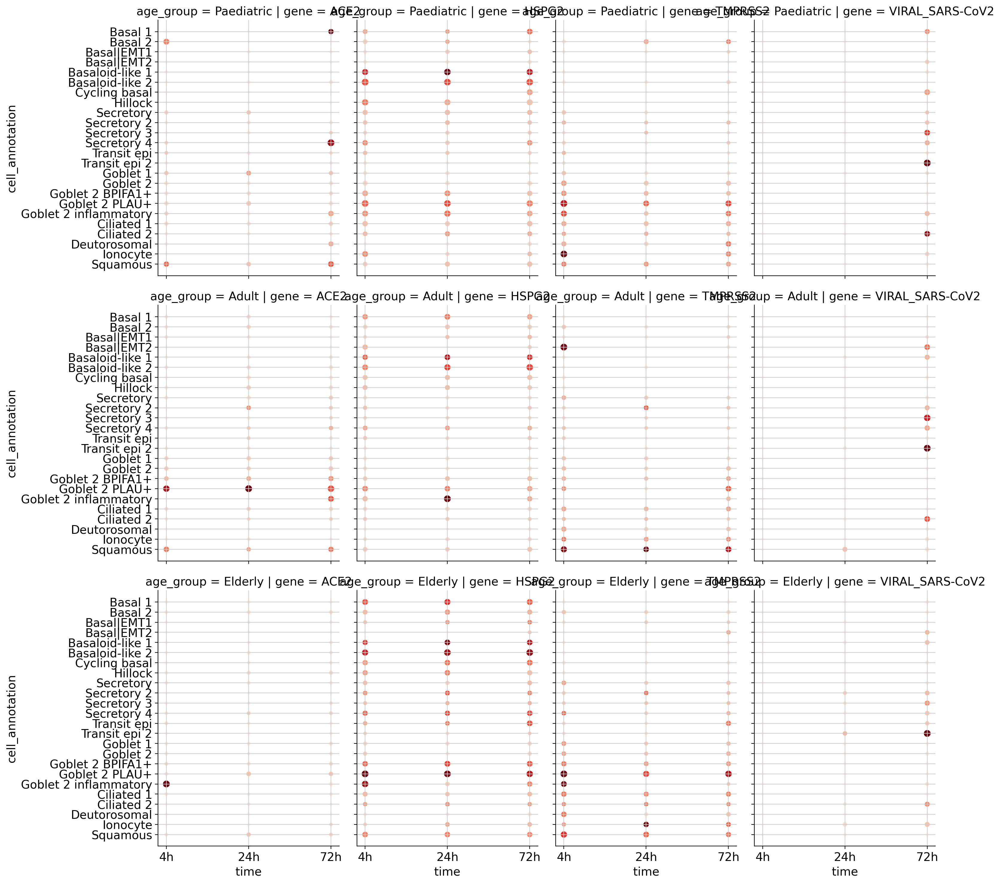

In [ ]:
g = sns.FacetGrid(
    dot_df,
    col="gene",
    row="age_group",
    sharey=True,
    height=5,
    aspect=0.8
)

g.map_dataframe(
    sns.scatterplot,
    x="time",
    y="cell_annotation",
    size="pct_expr",
    hue="mean_expr",
    legend=False,
    palette = "Reds"
)

In [ ]:
Woodall_inVitro_adata

AnnData object with n_obs × n_vars = 139598 × 26447
    obs: 'sample', 'treatment', 'time', 'pool', 'sample_name', 'kit_version', 'spike-in_primer', 'scrublet_score', 'doublet_bh_pval', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'souporcell_cluster', 'donor_id', 'age_group', 'gender', 'S_score', 'G2M_score', 'phase', 'bbknn_batch', 'cell_annotation', 'age_treatment', 'score_IFN_alpha', 'score_IFN_gamma', 'score_BASALOID'
    var: 'gene_ids', 'n_counts', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'ribo'
    uns: 'age_group_colors', 'age_treatment_colors', 'cell_annotation_colors', 'donor_id_colors', 'kit_version_colors', 'pool_colors', 'sample_colors', 'spike-in_primer_colors', 'treatment_colors'
    obsm: 'X_pca', 'X_umap'
    obsp: 'connectivities', 'distances'

In [ ]:
# Woodall_inVitro_adata.X

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 273690640 stored elements and shape (139598, 26447)>

In [8]:
Woodall_inVitro_adata_sub = Woodall_inVitro_adata[
    Woodall_inVitro_adata.obs["cell_annotation"].isin(["Basal|EMT2","Basaloid-like 2"]) &
    # woodall_adata.obs["age_status"].isin(["paediatric-Healthy","paediatric-COVID19"])
    Woodall_inVitro_adata.obs["age_group"].isin(["Elderly"]) &
    Woodall_inVitro_adata.obs["time"].isin(["72h"])
    ].copy()
# Woodall_inVitro_adata_sub.X = Woodall_inVitro_adata_sub.layers["raw_counts"]

NameError: name 'Woodall_inVitro_adata' is not defined

In [ ]:
# Woodall_inVitro_adata_sub

AnnData object with n_obs × n_vars = 427 × 26447
    obs: 'sample', 'treatment', 'time', 'pool', 'sample_name', 'kit_version', 'spike-in_primer', 'scrublet_score', 'doublet_bh_pval', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'souporcell_cluster', 'donor_id', 'age_group', 'gender', 'S_score', 'G2M_score', 'phase', 'bbknn_batch', 'cell_annotation', 'age_treatment', 'score_IFN_alpha', 'score_IFN_gamma', 'score_BASALOID'
    var: 'gene_ids', 'n_counts', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'ribo'
    uns: 'age_group_colors', 'age_treatment_colors', 'cell_annotation_colors', 'donor_id_colors', 'kit_version_colors', 'pool_colors', 'sample_colors', 'spike-in_primer_colors', 'treatment_colors'
    obsm: 'X_pca', 'X_umap'
    obsp: 'connectivities', 'distances'

In [ ]:
# woodall_pb = dc.pp.pseudobulk(
#     adata = Woodall_inVitro_adata_sub,
#     sample_col = "cell_annotation",
#     groups_col = "sample_name",
#     layer = "raw_counts",
#     mode = "sum",
#     # min_cells = 10,
#     # min_counts = 10
# )
# # woodall_pb.layers['raw_counts'] = woodall_pb.X.copy()
# # sc.pp.normalize_total(woodall_pb, target_sum=1e4)
# # sc.pp.log1p(woodall_pb)
# # sc.pp.scale(woodall_pb, max_value=10)
# # sc.tl.pca(woodall_pb)
# # # Return raw counts to X
# # dc.swap_layer(woodall_pb, 'raw_counts', X_layer_key=None, inplace=True)

# woodall_pb

AssertionError: Provided data contains float (decimal) values.
             Check the parameters raw and layers to determine if you are selecting the correct matrix.
             If decimal values are to be expected, override this error by setting skip_checks=True

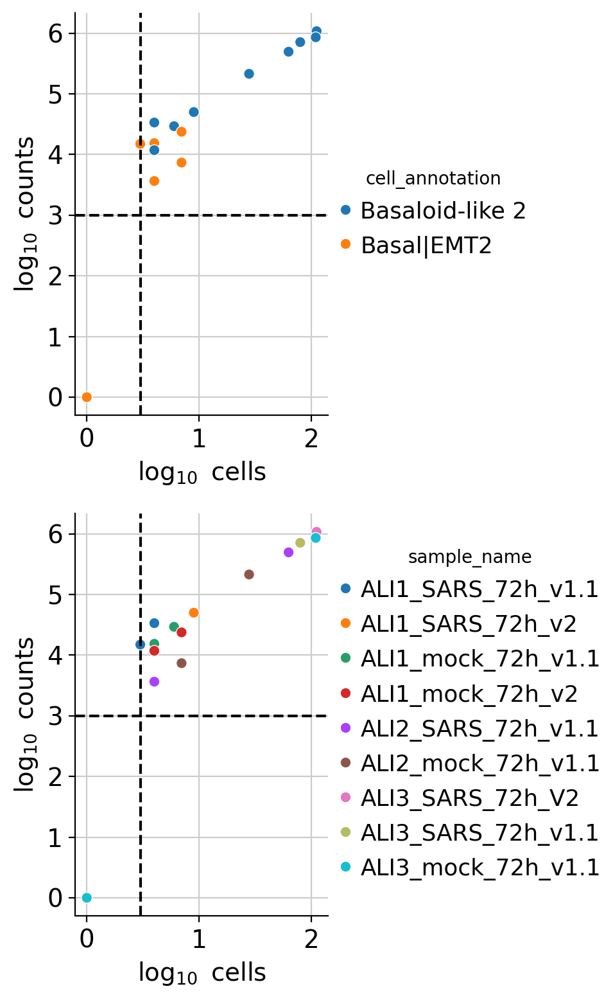

In [ ]:
# dc.pl.filter_samples(
#     adata=woodall_pb,
#     groupby=["cell_annotation", "sample_name"],
#     min_cells=3,
#     min_counts=1000,
#     figsize=(5, 8),
# )

In [ ]:
# dc.pp.filter_samples(woodall_pb, min_cells=3, min_counts=1000)

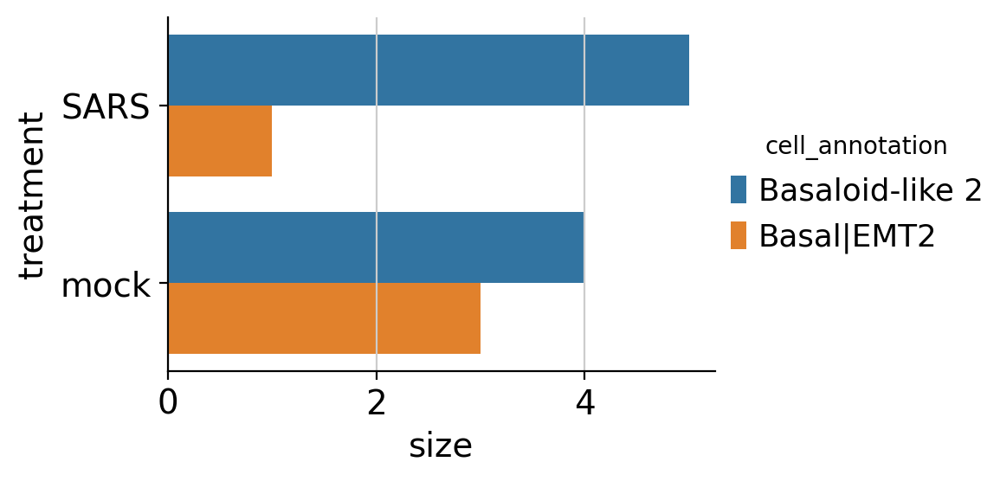

In [ ]:
# dc.pl.obsbar(adata=woodall_pb, y="treatment", hue="cell_annotation", figsize=(6, 3))

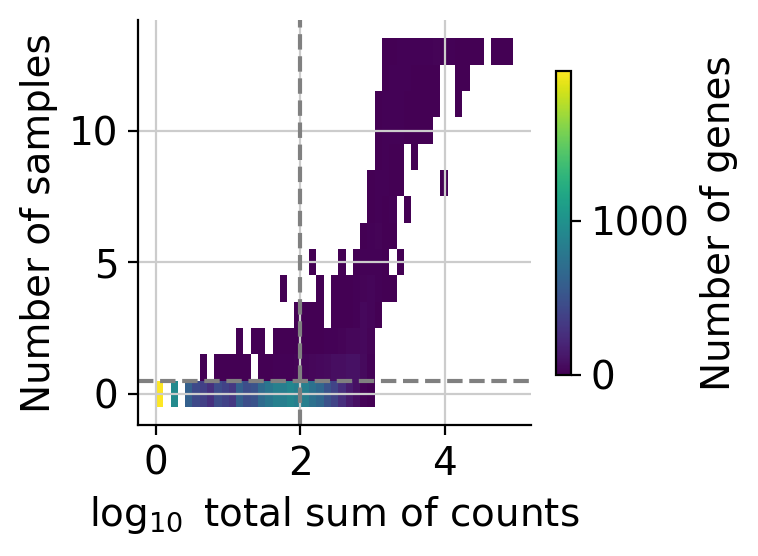

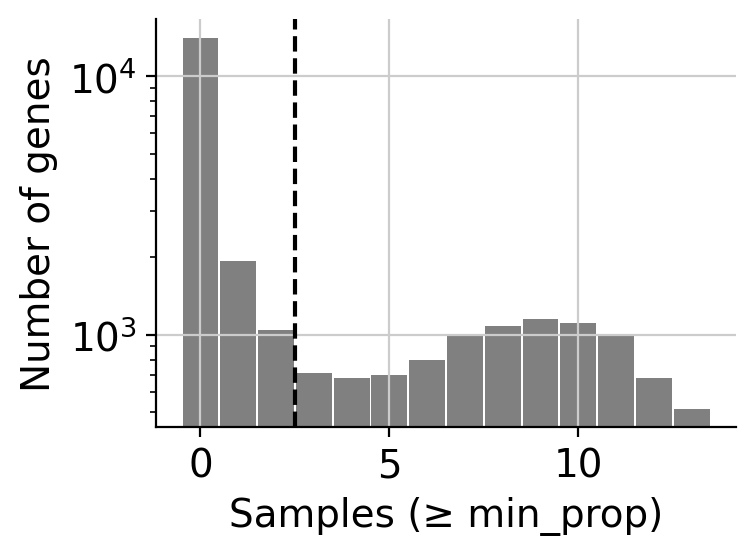

In [ ]:
# dc.pl.filter_by_expr(
#     adata=woodall_pb,
#     group="sample_name",
#     min_count=10,min_total_count=100,
#     large_n=5,
#     min_prop=0.7,
# )
# dc.pl.filter_by_prop(
#     adata=woodall_pb,
#     min_prop=0.1,
#     min_smpls=3,
# )

In [ ]:
# dc.pp.filter_by_expr(
#     adata=woodall_pb,
#     group="sample_name",
#     min_count=10,min_total_count=100,
#     large_n=5,
#     min_prop=0.7,
# )
# dc.pp.filter_by_prop(
#     adata=woodall_pb,
#     min_prop=0.1,
#     min_smpls=3,
# )

In [ ]:
# # Build DESeq2 object
# inference = DefaultInference(n_cpus=1)
# dds = DeseqDataSet(
#     adata=woodall_pb,
#     design_factors=["cell_annotation","bbknn_batch"],
#     refit_cooks=True,
#     inference=inference,
# )

# # Compute LFCs
# dds.deseq2()

# # Extract contrast between conditions
# stat_res = DeseqStats(dds, contrast=["cell_annotation", "Basaloid-like 2","Basal|EMT2"], inference=inference)

# # Compute Wald test
# stat_res.summary()

/tmp/ipykernel_2033028/3863467036.py:3: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds = DeseqDataSet(
Fitting size factors...
... done in 0.00 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 1.38 seconds.

Fitting dispersion trend curve...
/home/mark/miniconda3/envs/decoupler/lib/python3.12/site-packages/pydeseq2/dds.py:822: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)
... done in 0.02 seconds.

Fitting MAP dispersions...
... done in 1.08 seconds.

Fitting LFCs...


Log2 fold change & Wald test p-value: cell_annotation Basaloid-like 2 vs Basal|EMT2
                   baseMean  log2FoldChange     lfcSE      stat    pvalue  \
HES4              17.988656        0.260052  0.632548  0.411118  0.680986   
AGRN              14.125719        1.043991  0.652422  1.600176  0.109559   
AURKAIP1          15.178198        0.984722  0.567251  1.735954  0.082572   
CCNL2              6.768228       -0.443305  0.696167 -0.636779  0.524269   
SSU72             13.412938        0.366246  0.573143  0.639013  0.522814   
...                     ...             ...       ...       ...       ...   
MT-ND4           277.145802        0.680548  0.332074  2.049388  0.040424   
MT-ND5           170.685446        0.658047  0.431062  1.526572  0.126867   
MT-ND6            39.745521        0.296020  0.393959  0.751398  0.452413   
MT-CYB           376.087097        0.248757  0.285457  0.871434  0.383517   
VIRAL_SARS-CoV2   14.149382        0.132903  3.257908  0.040794  0.96

... done in 0.90 seconds.

Calculating cook's distance...
... done in 0.00 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 0.13 seconds.



In [ ]:
# # Extract results
# results_df = stat_res.results_df
# results_df

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
HES4,17.988656,0.260052,0.632548,0.411118,0.680986,0.824310
AGRN,14.125719,1.043991,0.652422,1.600176,0.109559,0.302626
AURKAIP1,15.178198,0.984722,0.567251,1.735954,0.082572,0.257120
CCNL2,6.768228,-0.443305,0.696167,-0.636779,0.524269,0.715245
SSU72,13.412938,0.366246,0.573143,0.639013,0.522814,0.713973
...,...,...,...,...,...,...
MT-ND4,277.145802,0.680548,0.332074,2.049388,0.040424,0.171812
MT-ND5,170.685446,0.658047,0.431062,1.526572,0.126867,0.328462
MT-ND6,39.745521,0.296020,0.393959,0.751398,0.452413,0.651824
MT-CYB,376.087097,0.248757,0.285457,0.871434,0.383517,0.599849


In [ ]:
# log2fc_cutoff = 0.5
# padj_cutoff = 0.05
# top_n = 20
# custom_genes = ["HSPG2","TMPRSS2","ACE2","HSPE1","VIRAL_SARS-CoV2","ISG15","IFITM1","IFIT1","IFIT2","ITGB6"]

In [ ]:
# results_df[results_df.index.isin(custom_genes)]

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
HSPG2,16.719276,2.475284,0.960554,2.576934,0.009968,0.081494
ITGB6,31.255133,2.172878,0.645181,3.367858,0.000758,0.014977
HSPE1,12.425930,-0.828848,0.514888,-1.609765,0.107449,0.300990
VIRAL_SARS-CoV2,14.149382,0.132903,3.257908,0.040794,0.967460,0.983701


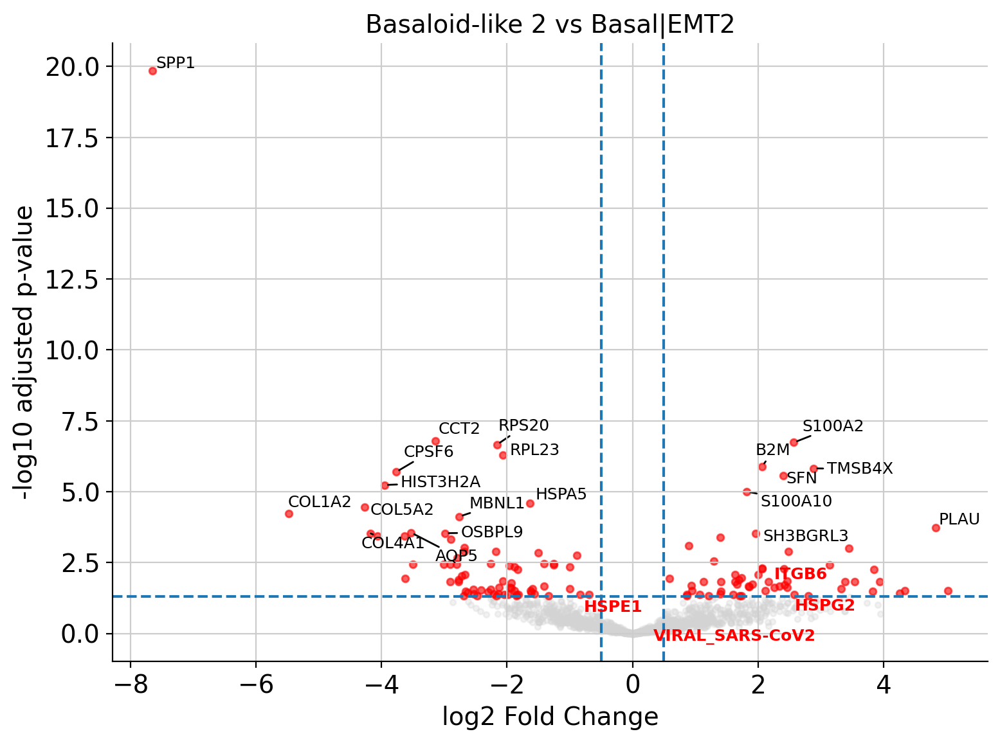

In [ ]:
# df = results_df.copy()

# # Clean
# df = df.dropna(subset=["log2FoldChange", "padj"])
# df["neglog10_padj"] = -np.log10(df["padj"])

# # Significant points
# sig_mask = (
#     (df["padj"] < padj_cutoff) &
#     (np.abs(df["log2FoldChange"]) > log2fc_cutoff)
# )

# # Top genes by padj
# top_genes = (
#     df.sort_values("pvalue")
#       .head(top_n)
#       .index
# )

# # Genes to label
# label_genes = set(top_genes).union(custom_genes)

# # ---- Plot ----
# plt.figure(figsize=(8, 6))

# # Background
# plt.scatter(
#     df["log2FoldChange"],
#     df["neglog10_padj"],
#     c="lightgrey",
#     s=10,
#     alpha=0.3
# )

# # Significant points in red
# plt.scatter(
#     df.loc[sig_mask, "log2FoldChange"],
#     df.loc[sig_mask, "neglog10_padj"],
#     c="red",
#     s=15,
#     alpha=0.6
# )

# # Threshold lines
# plt.axhline(-np.log10(padj_cutoff), linestyle="--")
# plt.axvline(log2fc_cutoff, linestyle="--")
# plt.axvline(-log2fc_cutoff, linestyle="--")

# # ---- Labels with color logic ----
# texts = []

# for gene in label_genes:
#     if gene not in df.index:
#         continue

#     color = "red" if gene in custom_genes else "black"

#     texts.append(
#         plt.text(
#             df.loc[gene, "log2FoldChange"],
#             df.loc[gene, "neglog10_padj"],
#             gene,
#             fontsize=9,
#             color=color,
#             weight="bold" if gene in custom_genes else "normal"
#         )
#     )

# adjust_text(texts, arrowprops=dict(arrowstyle="-", lw=1))

# # Labels
# plt.xlabel("log2 Fold Change")
# plt.ylabel("-log10 adjusted p-value")
# plt.title("Basaloid-like 2 vs Basal|EMT2")

# plt.tight_layout()
# plt.show()

### compare ciliated 1 vs ciliated 2 (ciliated 2 seems to be more infected?)

In [ ]:
Woodall_inVitro_adata

AnnData object with n_obs × n_vars = 139598 × 26447
    obs: 'sample', 'treatment', 'time', 'pool', 'sample_name', 'kit_version', 'spike-in_primer', 'scrublet_score', 'doublet_bh_pval', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'souporcell_cluster', 'donor_id', 'age_group', 'gender', 'S_score', 'G2M_score', 'phase', 'bbknn_batch', 'cell_annotation', 'age_treatment', 'score_IFN_alpha', 'score_IFN_gamma', 'score_BASALOID'
    var: 'gene_ids', 'n_counts', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'ribo'
    uns: 'age_group_colors', 'age_treatment_colors', 'cell_annotation_colors', 'donor_id_colors', 'kit_version_colors', 'pool_colors', 'sample_colors', 'spike-in_primer_colors', 'treatment_colors'
    obsm: 'X_pca', 'X_umap'
    obsp: 'connectivities', 'distances'

### pseudotime analysis - palantir

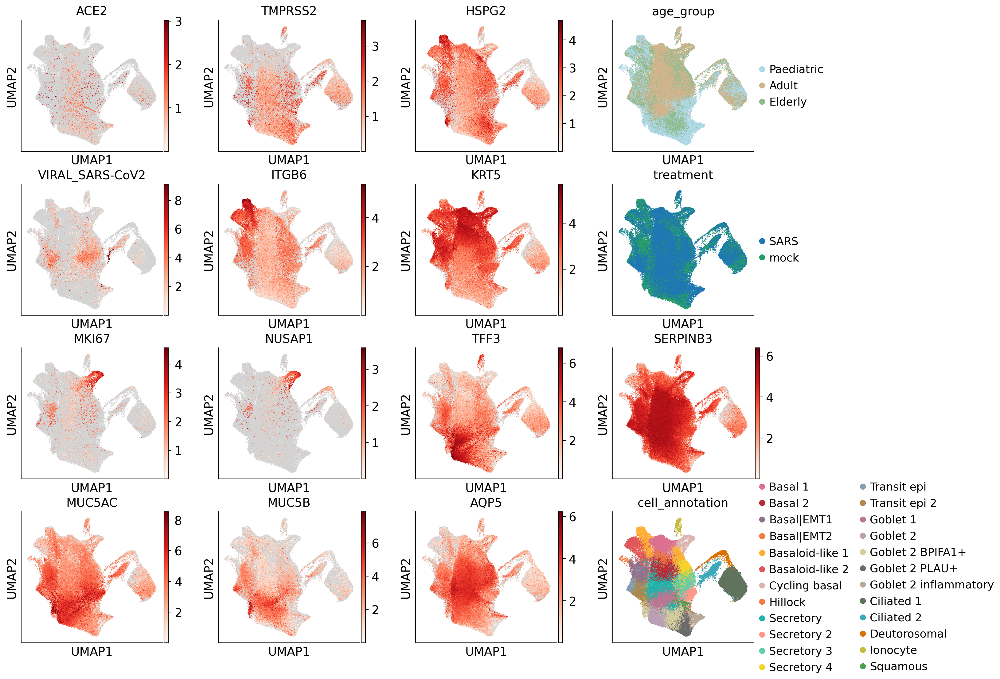

In [19]:
with rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        adata = Woodall_inVitro_adata,
        color = [
            "ACE2", "TMPRSS2","HSPG2","age_group",
            "VIRAL_SARS-CoV2","ITGB6","KRT5","treatment",
            "MKI67","NUSAP1", # basal
            "TFF3", "SERPINB3", "MUC5AC", "MUC5B","AQP5", # goblet1
            "cell_annotation"],
        ncols=4,size=3,
        use_raw=False,
        color_map=reds,vmin=0.00001,
        show=False
        # layer="soupX",
    )

In [20]:
dm_res = palantir.utils.run_diffusion_maps(Woodall_inVitro_adata, n_components=10)
ms_data = palantir.utils.determine_multiscale_space(Woodall_inVitro_adata)

In [21]:
imputed_X = palantir.utils.run_magic_imputation(Woodall_inVitro_adata)

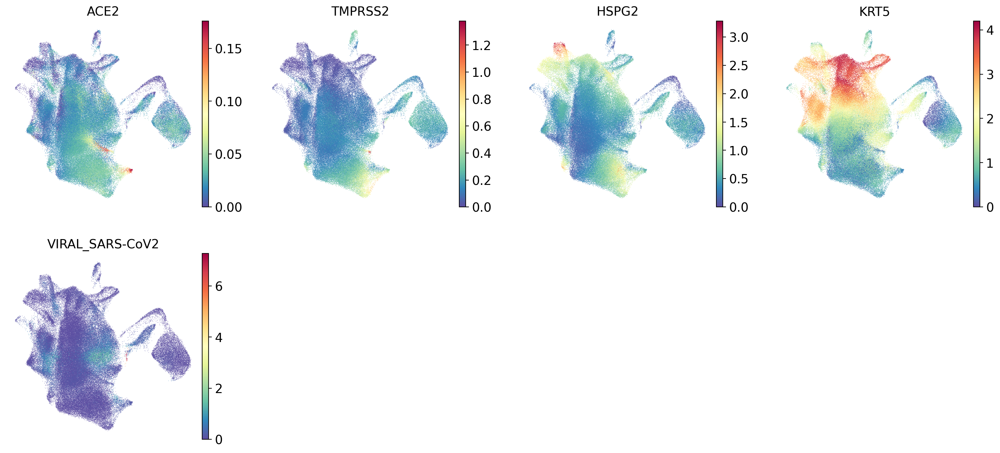

In [22]:
sc.pl.embedding(
    Woodall_inVitro_adata,
    basis="umap",
    layer="MAGIC_imputed_data",
    color=["ACE2","TMPRSS2","HSPG2","KRT5","VIRAL_SARS-CoV2"],
    frameon=False,
)
plt.show()

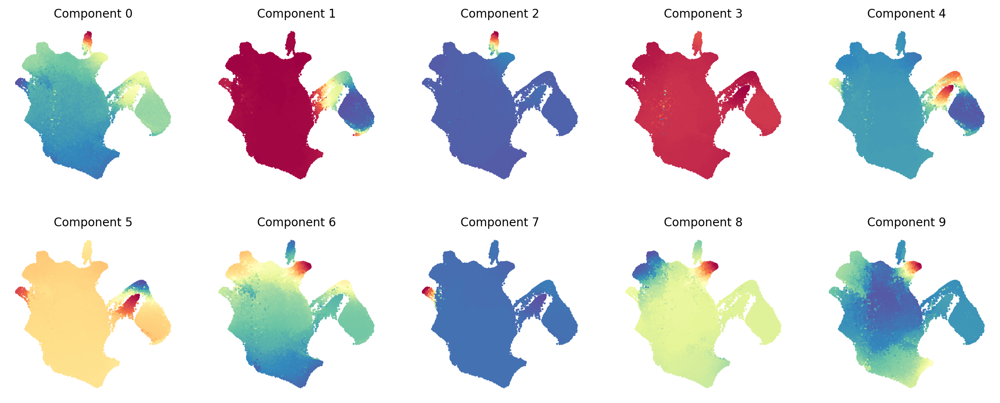

In [23]:
palantir.plot.plot_diffusion_components(Woodall_inVitro_adata)
plt.show()

In [24]:
max_basal_cell = (Woodall_inVitro_adata[:, [g for g in ["KRT5","MKI67","NUSAP1"] if g in Woodall_inVitro_adata.var_names]].to_df().sum(axis=1).idxmax())
max_basaloid2_cell = (Woodall_inVitro_adata[:, [g for g in ["KRT5","VIM","ITGB6"] if g in Woodall_inVitro_adata.var_names]].to_df().sum(axis=1).idxmax())
max_globet1_cell = (Woodall_inVitro_adata[:, [g for g in ["TFF3", "SERPINB3", "MUC5AC", "MUC5B","AQP5"] if g in Woodall_inVitro_adata.var_names]].to_df().sum(axis=1).idxmax())
max_goblet2_inflam_cell = (Woodall_inVitro_adata[:, [g for g in ["TFF3", "SERPINB3", "MUC5AC", "MUC5B","AQP5","IFIT3","IFIT1","OAS1"] if g in Woodall_inVitro_adata.var_names]].to_df().sum(axis=1).idxmax())
max_ciliated1_cell = (Woodall_inVitro_adata[:, [g for g in ["OMG","PIFO","FOXJ1"] if g in Woodall_inVitro_adata.var_names]].to_df().sum(axis=1).idxmax())
marker_states = pd.Series(
    ["basal_cycling","basaloid2","goblet1","goblet2_inflammatory","ciliated1"],
    index=[max_basal_cell,max_basaloid2_cell,max_globet1_cell,max_goblet2_inflam_cell,max_ciliated1_cell]
)

terminal_states = pd.Series(
    ["basaloid2","goblet2_inflammatory","ciliated1"],
    index=[max_basaloid2_cell,max_goblet2_inflam_cell,max_ciliated1_cell]
)

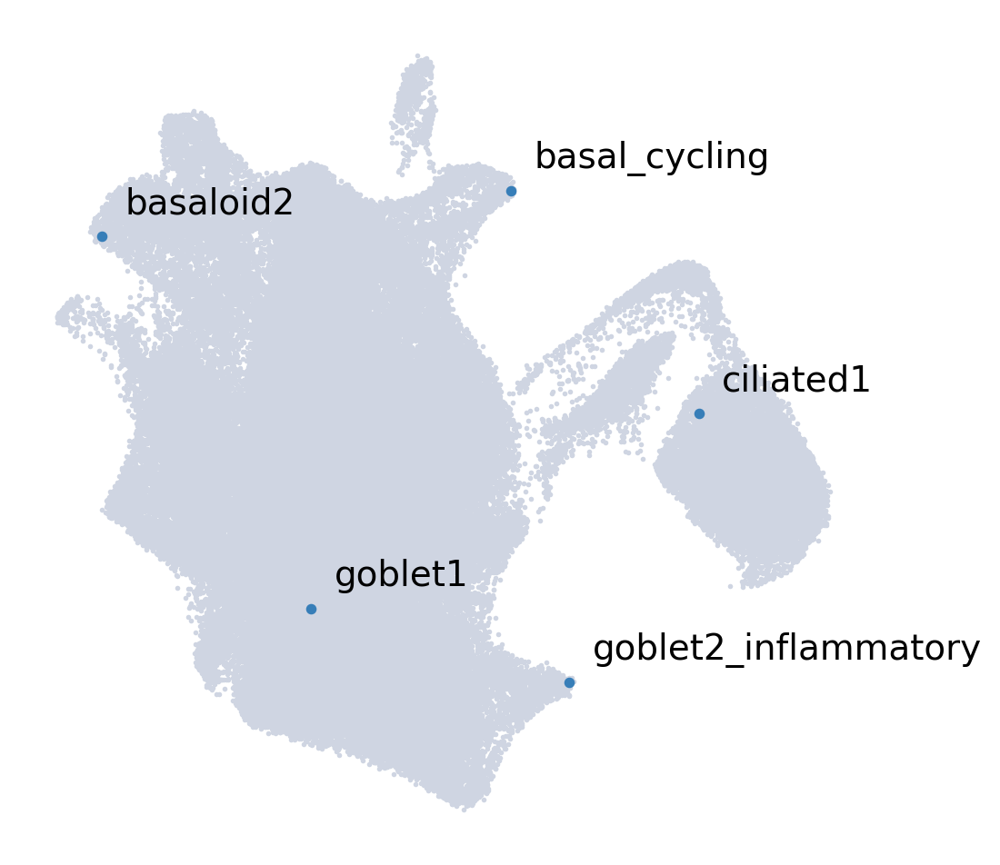

In [25]:
palantir.plot.highlight_cells_on_umap(Woodall_inVitro_adata, marker_states)
plt.show()

In [26]:
Woodall_inVitro_adata.obs

,sample,treatment,time,pool,sample_name,kit_version,spike-in_primer,scrublet_score,doublet_bh_pval,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,souporcell_cluster,donor_id,age_group,gender,S_score,G2M_score,phase,bbknn_batch,cell_annotation,age_treatment,score_IFN_alpha,score_IFN_gamma,score_BASALOID
CV001_KM10202575_AAACCTGAGCAGGTCA,CV001_KM10202575,mock,4h,ALI2,ALI2_mock_4h_v1.1,v1.1,spike-in_LOW,0.074489,0.899867,2007,5978.355469,321.375763,5.375655,508.158630,8.499973,CV001_KM10202575_cluster_3,UCL_10,Adult,Female,0.012715,-0.122299,S,ALI2-v1.1,Goblet 2,Adult-mock,0.164289,0.242595,0.184872
CV001_KM10202575_AAACCTGAGCCAGTTT,CV001_KM10202575,mock,4h,ALI2,ALI2_mock_4h_v1.1,v1.1,spike-in_LOW,0.182796,0.899867,1936,4667.351074,422.780762,9.058259,661.751038,14.178300,CV001_KM10202575_cluster_3,UCL_10,Adult,Female,0.016216,-0.056671,S,ALI2-v1.1,Goblet 2 BPIFA1+,Adult-mock,0.437474,0.173749,0.107360
CV001_KM10202575_AAACCTGAGCGTAGTG,CV001_KM10202575,mock,4h,ALI2,ALI2_mock_4h_v1.1,v1.1,spike-in_LOW,0.216327,0.861171,1072,1869.545410,250.455383,13.396592,145.099289,7.761207,CV001_KM10202575_cluster_3,UCL_10,Adult,Female,-0.039390,-0.012464,G1,ALI2-v1.1,Goblet 2 BPIFA1+,Adult-mock,0.132267,0.212443,0.219769
CV001_KM10202575_AAACCTGAGCTCCTTC,CV001_KM10202575,mock,4h,ALI2,ALI2_mock_4h_v1.1,v1.1,spike-in_LOW,0.066090,0.915221,1637,3787.764160,370.476379,9.780872,560.797424,14.805500,CV001_KM10202575_cluster_0,UCL_6,Elderly,Female,0.077160,-0.175455,S,ALI2-v1.1,Basal 2,Elderly-mock,-0.093077,0.058059,0.175730
CV001_KM10202575_AAACCTGAGCTGGAAC,CV001_KM10202575,mock,4h,ALI2,ALI2_mock_4h_v1.1,v1.1,spike-in_LOW,0.187805,0.899867,1742,3958.839111,313.766357,7.925716,601.522949,15.194427,CV001_KM10202575_cluster_1,UCL_5,Elderly,Female,0.012258,-0.066333,S,ALI2-v1.1,Basal 1,Elderly-mock,0.123714,0.150537,0.051336
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CV001_KM9505916_TTTGTCAGTTCCATGA,CV001_KM9505916,SARS,72h,ALI3,ALI3_SARS_72h_V2,v2,spike-in_HIGH,0.152639,0.937426,2169,4808.247559,338.860718,7.047489,476.731720,9.914875,CV001_KM9505916_cluster_3,UCL_7,Elderly,Male,-0.028217,-0.130824,G1,ALI3-v2,Goblet 2 BPIFA1+,Elderly-SARS,0.176980,0.129034,0.282540
CV001_KM9505916_TTTGTCATCACGATGT,CV001_KM9505916,SARS,72h,ALI3,ALI3_SARS_72h_V2,v2,spike-in_HIGH,0.220339,0.922660,1480,2611.079102,262.215332,10.042413,227.407578,8.709333,CV001_KM9505916_cluster_2,UCL_11,Adult,Female,-0.042824,-0.144969,G1,ALI3-v2,Secretory,Adult-SARS,-0.045456,0.129736,0.034195
CV001_KM9505916_TTTGTCATCCCATTAT,CV001_KM9505916,SARS,72h,ALI3,ALI3_SARS_72h_V2,v2,spike-in_HIGH,0.129771,0.937426,1571,3220.570801,172.535034,5.357281,616.526855,19.143402,CV001_KM9505916_cluster_0,UCL_12,Adult,Female,-0.027907,-0.138610,G1,ALI3-v2,Basal 2,Adult-SARS,-0.051619,0.112761,0.082636
CV001_KM9505916_TTTGTCATCCGGGTGT,CV001_KM9505916,SARS,72h,ALI3,ALI3_SARS_72h_V2,v2,spike-in_HIGH,0.065327,0.985310,2861,9856.480469,100.517784,1.019814,948.763733,9.625786,CV001_KM9505916_cluster_1,UCL_9,Paediatric,Male,-0.057059,-0.149032,G1,ALI3-v2,Goblet 2 BPIFA1+,Paediatric-SARS,0.194762,0.217395,0.012546


In [27]:
early_cell = palantir.utils.early_cell(Woodall_inVitro_adata, celltype="Cycling basal", celltype_column="cell_annotation")
early_cell

Using CV001_KM9505821_CTGATAGAGATGAGAG for cell type Cycling basal which is max in diffusion component 5.


'CV001_KM9505821_CTGATAGAGATGAGAG'

In [28]:
import importlib
importlib.reload(palantir.core)
importlib.reload(palantir.presults)

<module 'palantir.presults' from '/home/mark/miniconda3/envs/decoupler/lib/python3.12/site-packages/palantir/presults.py'>

In [29]:
# trajectory for basal
pr_res = palantir.core.run_palantir(
    data = Woodall_inVitro_adata,early_cell = max_basal_cell, num_waypoints=500, terminal_states=terminal_states)

Sampling and flocking waypoints...
Time for determining waypoints: 0.0004259745279947917 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.6966465989748637 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9998
Correlation at iteration 2: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...


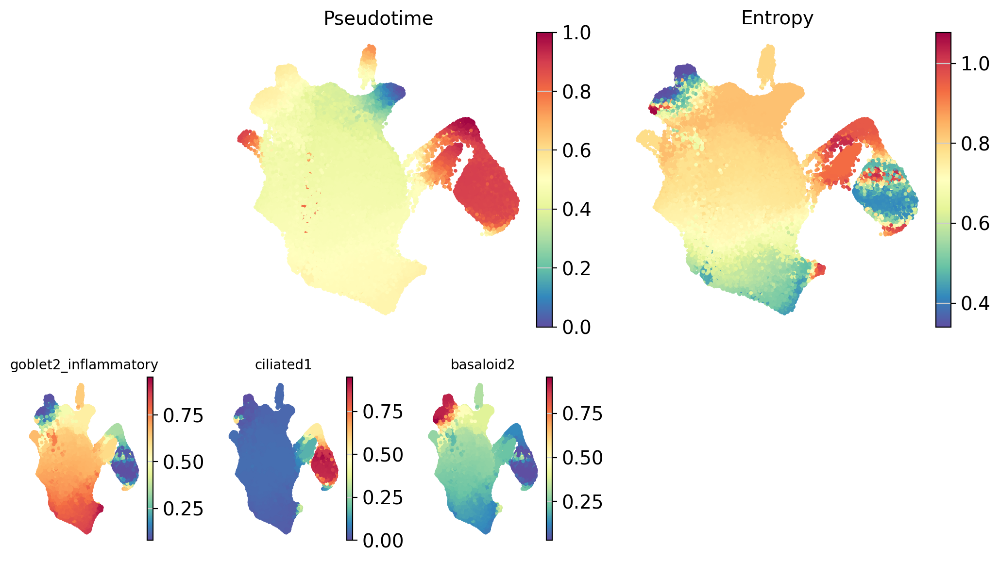

In [30]:
palantir.plot.plot_palantir_results(Woodall_inVitro_adata, s=3)
plt.show()

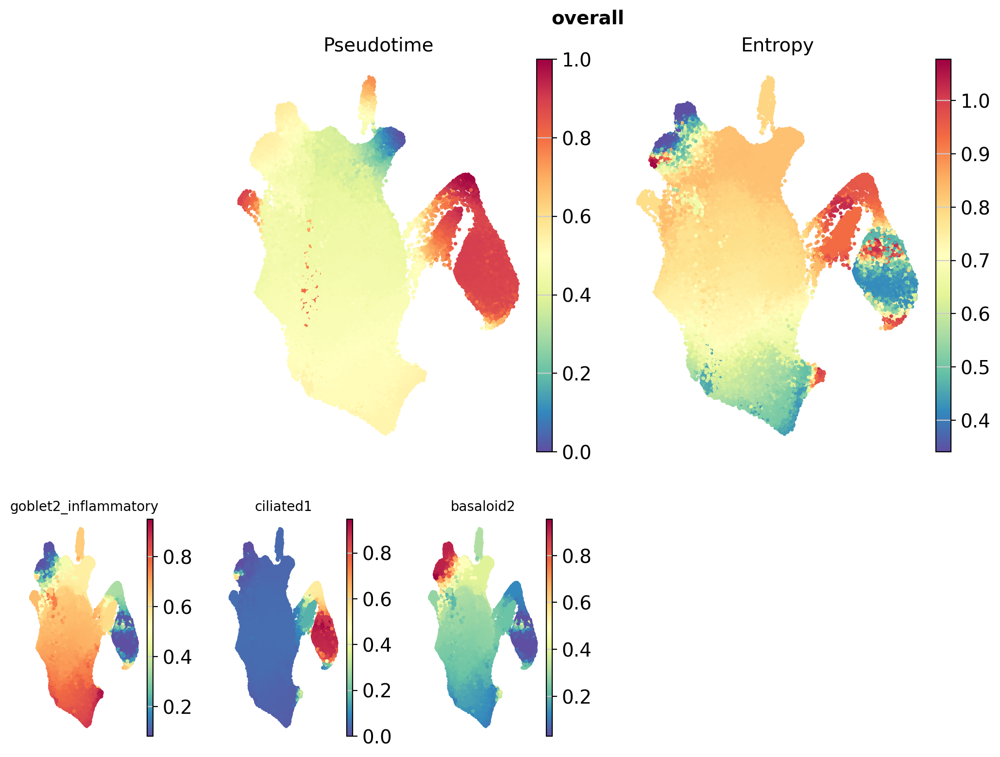

In [32]:
fig = palantir.plot.plot_palantir_results(Woodall_inVitro_adata, s=3)
# add a title
fig.set_size_inches(12,8)  # width=12 inches, height=8 inches
fig.suptitle("overall", fontsize=14,x=0.5,y=0.99,fontweight="bold",ha="center")
fig.savefig("figures/lung/Woodall_invitro_pseudotime_umap.pdf",dpi=300,format="pdf", bbox_inches="tight")
plt.show()

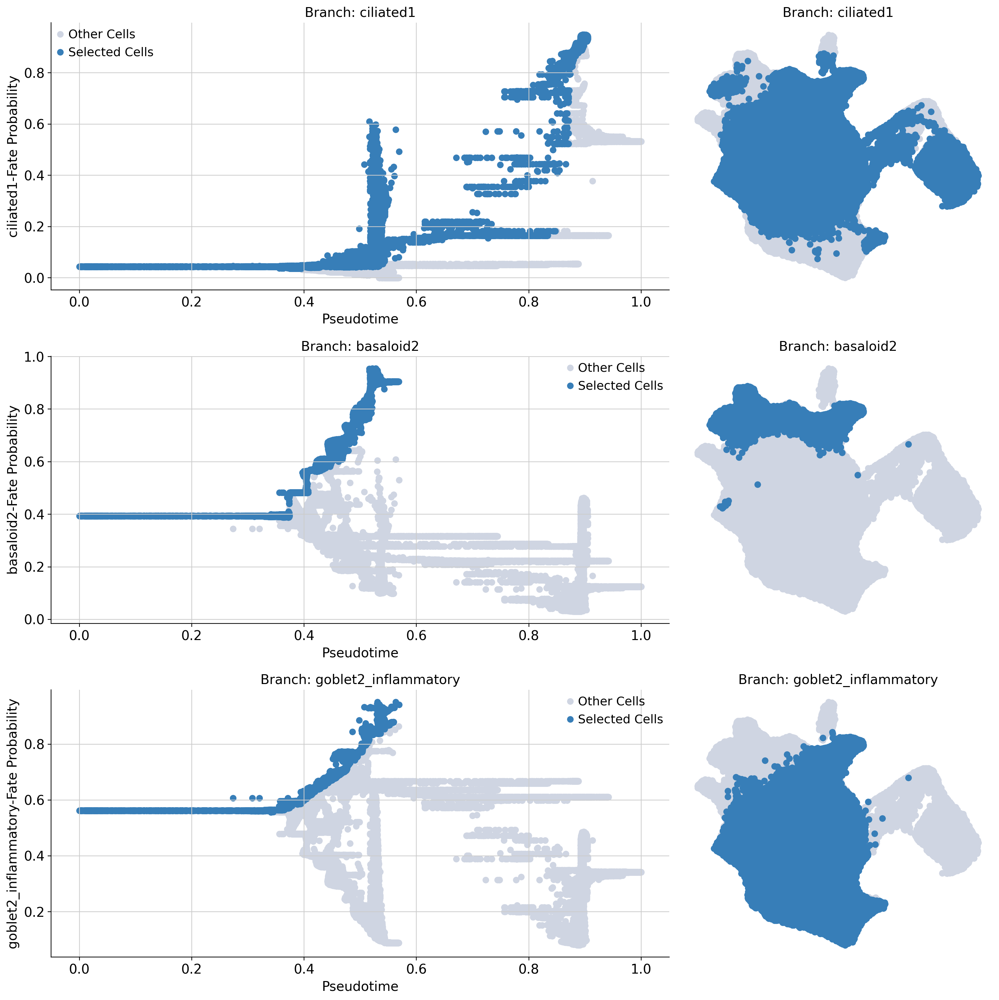

In [33]:
masks = palantir.presults.select_branch_cells(Woodall_inVitro_adata, q=.01, eps=.01)
palantir.plot.plot_branch_selection(Woodall_inVitro_adata)
plt.show()

[2026-09-25 01:31:30,024] [INFO    ] Using sparse Gaussian Process since n_landmarks (50) < n_samples (10,406) and rank = 1.0.
[2026-09-25 01:31:30,024] [INFO    ] Using covariance function Matern52(ls=1.5719350814819335).
[2026-09-25 01:31:30,038] [INFO    ] Computing 50 landmarks with k-means clustering (random_state=42).


[2026-09-25 01:31:31,396] [INFO    ] Sigma interpreted as element-wise standard deviation.


<Axes: title={'center': 'Branch: basaloid2'}>

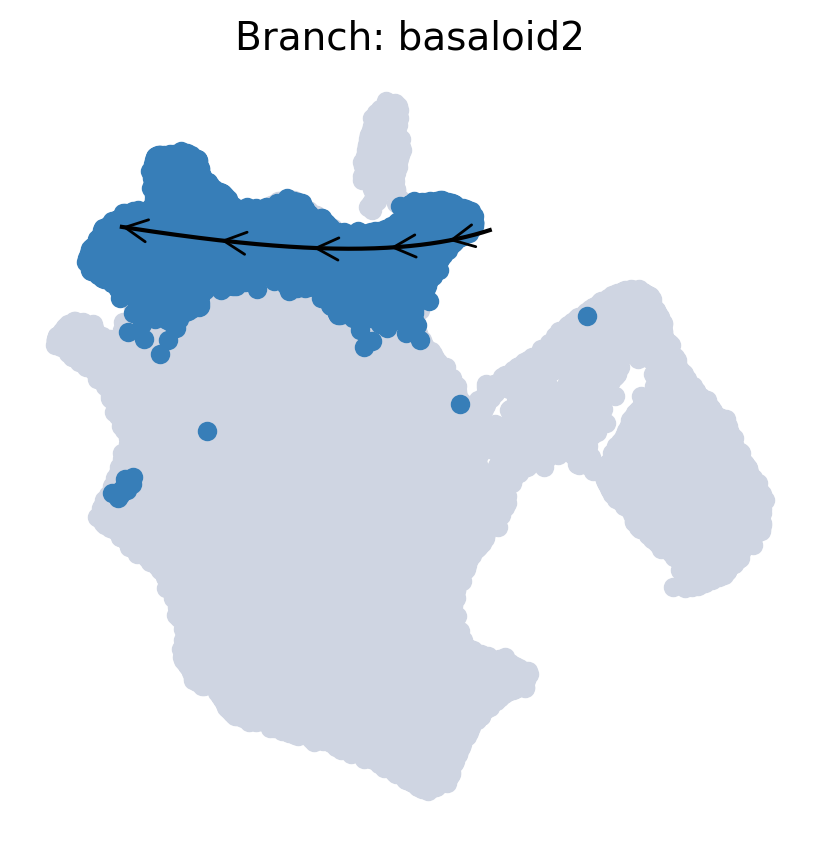

In [34]:
palantir.plot.plot_trajectory(Woodall_inVitro_adata, "basaloid2")

[2026-09-25 01:31:32,472] [INFO    ] Using sparse Gaussian Process since n_landmarks (50) < n_samples (98,332) and rank = 1.0.
[2026-09-25 01:31:32,473] [INFO    ] Using covariance function Matern52(ls=1.5719350814819335).
[2026-09-25 01:31:32,488] [INFO    ] Computing 50 landmarks with k-means clustering (random_state=42).


[2026-09-25 01:31:33,282] [INFO    ] Sigma interpreted as element-wise standard deviation.


<Axes: title={'center': 'Branch: goblet2_inflammatory'}>

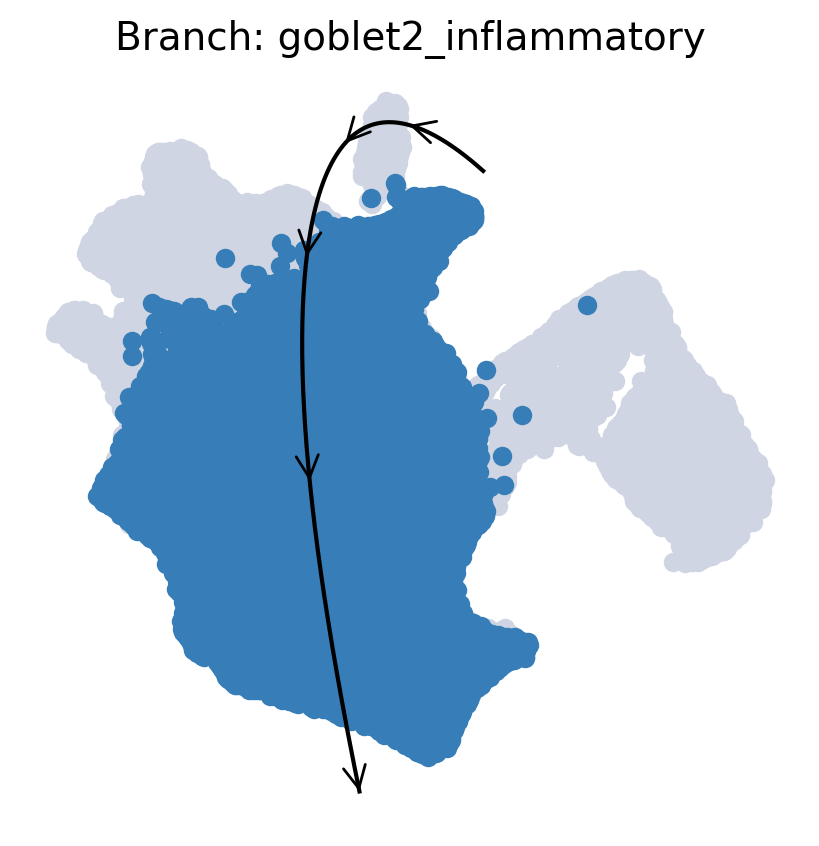

In [35]:
palantir.plot.plot_trajectory(Woodall_inVitro_adata, "goblet2_inflammatory")

[2026-09-25 01:31:33,795] [INFO    ] Using sparse Gaussian Process since n_landmarks (50) < n_samples (105,421) and rank = 1.0.
[2026-09-25 01:31:33,795] [INFO    ] Using covariance function Matern52(ls=1.5719350814819335).
[2026-09-25 01:31:33,808] [INFO    ] Computing 50 landmarks with k-means clustering (random_state=42).
[2026-09-25 01:31:34,687] [INFO    ] Sigma interpreted as element-wise standard deviation.


<Axes: title={'center': 'Branch: ciliated1'}>

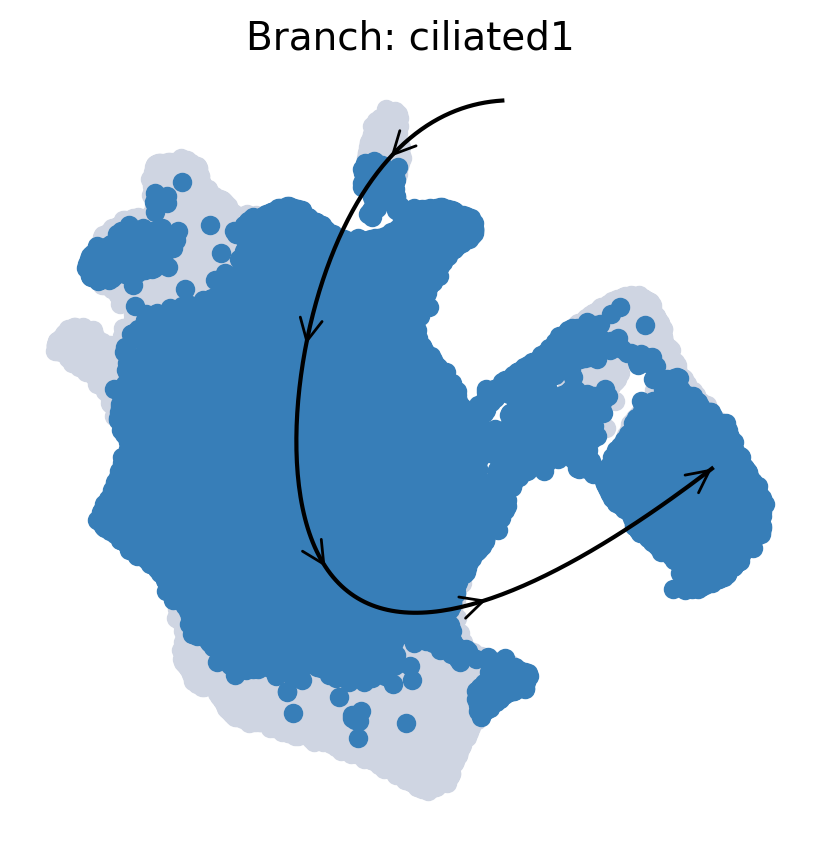

In [36]:
palantir.plot.plot_trajectory(Woodall_inVitro_adata, "ciliated1")

In [37]:
gene_trends = palantir.presults.compute_gene_trends(
    Woodall_inVitro_adata,
    expression_key="MAGIC_imputed_data",
)

/home/mark/miniconda3/envs/decoupler/lib/python3.12/site-packages/palantir/presults.py:270: FutureWarning: Use obs (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`) instead of AnnData.obs_keys, AnnData.obs_keys is deprecated and will be removed in the future.
  if pseudo_time_key not in ad.obs_keys():


goblet2_inflammatory
[2026-09-25 01:32:19,411] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (98,332) and rank = 1.0.
[2026-09-25 01:32:19,412] [INFO    ] Using covariance function Matern52(ls=1.0).
[2026-09-25 01:32:21,499] [INFO    ] Sigma interpreted as element-wise standard deviation.
ciliated1
[2026-09-25 01:32:48,814] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (105,421) and rank = 1.0.
[2026-09-25 01:32:48,815] [INFO    ] Using covariance function Matern52(ls=1.0).
[2026-09-25 01:32:50,438] [INFO    ] Sigma interpreted as element-wise standard deviation.
basaloid2
[2026-09-25 01:33:02,968] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (10,406) and rank = 1.0.
[2026-09-25 01:33:02,969] [INFO    ] Using covariance function Matern52(ls=1.0).
[2026-09-25 01:33:03,598] [INFO    ] Sigma interpreted as element-wise standard deviation.


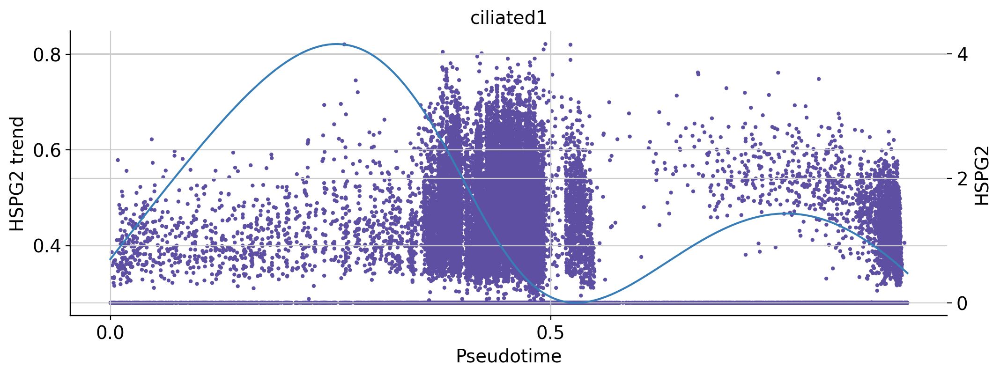

In [43]:
palantir.plot.plot_trend(Woodall_inVitro_adata,"ciliated1","HSPG2")
plt.show()

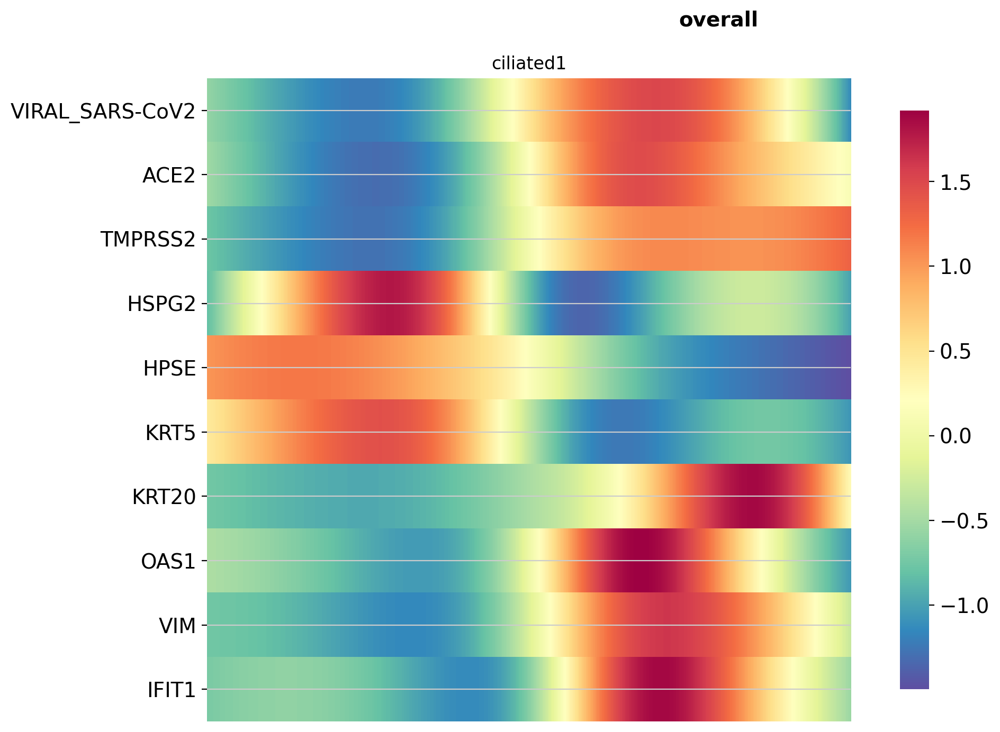

In [47]:
genes = ["VIRAL_SARS-CoV2","ACE2","TMPRSS2","HSPG2","HPSE","KRT5","KRT20","OAS1","VIM","IFIT1"]
fig = palantir.plot.plot_gene_trend_heatmaps(Woodall_inVitro_adata, genes,branch_names=["ciliated1"])
# add a title
fig.set_size_inches(12,8)  # width=12 inches, height=8 inches
fig.suptitle("overall", fontsize=14,x=0.7,y=0.99,fontweight="bold",ha="center")
fig.savefig("figures/lung/Woodall_invitro_gene_trends_overall.pdf",dpi=300,format="pdf", bbox_inches="tight")
plt.show()

#### mock group only

In [ ]:
mask = (Woodall_inVitro_adata.obs["treatment"] == "mock").to_numpy()
Woodall_inVitro_adata_mock = Woodall_inVitro_adata[mask,:].copy()
Woodall_inVitro_adata_mock

AnnData object with n_obs × n_vars = 64126 × 26447
    obs: 'sample', 'treatment', 'time', 'pool', 'sample_name', 'kit_version', 'spike-in_primer', 'scrublet_score', 'doublet_bh_pval', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'souporcell_cluster', 'donor_id', 'age_group', 'gender', 'S_score', 'G2M_score', 'phase', 'bbknn_batch', 'cell_annotation', 'age_treatment', 'score_IFN_alpha', 'score_IFN_gamma', 'score_BASALOID', 'palantir_pseudotime', 'palantir_entropy'
    var: 'gene_ids', 'n_counts', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'ribo'
    uns: 'age_group_colors', 'age_treatment_colors', 'cell_annotation_colors', 'donor_id_colors', 'kit_version_colors', 'pool_colors', 'sample_colors', 'spike-in_primer_colors', 'treatment_colors', 'DM_EigenValues', 'palantir_waypoints'
    obsm: 'X_pca', 'X_umap', 'DM_EigenVectors', 'DM_EigenVectors_multiscaled', 'palantir_fate_probabili

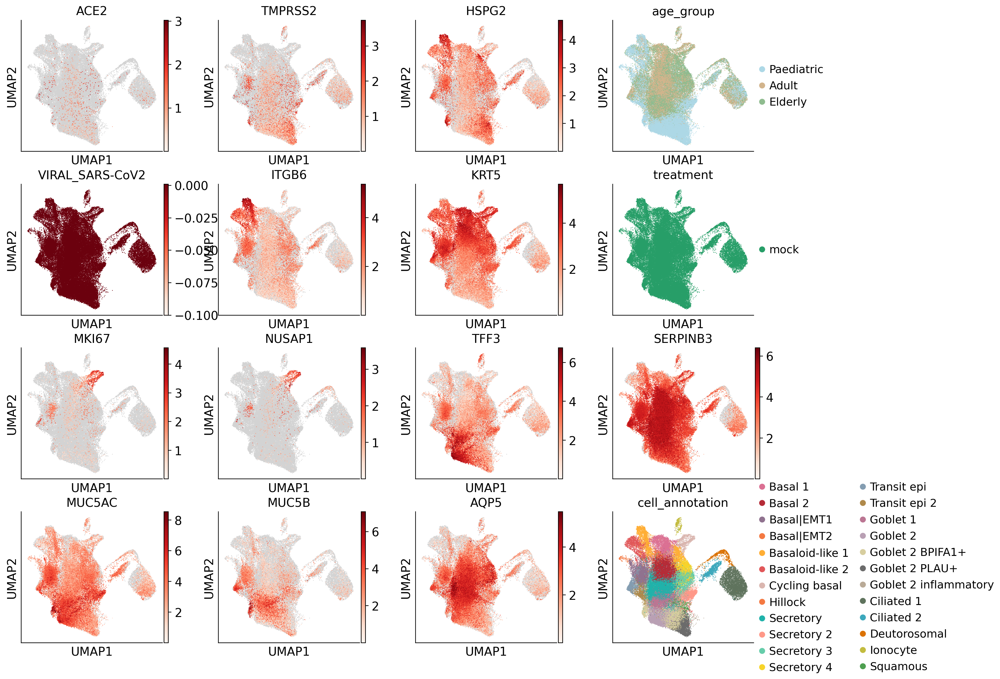

In [ ]:
with rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        adata = Woodall_inVitro_adata_mock,
        color = [
            "ACE2", "TMPRSS2","HSPG2","age_group",
            "VIRAL_SARS-CoV2","ITGB6","KRT5","treatment",
            "MKI67","NUSAP1", # basal
            "TFF3", "SERPINB3", "MUC5AC", "MUC5B","AQP5", # goblet1
            "cell_annotation"],
        ncols=4,size=3,
        use_raw=False,
        color_map=reds,vmin=0.001,
        show=False
        # layer="soupX",
    )

In [ ]:
dm_res = palantir.utils.run_diffusion_maps(Woodall_inVitro_adata_mock, n_components=10)
ms_data = palantir.utils.determine_multiscale_space(Woodall_inVitro_adata_mock)

In [ ]:
imputed_X = palantir.utils.run_magic_imputation(Woodall_inVitro_adata_mock)

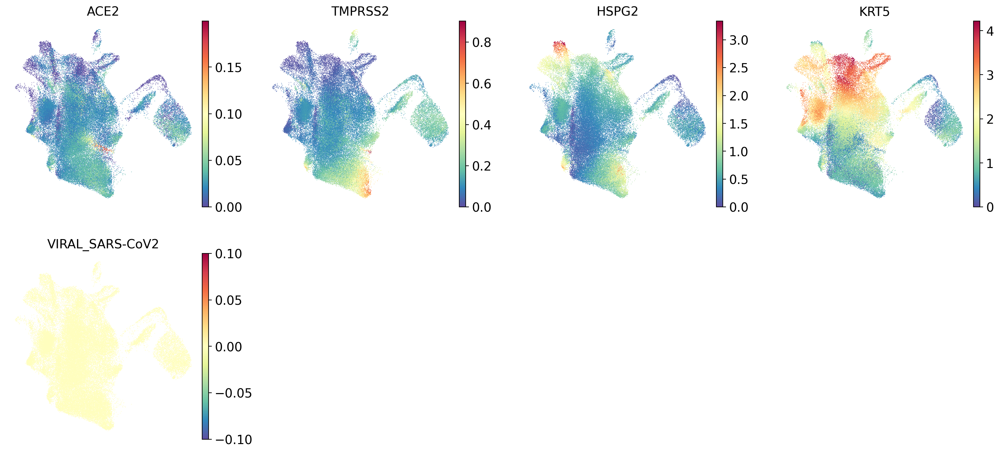

In [ ]:
sc.pl.embedding(
    Woodall_inVitro_adata_mock,
    basis="umap",
    layer="MAGIC_imputed_data",
    color=["ACE2","TMPRSS2","HSPG2","KRT5","VIRAL_SARS-CoV2"],
    frameon=False,
)
plt.show()

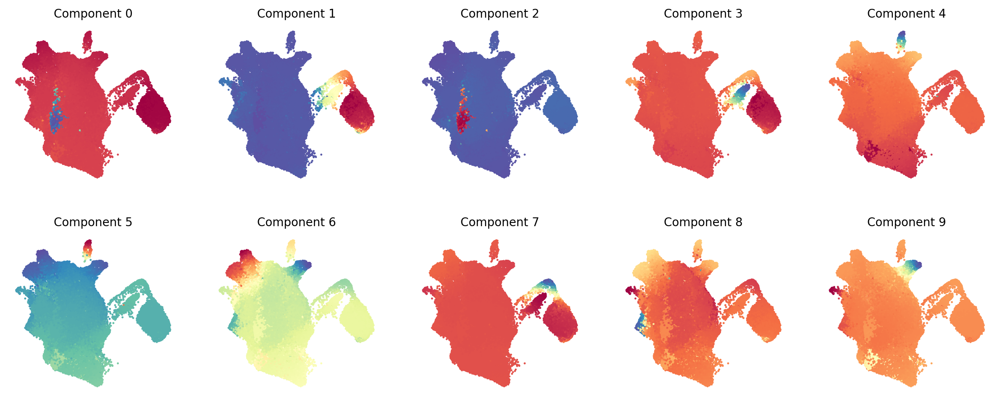

In [ ]:
palantir.plot.plot_diffusion_components(Woodall_inVitro_adata_mock)
plt.show()

In [ ]:
Woodall_inVitro_adata_mock[Woodall_inVitro_adata_mock.obs["cell_annotation"] == "Goblet 2 inflammatory"].obs

,sample,treatment,time,pool,sample_name,kit_version,spike-in_primer,scrublet_score,doublet_bh_pval,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,souporcell_cluster,donor_id,age_group,gender,S_score,G2M_score,phase,bbknn_batch,cell_annotation,age_treatment,score_IFN_alpha,score_IFN_gamma,score_BASALOID,palantir_pseudotime,palantir_entropy
CV001_KM10202575_AGGGTGAGTCTTCTCG,CV001_KM10202575,mock,4h,ALI2,ALI2_mock_4h_v1.1,v1.1,spike-in_LOW,0.173364,0.899867,2061,5285.056641,454.275116,8.595464,396.023865,7.493276,CV001_KM10202575_cluster_3,UCL_10,Adult,Female,-0.019811,-0.142459,G1,ALI2-v1.1,Goblet 2 inflammatory,Adult-mock,0.748323,0.330625,0.137522,0.515406,0.508589
CV001_KM10202581_AGATCTGCAGACAAAT,CV001_KM10202581,mock,24h,ALI3,ALI3_mock_24h_v1.1,v1.1,spike-in_LOW,0.077833,0.868111,1946,4936.204590,387.301239,7.846134,267.617432,5.421522,CV001_KM10202581_cluster_0,UCL_7,Elderly,Male,-0.042271,-0.044474,G1,ALI3-v1.1,Goblet 2 inflammatory,Elderly-mock,0.778500,0.353245,0.220104,0.535507,0.807858
CV001_KM10202581_ATAGACCCATCCCATC,CV001_KM10202581,mock,24h,ALI3,ALI3_mock_24h_v1.1,v1.1,spike-in_LOW,0.119691,0.868111,1509,3887.658691,542.918091,13.965169,345.364075,8.883600,CV001_KM10202581_cluster_0,UCL_7,Elderly,Male,-0.016778,-0.110891,G1,ALI3-v1.1,Goblet 2 inflammatory,Elderly-mock,0.248867,0.268743,0.076414,0.508752,0.589421
CV001_KM10202581_CGGTTAAAGGCTCAGA,CV001_KM10202581,mock,24h,ALI3,ALI3_mock_24h_v1.1,v1.1,spike-in_LOW,0.080160,0.868111,2753,7734.708008,373.026062,4.822756,875.684143,11.321489,CV001_KM10202581_cluster_0,UCL_7,Elderly,Male,-0.050003,-0.144946,G1,ALI3-v1.1,Goblet 2 inflammatory,Elderly-mock,0.385881,0.290118,0.127295,0.516872,0.526098
CV001_KM10202581_CGTCCATAGCAGACTG,CV001_KM10202581,mock,24h,ALI3,ALI3_mock_24h_v1.1,v1.1,spike-in_LOW,0.112207,0.868111,536,825.580505,108.992905,13.201971,64.562721,7.820282,CV001_KM10202581_cluster_0,UCL_7,Elderly,Male,-0.029794,0.018854,G2M,ALI3-v1.1,Goblet 2 inflammatory,Elderly-mock,0.611365,0.275994,0.106009,0.511635,0.646268
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CV001_KM9505823_TGAGAGGGTGTCGCTG,CV001_KM9505823,mock,72h,ALI1,ALI1_mock_72h_v2,v2,NONE,0.095943,0.969392,2222,4364.291504,163.472397,3.745680,373.052582,8.547838,CV001_KM9505823_cluster_2,UCL_2,Paediatric,Female,-0.069603,-0.095465,G1,ALI1-v2,Goblet 2 inflammatory,Paediatric-mock,0.179231,0.286563,0.357681,0.530181,0.507324
CV001_KM9505823_TGCGGGTGTGAGGCTA,CV001_KM9505823,mock,72h,ALI1,ALI1_mock_72h_v2,v2,NONE,0.187692,0.996888,2671,5325.950684,248.223709,4.660646,407.160889,7.644849,CV001_KM9505823_cluster_2,UCL_2,Paediatric,Female,-0.083365,-0.096653,G1,ALI1-v2,Goblet 2 inflammatory,Paediatric-mock,0.513901,0.348207,0.261047,0.543289,0.483246
CV001_KM9505823_TGCGTGGCACAGGTTT,CV001_KM9505823,mock,72h,ALI1,ALI1_mock_72h_v2,v2,NONE,0.106823,0.996888,2027,4143.641113,133.904297,3.231561,313.373871,7.562766,CV001_KM9505823_cluster_2,UCL_2,Paediatric,Female,-0.055449,-0.151581,G1,ALI1-v2,Goblet 2 inflammatory,Paediatric-mock,0.552459,0.264651,0.470875,0.510383,0.630524
CV001_KM9505823_TTAGTTCCACAGCCCA,CV001_KM9505823,mock,72h,ALI1,ALI1_mock_72h_v2,v2,NONE,0.128806,0.969392,1288,2598.645996,484.758087,18.654257,144.887741,5.575509,CV001_KM9505823_cluster_0,UCL_1,Paediatric,Male,-0.046320,-0.091063,G1,ALI1-v2,Goblet 2 inflammatory,Paediatric-mock,0.166189,0.215447,0.128440,0.515263,0.540595


In [ ]:
pd.DataFrame(Woodall_inVitro_adata_mock[Woodall_inVitro_adata_mock.obs["cell_annotation"] == "Ciliated 1"].obsm["X_umap"],
    index=Woodall_inVitro_adata_mock[Woodall_inVitro_adata_mock.obs["cell_annotation"] == "Ciliated 1"].obs_names,  # keep cell IDs
    columns=["UMAP1", "UMAP2"]
).idxmin()

UMAP1    CV001_KM10202581_TTCTACAAGTAAGTAC
UMAP2     CV001_KM9465185_CACTCCATCATGTCCC
dtype: str

In [ ]:
Woodall_inVitro_adata_mock[Woodall_inVitro_adata_mock.obs["cell_annotation"] == "Goblet 2 inflammatory"]

View of AnnData object with n_obs × n_vars = 90 × 26447
    obs: 'sample', 'treatment', 'time', 'pool', 'sample_name', 'kit_version', 'spike-in_primer', 'scrublet_score', 'doublet_bh_pval', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'souporcell_cluster', 'donor_id', 'age_group', 'gender', 'S_score', 'G2M_score', 'phase', 'bbknn_batch', 'cell_annotation', 'age_treatment', 'score_IFN_alpha', 'score_IFN_gamma', 'score_BASALOID', 'palantir_pseudotime', 'palantir_entropy'
    var: 'gene_ids', 'n_counts', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'ribo'
    uns: 'age_group_colors', 'age_treatment_colors', 'cell_annotation_colors', 'donor_id_colors', 'kit_version_colors', 'pool_colors', 'sample_colors', 'spike-in_primer_colors', 'treatment_colors', 'DM_EigenValues', 'palantir_waypoints'
    obsm: 'X_pca', 'X_umap', 'DM_EigenVectors', 'DM_EigenVectors_multiscaled', 'palantir_fate_prob

In [ ]:
max_basal_cell = (Woodall_inVitro_adata_mock[:, [g for g in ["KRT5","MKI67","NUSAP1"] if g in Woodall_inVitro_adata_mock.var_names]].to_df().sum(axis=1).idxmax())
max_basaloid2_cell = (Woodall_inVitro_adata_mock[:, [g for g in ["KRT5","VIM","ITGB6"] if g in Woodall_inVitro_adata_mock.var_names]].to_df().sum(axis=1).idxmax())
max_globet1_cell = (Woodall_inVitro_adata_mock[:, [g for g in ["TFF3", "SERPINB3", "MUC5AC", "MUC5B","AQP5"] if g in Woodall_inVitro_adata_mock.var_names]].to_df().sum(axis=1).idxmax())
# max_goblet2_inflam_cell = (Woodall_inVitro_adata_mock[:, [g for g in ["TFF3", "SERPINB3","IFIT3","IFIT1","OAS1"] if g in Woodall_inVitro_adata_mock.var_names]].to_df().sum(axis=1).idxmax())
max_goblet2_inflam_cell = "CV001_KM9465189_AAGACCTGTGCGCTTG"
# max_ciliated1_cell = (Woodall_inVitro_adata_mock[:, [g for g in ["OMG","PIFO","FOXJ1"] if g in Woodall_inVitro_adata_mock.var_names]].to_df().sum(axis=1).idxmax())
max_ciliated1_cell = "CV001_KM9465185_CACTCCATCATGTCCC"
marker_states = pd.Series(
    ["basal_cycling","basaloid2","goblet1","goblet2_inflammatory","ciliated1"],
    index=[max_basal_cell,max_basaloid2_cell,max_globet1_cell,max_goblet2_inflam_cell,max_ciliated1_cell]
)

terminal_states = pd.Series(
    ["basaloid2","goblet2_inflammatory","ciliated1"],
    index=[max_basaloid2_cell,max_goblet2_inflam_cell,max_ciliated1_cell]
)

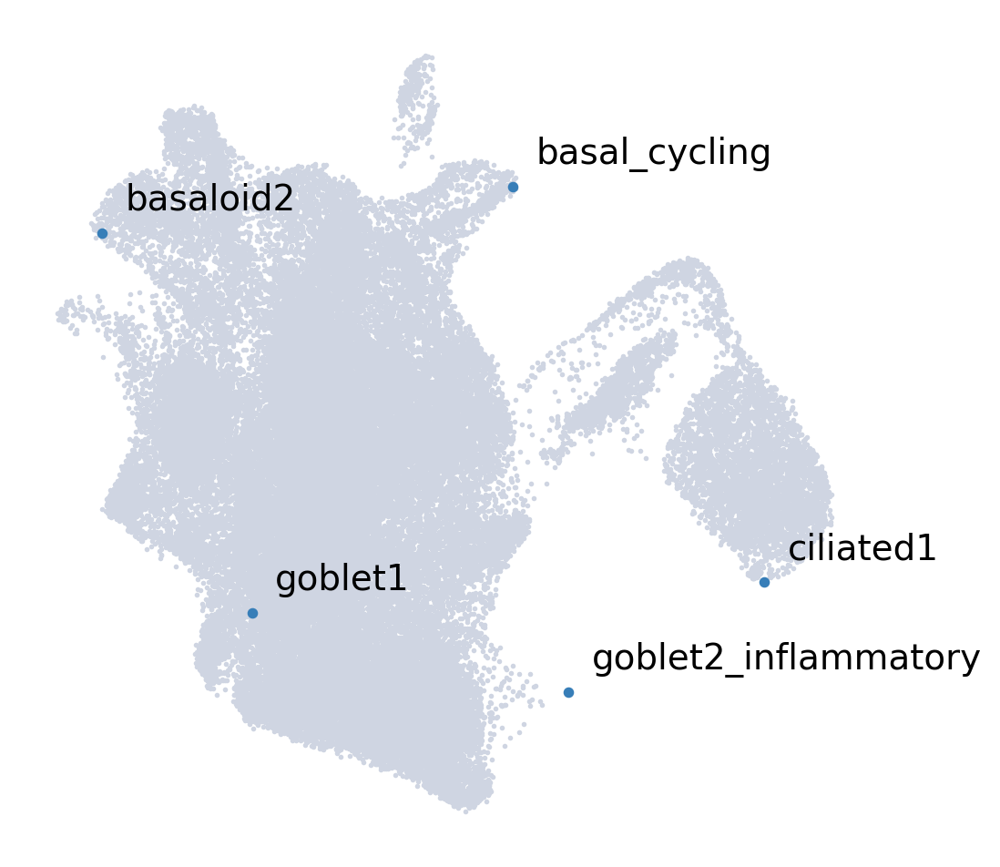

In [ ]:
palantir.plot.highlight_cells_on_umap(Woodall_inVitro_adata_mock, marker_states)
plt.show()

In [ ]:
# trajectory for basal
pr_res = palantir.core.run_palantir(
    data = Woodall_inVitro_adata_mock,early_cell = max_basal_cell, num_waypoints=500, terminal_states=terminal_states)

Sampling and flocking waypoints...
Time for determining waypoints: 0.00031015475591023766 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.2960297147432963 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...


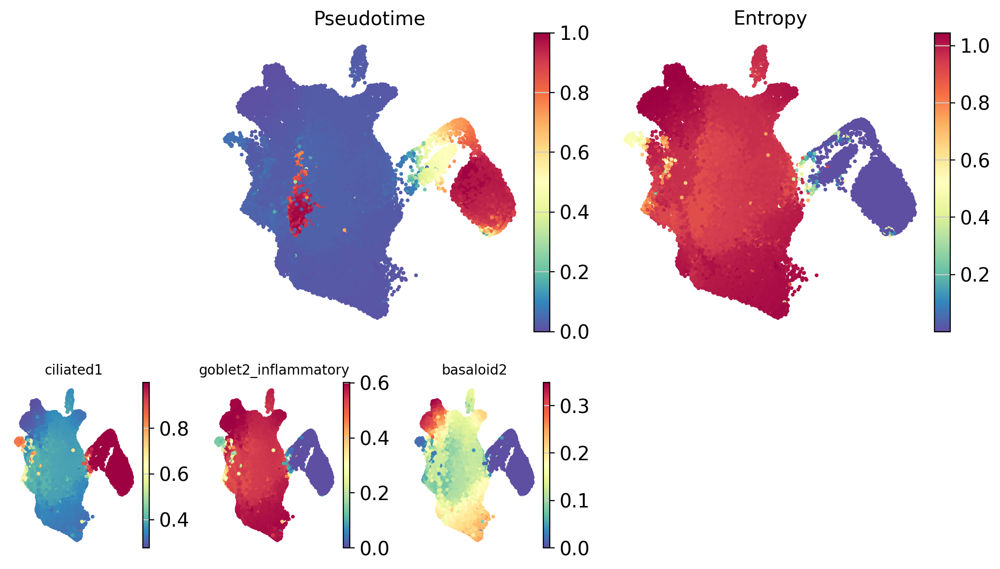

In [ ]:
palantir.plot.plot_palantir_results(Woodall_inVitro_adata_mock, s=3)
plt.show()

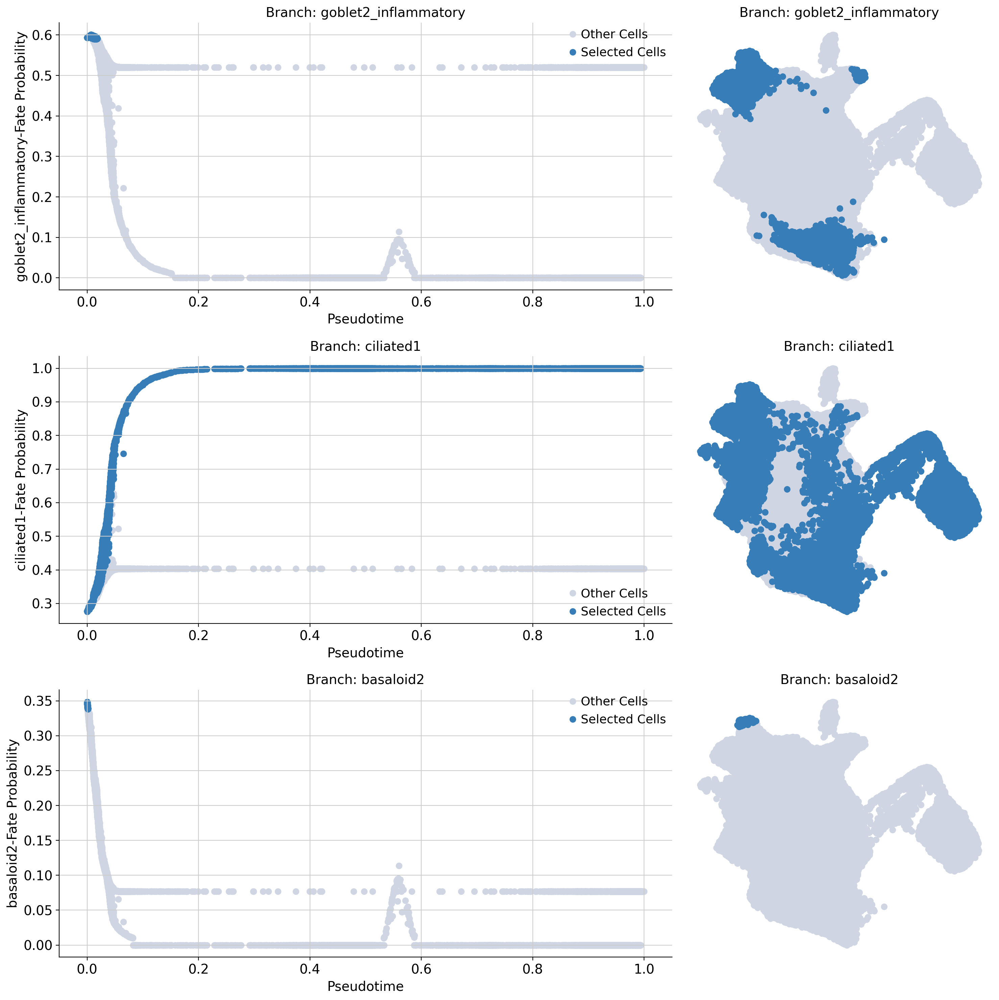

In [ ]:
masks = palantir.presults.select_branch_cells(Woodall_inVitro_adata_mock, q=.01, eps=.01)
palantir.plot.plot_branch_selection(Woodall_inVitro_adata_mock)
plt.show()

[2026-09-21 08:36:25,300] [INFO    ] Using sparse Gaussian Process since n_landmarks (50) < n_samples (103) and rank = 1.0.
[2026-09-21 08:36:25,300] [INFO    ] Using covariance function Matern52(ls=1.5632097244262695).
[2026-09-21 08:36:25,317] [INFO    ] Computing 50 landmarks with k-means clustering (random_state=42).
[2026-09-21 08:36:25,716] [INFO    ] Sigma interpreted as element-wise standard deviation.
[2026-09-21 08:36:25,809] [INFO    ] Using sparse Gaussian Process since n_landmarks (50) < n_samples (4,288) and rank = 1.0.
[2026-09-21 08:36:25,810] [INFO    ] Using covariance function Matern52(ls=1.5632097244262695).
[2026-09-21 08:36:25,823] [INFO    ] Computing 50 landmarks with k-means clustering (random_state=42).
[2026-09-21 08:36:26,389] [INFO    ] Sigma interpreted as element-wise standard deviation.
[2026-09-21 08:36:26,506] [INFO    ] Using sparse Gaussian Process since n_landmarks (50) < n_samples (24,306) and rank = 1.0.
[2026-09-21 08:36:26,506] [INFO    ] Using 

<Axes: title={'center': 'Branch: ciliated1'}>

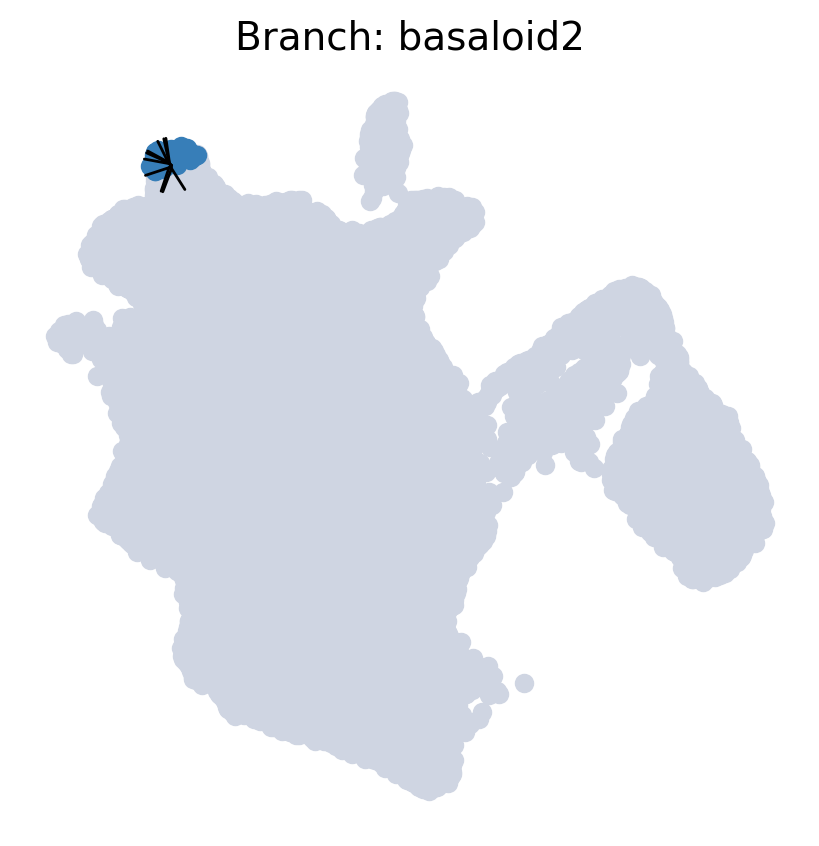

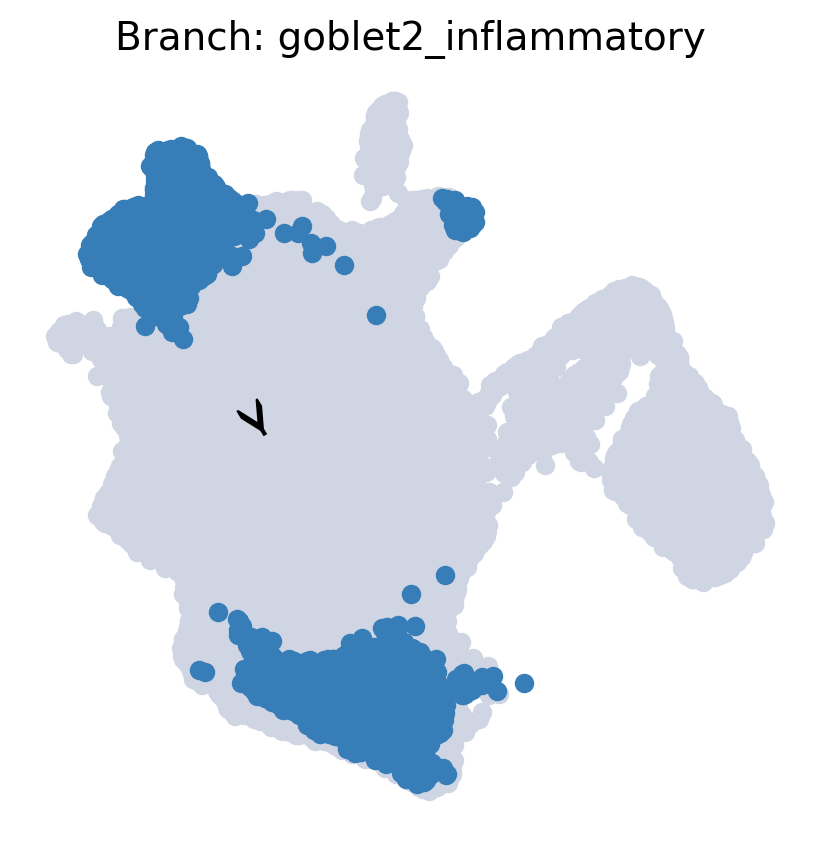

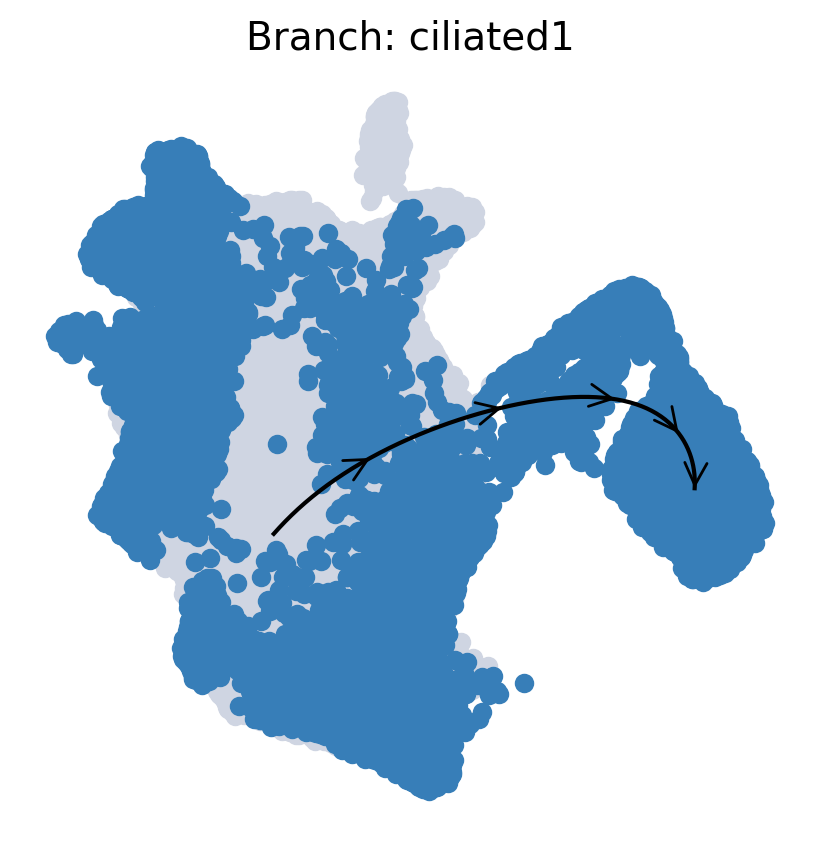

In [ ]:
palantir.plot.plot_trajectory(Woodall_inVitro_adata_mock, "basaloid2")
palantir.plot.plot_trajectory(Woodall_inVitro_adata_mock, "goblet2_inflammatory")
palantir.plot.plot_trajectory(Woodall_inVitro_adata_mock, "ciliated1")

In [ ]:
gene_trends = palantir.presults.compute_gene_trends(
    Woodall_inVitro_adata_mock,
    expression_key="MAGIC_imputed_data",
)

/home/mark/miniconda3/envs/decoupler/lib/python3.12/site-packages/palantir/presults.py:270: FutureWarning: Use obs (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`) instead of AnnData.obs_keys, AnnData.obs_keys is deprecated and will be removed in the future.
  if pseudo_time_key not in ad.obs_keys():


ciliated1
[2026-09-21 08:36:43,962] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (24,306) and rank = 1.0.
[2026-09-21 08:36:43,963] [INFO    ] Using covariance function Matern52(ls=1.0).
[2026-09-21 08:36:44,770] [INFO    ] Sigma interpreted as element-wise standard deviation.
goblet2_inflammatory
[2026-09-21 08:36:48,539] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (4,288) and rank = 1.0.
[2026-09-21 08:36:48,539] [INFO    ] Using covariance function Matern52(ls=1.0).
[2026-09-21 08:36:49,035] [INFO    ] Sigma interpreted as element-wise standard deviation.
basaloid2
[2026-09-21 08:36:50,171] [INFO    ] Using non-sparse Gaussian Process since n_landmarks (500) >= n_samples (103) and rank = 1.0.
[2026-09-21 08:36:50,171] [INFO    ] Using covariance function Matern52(ls=1.0).
[2026-09-21 08:36:50,705] [INFO    ] Sigma interpreted as element-wise standard deviation.


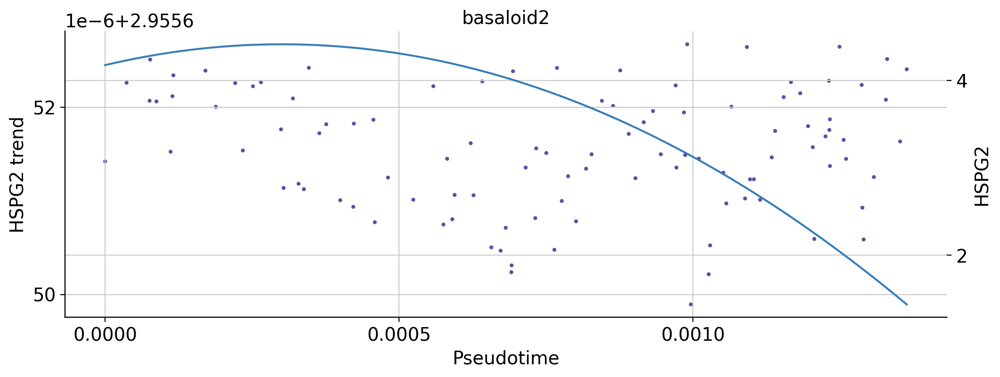

In [ ]:
palantir.plot.plot_trend(Woodall_inVitro_adata_mock,"basaloid2","HSPG2")
plt.show()

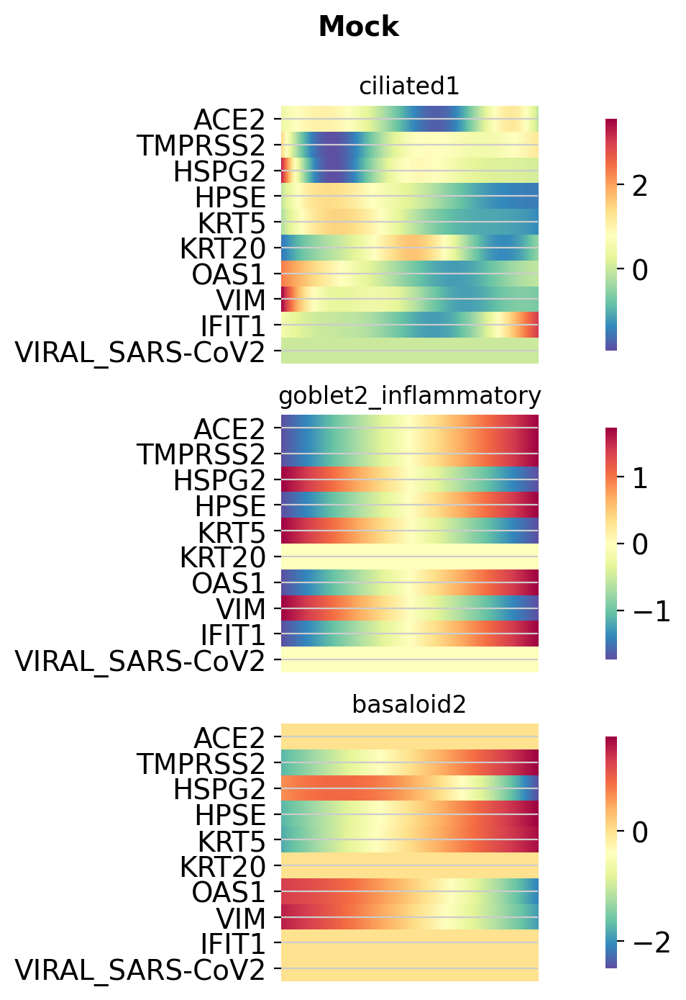

In [ ]:
genes = ["VIRAL_SARS-CoV2","ACE2","TMPRSS2","HSPG2","HPSE","KRT5","KRT20","OAS1","VIM","IFIT1"]
fig = palantir.plot.plot_gene_trend_heatmaps(Woodall_inVitro_adata_mock, genes)
# add a title
fig.set_size_inches(12,8)  # width=12 inches, height=8 inches
fig.suptitle("Mock", fontsize=14,x=0.7,y=0.99,fontweight="bold",ha="center")
fig.savefig("figures/lung/Woodall_invitro_gene_trends_mock.pdf",dpi=300,format="pdf", bbox_inches="tight")
plt.show()

#### SARS2 group only

In [ ]:
mask = (Woodall_inVitro_adata.obs["treatment"] == "SARS").to_numpy()
Woodall_inVitro_adata_sars2 = Woodall_inVitro_adata[mask,:].copy()
Woodall_inVitro_adata_sars2

AnnData object with n_obs × n_vars = 75472 × 26447
    obs: 'sample', 'treatment', 'time', 'pool', 'sample_name', 'kit_version', 'spike-in_primer', 'scrublet_score', 'doublet_bh_pval', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'souporcell_cluster', 'donor_id', 'age_group', 'gender', 'S_score', 'G2M_score', 'phase', 'bbknn_batch', 'cell_annotation', 'age_treatment', 'score_IFN_alpha', 'score_IFN_gamma', 'score_BASALOID', 'palantir_pseudotime', 'palantir_entropy'
    var: 'gene_ids', 'n_counts', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'ribo'
    uns: 'age_group_colors', 'age_treatment_colors', 'cell_annotation_colors', 'donor_id_colors', 'kit_version_colors', 'pool_colors', 'sample_colors', 'spike-in_primer_colors', 'treatment_colors', 'DM_EigenValues', 'palantir_waypoints'
    obsm: 'X_pca', 'X_umap', 'DM_EigenVectors', 'DM_EigenVectors_multiscaled', 'palantir_fate_probabili

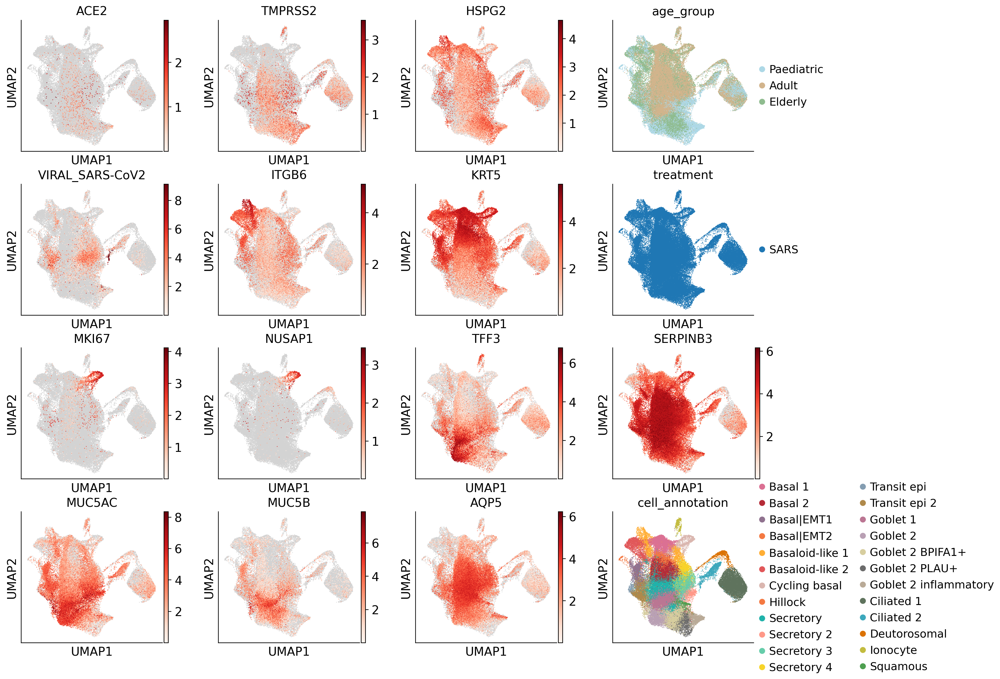

In [ ]:
with rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        adata = Woodall_inVitro_adata_sars2,
        color = [
            "ACE2", "TMPRSS2","HSPG2","age_group",
            "VIRAL_SARS-CoV2","ITGB6","KRT5","treatment",
            "MKI67","NUSAP1", # basal
            "TFF3", "SERPINB3", "MUC5AC", "MUC5B","AQP5", # goblet1
            "cell_annotation"],
        ncols=4,size=3,
        use_raw=False,
        color_map=reds,vmin=0.001,
        show=False
        # layer="soupX",
    )

In [ ]:
dm_res = palantir.utils.run_diffusion_maps(Woodall_inVitro_adata_sars2, n_components=10)
ms_data = palantir.utils.determine_multiscale_space(Woodall_inVitro_adata_sars2)

In [ ]:
imputed_X = palantir.utils.run_magic_imputation(Woodall_inVitro_adata_sars2)

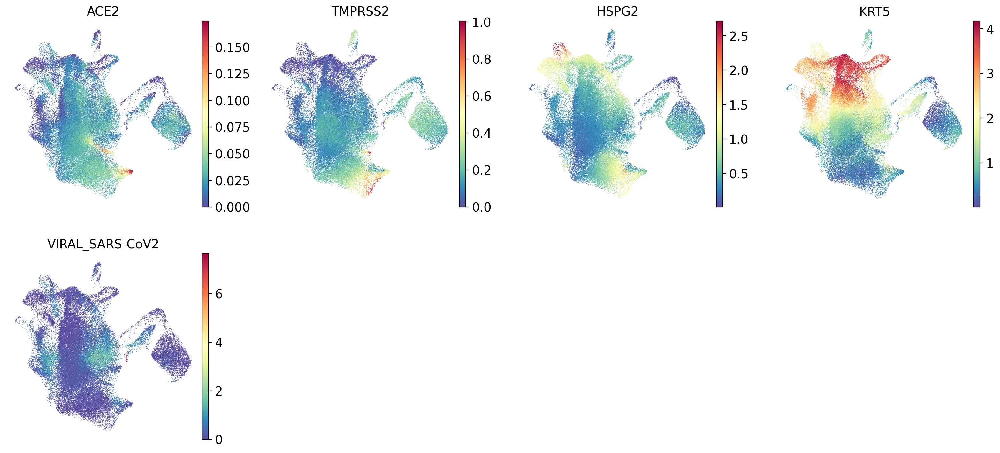

In [ ]:
sc.pl.embedding(
    Woodall_inVitro_adata_sars2,
    basis="umap",
    layer="MAGIC_imputed_data",
    color=["ACE2","TMPRSS2","HSPG2","KRT5","VIRAL_SARS-CoV2"],
    frameon=False,
)
plt.show()

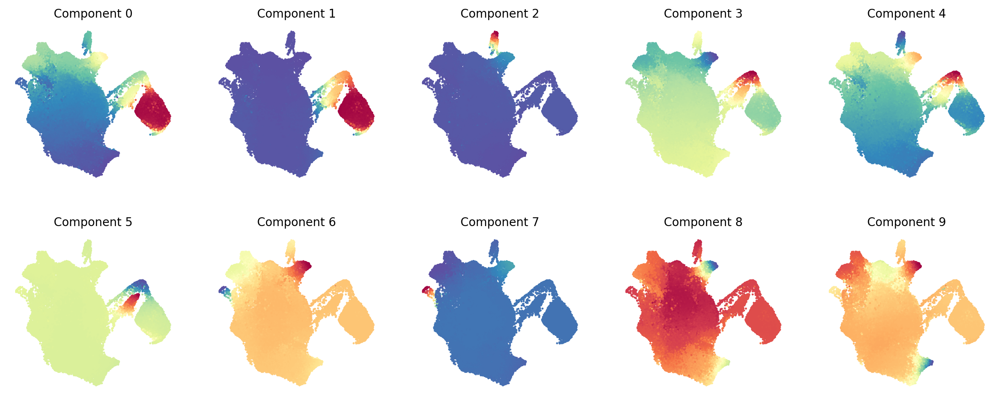

In [ ]:
palantir.plot.plot_diffusion_components(Woodall_inVitro_adata_sars2)
plt.show()

In [ ]:
max_basal_cell = (Woodall_inVitro_adata_sars2[:, [g for g in ["KRT5","MKI67","NUSAP1"] if g in Woodall_inVitro_adata_sars2.var_names]].to_df().sum(axis=1).idxmax())
max_basaloid2_cell = (Woodall_inVitro_adata_sars2[:, [g for g in ["KRT5","VIM","ITGB6"] if g in Woodall_inVitro_adata_sars2.var_names]].to_df().sum(axis=1).idxmax())
max_globet1_cell = (Woodall_inVitro_adata_sars2[:, [g for g in ["TFF3", "SERPINB3", "MUC5AC", "MUC5B","AQP5"] if g in Woodall_inVitro_adata_sars2.var_names]].to_df().sum(axis=1).idxmax())
max_goblet2_inflam_cell = (Woodall_inVitro_adata_sars2[:, [g for g in ["TFF3", "SERPINB3", "MUC5AC", "MUC5B","AQP5","IFIT3","IFIT1","OAS1"] if g in Woodall_inVitro_adata_sars2.var_names]].to_df().sum(axis=1).idxmax())
max_ciliated1_cell = (Woodall_inVitro_adata_sars2[:, [g for g in ["OMG","PIFO","FOXJ1"] if g in Woodall_inVitro_adata_sars2.var_names]].to_df().sum(axis=1).idxmax())
marker_states = pd.Series(
    ["basal_cycling","basaloid2","goblet1","goblet2_inflammatory","ciliated1"],
    index=[max_basal_cell,max_basaloid2_cell,max_globet1_cell,max_goblet2_inflam_cell,max_ciliated1_cell]
)

terminal_states = pd.Series(
    ["basaloid2","goblet2_inflammatory","ciliated1"],
    index=[max_basaloid2_cell,max_goblet2_inflam_cell,max_ciliated1_cell]
)

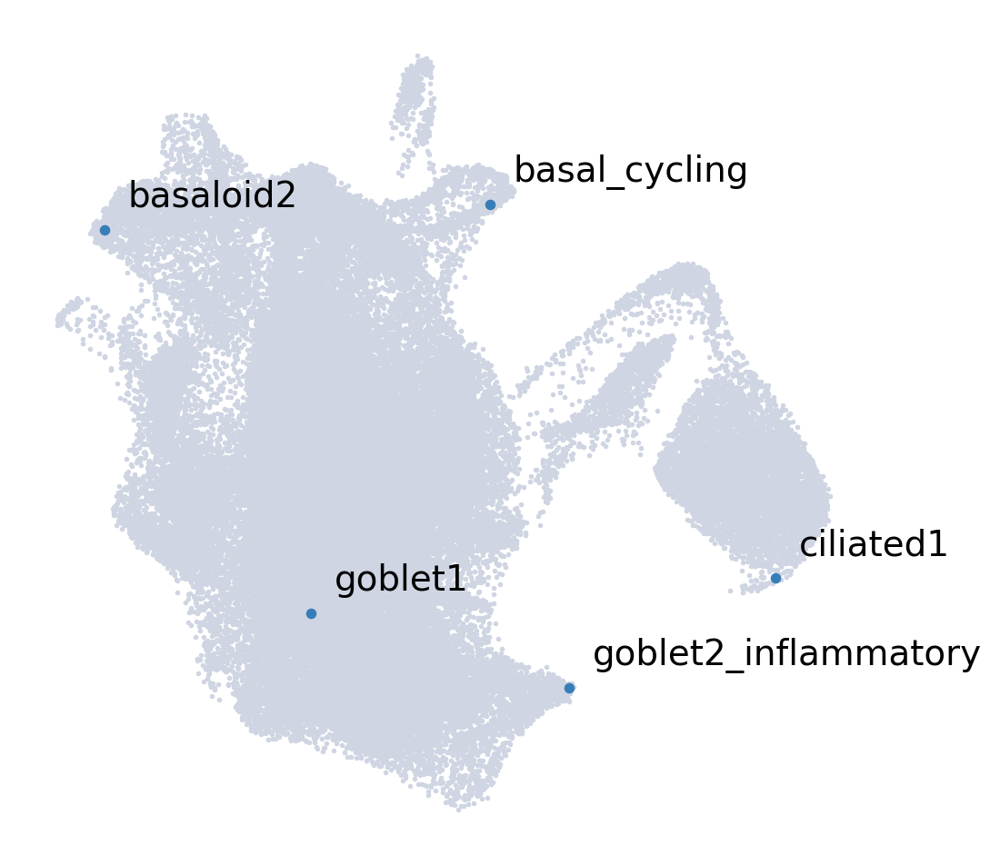

In [ ]:
palantir.plot.highlight_cells_on_umap(Woodall_inVitro_adata_sars2, marker_states)
plt.show()

In [ ]:
# trajectory for basal
pr_res = palantir.core.run_palantir(
    data = Woodall_inVitro_adata_sars2,early_cell = max_basal_cell, num_waypoints=500, terminal_states=terminal_states)

Sampling and flocking waypoints...
Time for determining waypoints: 0.0002608338991800944 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...


Time for shortest paths: 0.3432299574216207 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9997
Correlation at iteration 2: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...


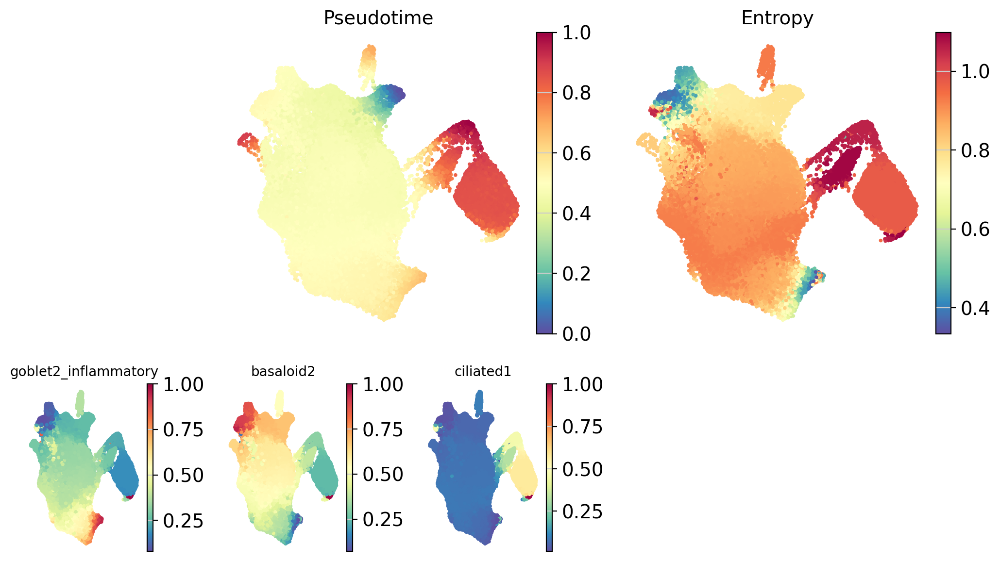

In [ ]:
palantir.plot.plot_palantir_results(Woodall_inVitro_adata_sars2, s=3)
plt.show()

In [ ]:
gene_trends = palantir.presults.compute_gene_trends(
    Woodall_inVitro_adata_sars2,
    expression_key="MAGIC_imputed_data",
)

/home/mark/miniconda3/envs/decoupler/lib/python3.12/site-packages/palantir/presults.py:270: FutureWarning: Use obs (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`) instead of AnnData.obs_keys, AnnData.obs_keys is deprecated and will be removed in the future.
  if pseudo_time_key not in ad.obs_keys():


goblet2_inflammatory
[2026-09-21 08:41:26,381] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (53,295) and rank = 1.0.
[2026-09-21 08:41:26,382] [INFO    ] Using covariance function Matern52(ls=1.0).
[2026-09-21 08:41:27,399] [INFO    ] Sigma interpreted as element-wise standard deviation.
ciliated1
[2026-09-21 08:41:42,609] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (58,782) and rank = 1.0.
[2026-09-21 08:41:42,609] [INFO    ] Using covariance function Matern52(ls=1.0).
[2026-09-21 08:41:43,711] [INFO    ] Sigma interpreted as element-wise standard deviation.
basaloid2
[2026-09-21 08:41:50,773] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (5,958) and rank = 1.0.
[2026-09-21 08:41:50,773] [INFO    ] Using covariance function Matern52(ls=1.0).
[2026-09-21 08:41:51,358] [INFO    ] Sigma interpreted as element-wise standard deviation.


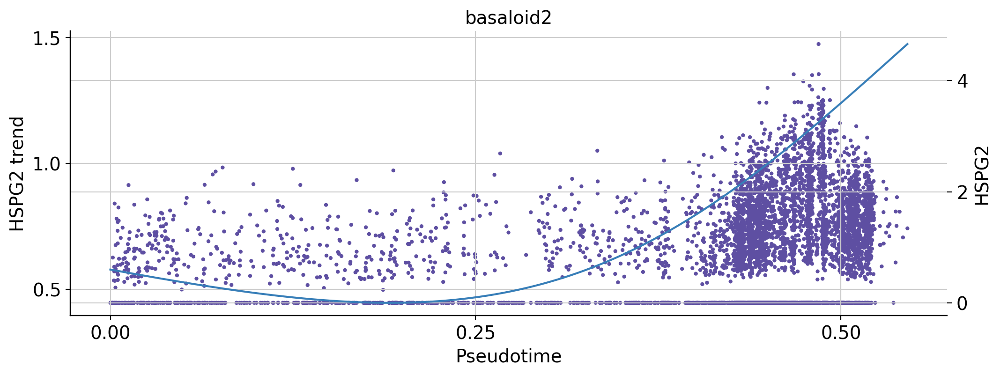

In [ ]:
palantir.plot.plot_trend(Woodall_inVitro_adata_sars2,"basaloid2","HSPG2")
plt.show()

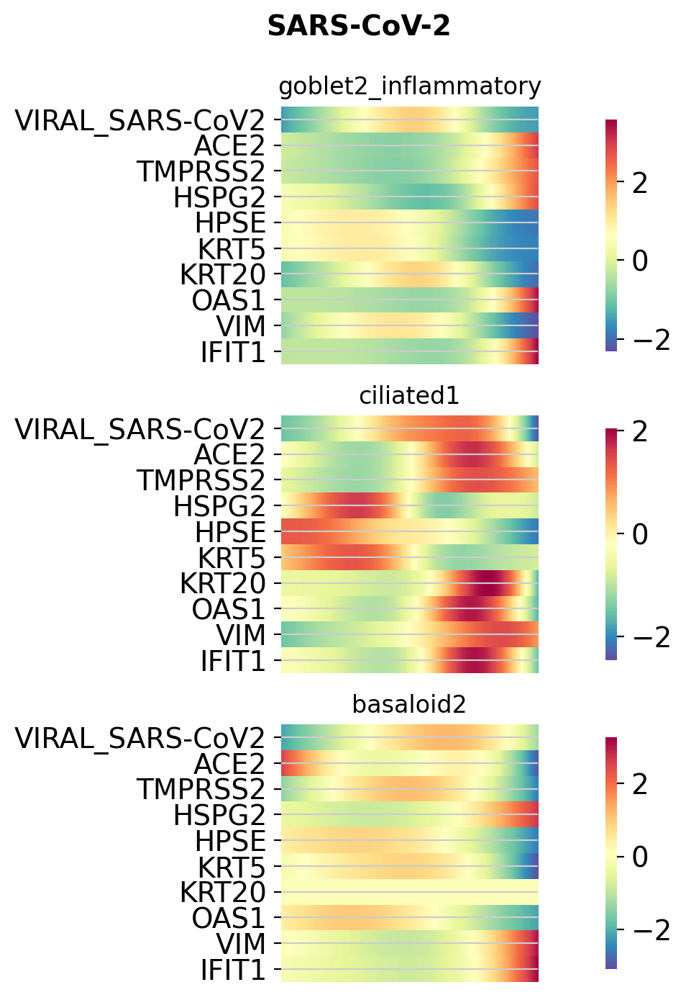

In [ ]:
genes = ["VIRAL_SARS-CoV2","ACE2","TMPRSS2","HSPG2","HPSE","KRT5","KRT20","OAS1","VIM","IFIT1",]
fig = palantir.plot.plot_gene_trend_heatmaps(Woodall_inVitro_adata_sars2, genes)
# add a title
fig.set_size_inches(12,8)  # width=12 inches, height=8 inches
fig.suptitle("SARS-CoV-2", fontsize=14,x=0.7,y=0.99,fontweight="bold",ha="center")
fig.savefig("figures/lung/Woodall_invitro_gene_trends_sars2.pdf",dpi=300,format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
pseudotime_df = (
    Woodall_inVitro_adata[:,genes].to_df().reset_index().
    merge(Woodall_inVitro_adata.obs[["treatment"]].reset_index()).
    merge(Woodall_inVitro_adata.obsm["palantir_fate_probabilities"].reset_index())
    )
pseudotime_df

,index,VIRAL_SARS-CoV2,ACE2,TMPRSS2,HSPG2,HPSE,KRT5,KRT20,OAS1,VIM,IFIT1,treatment,goblet2_inflammatory,ciliated1,basaloid2
0,CV001_KM10202575_AAACCTGAGCAGGTCA,0.0,0.0,0.970121,0.000000,0.0,0.896178,0.0,0.000000,0.0,0.0,mock,0.754637,0.043828,0.201535
1,CV001_KM10202575_AAACCTGAGCCAGTTT,0.0,0.0,0.000000,0.000000,0.0,1.071625,0.0,0.000000,0.0,0.0,mock,0.742787,0.045715,0.211498
2,CV001_KM10202575_AAACCTGAGCGTAGTG,0.0,0.0,0.000000,1.840703,0.0,1.812685,0.0,0.000000,0.0,0.0,mock,0.744821,0.045398,0.209780
3,CV001_KM10202575_AAACCTGAGCTCCTTC,0.0,0.0,0.000000,0.000000,0.0,1.244635,0.0,0.000000,0.0,0.0,mock,0.678255,0.052736,0.269009
4,CV001_KM10202575_AAACCTGAGCTGGAAC,0.0,0.0,0.000000,1.795677,0.0,3.160724,0.0,0.000000,0.0,0.0,mock,0.484696,0.038439,0.476865
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139593,CV001_KM9505916_TTTGTCAGTTCCATGA,0.0,0.0,0.000000,1.094241,0.0,0.000000,0.0,0.000000,0.0,0.0,SARS,0.792637,0.037315,0.170049
139594,CV001_KM9505916_TTTGTCATCACGATGT,0.0,0.0,0.000000,0.000000,0.0,1.253854,0.0,0.000000,0.0,0.0,SARS,0.693518,0.051937,0.254545
139595,CV001_KM9505916_TTTGTCATCCCATTAT,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,SARS,0.681473,0.052492,0.266036
139596,CV001_KM9505916_TTTGTCATCCGGGTGT,0.0,0.0,0.000000,0.653149,0.0,0.000000,0.0,0.672803,0.0,0.0,SARS,0.796185,0.036691,0.167125


In [ ]:
pseudotime_df_melt = pseudotime_df.melt(id_vars = ["index","treatment","goblet2_inflammatory","ciliated1","basaloid2"],value_vars = genes,var_name = "gene",value_name= "expression")
pseudotime_df_melt

,index,treatment,goblet2_inflammatory,ciliated1,basaloid2,gene,expression
0,CV001_KM10202575_AAACCTGAGCAGGTCA,mock,0.754637,0.043828,0.201535,VIRAL_SARS-CoV2,0.0
1,CV001_KM10202575_AAACCTGAGCCAGTTT,mock,0.742787,0.045715,0.211498,VIRAL_SARS-CoV2,0.0
2,CV001_KM10202575_AAACCTGAGCGTAGTG,mock,0.744821,0.045398,0.209780,VIRAL_SARS-CoV2,0.0
3,CV001_KM10202575_AAACCTGAGCTCCTTC,mock,0.678255,0.052736,0.269009,VIRAL_SARS-CoV2,0.0
4,CV001_KM10202575_AAACCTGAGCTGGAAC,mock,0.484696,0.038439,0.476865,VIRAL_SARS-CoV2,0.0
...,...,...,...,...,...,...,...
1395975,CV001_KM9505916_TTTGTCAGTTCCATGA,SARS,0.792637,0.037315,0.170049,IFIT1,0.0
1395976,CV001_KM9505916_TTTGTCATCACGATGT,SARS,0.693518,0.051937,0.254545,IFIT1,0.0
1395977,CV001_KM9505916_TTTGTCATCCCATTAT,SARS,0.681473,0.052492,0.266036,IFIT1,0.0
1395978,CV001_KM9505916_TTTGTCATCCGGGTGT,SARS,0.796185,0.036691,0.167125,IFIT1,0.0


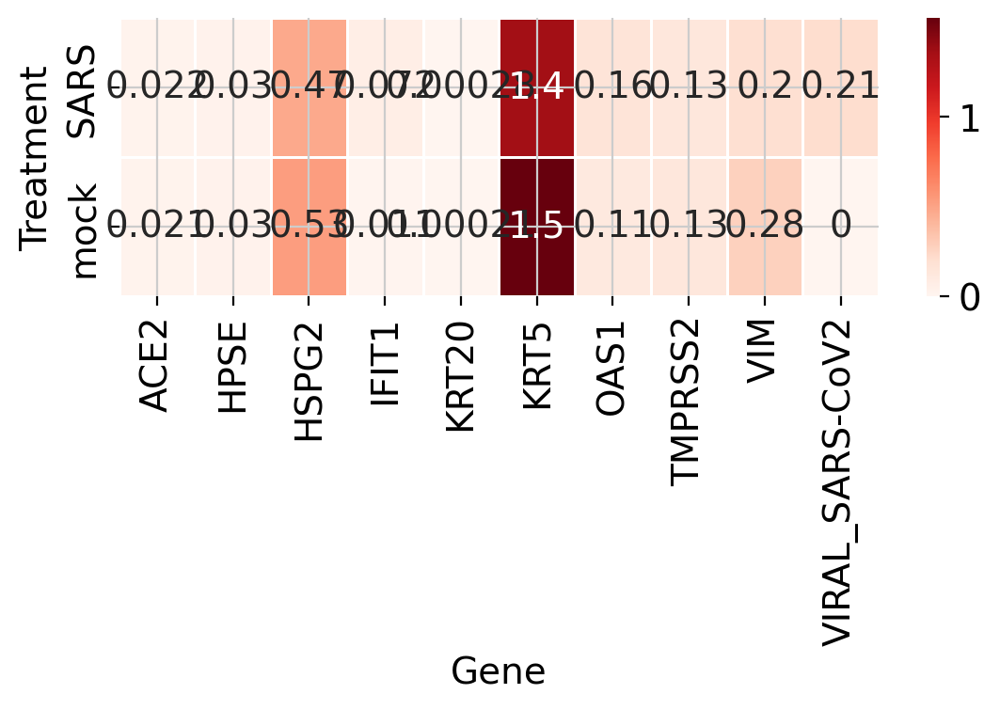

In [ ]:
agg_df = pseudotime_df_melt.groupby(["treatment", "gene"])["expression"].mean().reset_index()

# pivot for heatmap
heatmap_df = agg_df.pivot(index="treatment", columns="gene", values="expression")

plt.figure(figsize=(6, 4))
sns.heatmap(
    heatmap_df,
    cmap="Reds",
    annot=True,       # show values in cells (optional)
    linewidths=0.5
)
plt.xlabel("Gene")
plt.ylabel("Treatment")
plt.tight_layout()
plt.show()

## gut expression given JN.1 isolation in faecal samples

first try tabula sapiens

In [ ]:
ts_epi_path = config["data"]["tabula_sapeins"]["epithelium_only"]["h5ad_path"]
ts_epi_adata = sc.read(ts_epi_path)

In [ ]:
if ts_epi_adata.var["feature_name"].is_unique:
    ts_epi_adata.var = ts_epi_adata.var.set_index("feature_name")
ts_epi_adata

/home/mark/miniconda3/envs/decoupler/lib/python3.12/site-packages/anndata/_core/anndata.py:770: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['TSPAN6', 'TNMD', 'DPM1', 'SCYL3', 'C1orf112']

    Inferred to be: categorical

  value_idx = self._prep_dim_index(value.index, attr)


AnnData object with n_obs × n_vars = 228032 × 61759
    obs: 'donor_id', 'tissue_in_publication', 'anatomical_position', 'method', 'cdna_plate', 'library_plate', 'notes', 'cdna_well', 'assay_ontology_term_id', 'sample_id', 'replicate', '10X_run', 'ambient_removal', 'donor_method', 'donor_assay', 'donor_tissue', 'donor_tissue_assay', 'cell_type_ontology_term_id', 'compartment', 'broad_cell_class', 'free_annotation', 'manually_annotated', 'published_2022', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ercc', 'pct_counts_ercc', '_scvi_batch', '_scvi_labels', 'scvi_leiden_donorassay_full', 'ethnicity_original', 'scvi_leiden_res05_compartment', 'sample_number', 'organism_ontology_term_id', 'suspension_type', 'tissue_type', 'disease_ontology_term_id', 'is_primary_data', 'tissue_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'cell_type', 'assay', 'disease', 'organism', 'sex',

In [ ]:
ts_epi_adata.obs["tissue_in_publication"].cat.categories

Index(['Bladder', 'Ear', 'Eye', 'Heart', 'Kidney', 'Large_Intestine', 'Liver',
       'Lung', 'Mammary', 'Muscle', 'Ovary', 'Pancreas', 'Prostate',
       'Salivary_Gland', 'Skin', 'Small_Intestine', 'Stomach', 'Testis',
       'Thymus', 'Tongue', 'Trachea', 'Uterus'],
      dtype='str')

In [ ]:
ts_epi_tissue_of_interest = ['Trachea','Lung','Salivary_Gland','Stomach','Small_Intestine','Large_Intestine']

In [ ]:
len(ts_epi_tissue_of_interest)

6

In [ ]:
ts_epi_adata.obs[["tissue_in_publication","broad_cell_class","cell_type"]].value_counts().reset_index(name="n").query("tissue_in_publication in @ts_epi_tissue_of_interest").reset_index()

,index,tissue_in_publication,broad_cell_class,cell_type,n
0,3,Small_Intestine,intestinal epithelial cell,enterocyte of epithelium proper of duodenum,13495
1,5,Salivary_Gland,glandular epithelial cell,acinar cell of salivary gland,12237
2,6,Lung,epithelial cell of lung,pulmonary alveolar type 2 cell,11594
3,9,Trachea,epithelial cell,basal cell,10247
4,12,Small_Intestine,intestinal epithelial cell,enterocyte of epithelium proper of ileum,6477
...,...,...,...,...,...
7987,22651,Stomach,vestibular dark cell,vestibular dark cell,0
7988,22652,Stomach,vestibular dark cell,interstitial cell of Cajal,0
7989,22653,Stomach,vestibular dark cell,enteroendocrine cell,0
7990,22654,Stomach,vestibular dark cell,keratocyte,0


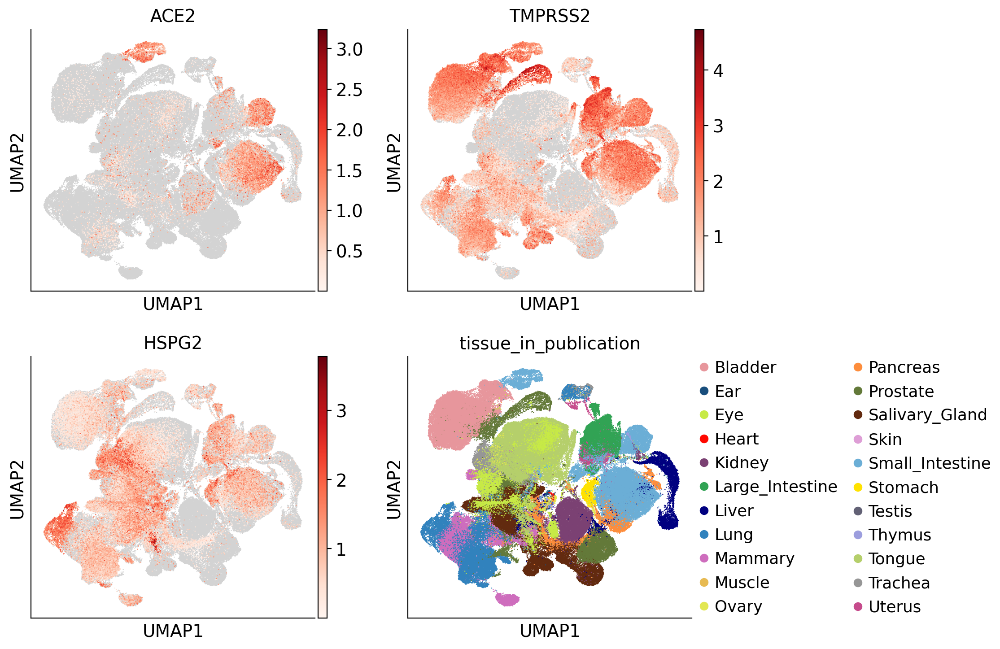

In [ ]:
with rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(
        adata = ts_epi_adata,
        color = [
            "ACE2","TMPRSS2","HSPG2","tissue_in_publication"],
        ncols=2,size=3,
        use_raw=False,
        color_map=reds,vmin=0.00001,
        show=False
        # layer="soupX",
    )

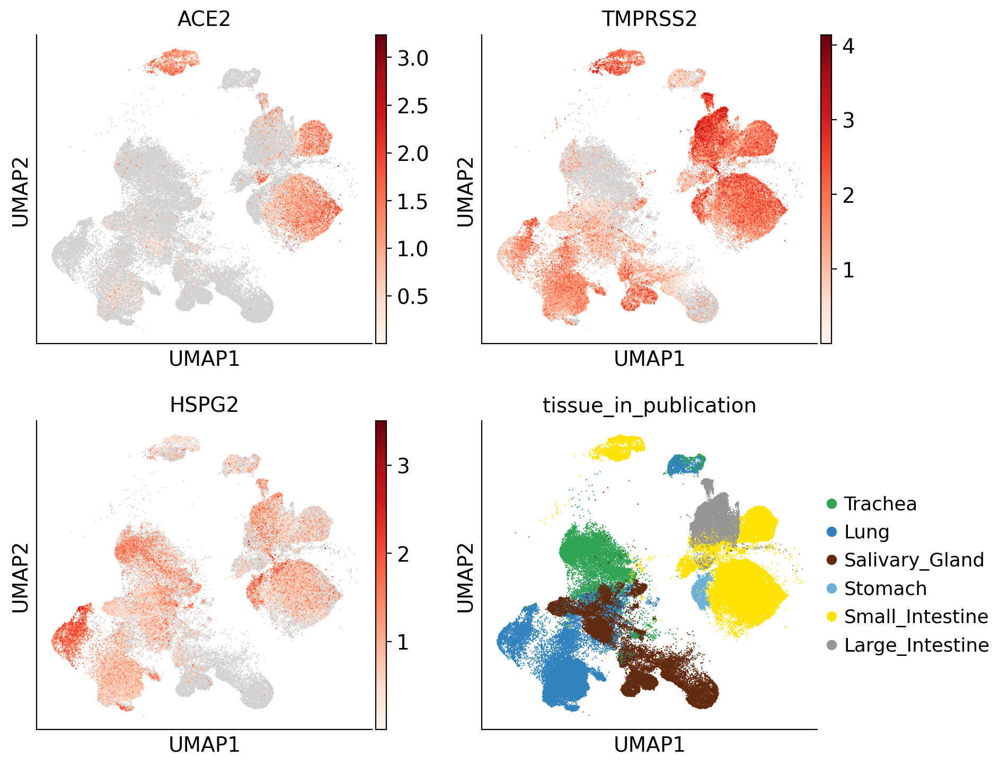

In [ ]:
ts_epi_adata_GiLung = ts_epi_adata[ts_epi_adata.obs.query('tissue_in_publication in @ts_epi_tissue_of_interest').index].copy()
ts_epi_adata_GiLung.obs["tissue_in_publication"] = ts_epi_adata_GiLung.obs["tissue_in_publication"].cat.remove_unused_categories().cat.reorder_categories(ts_epi_tissue_of_interest,ordered=True)

with rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(
        adata = ts_epi_adata_GiLung,
        color = [
            "ACE2","TMPRSS2","HSPG2","tissue_in_publication"],
        ncols=2,size=3,
        use_raw=False,
        color_map=reds,vmin=0.00001,
        show=False
        # layer="soupX",
    )

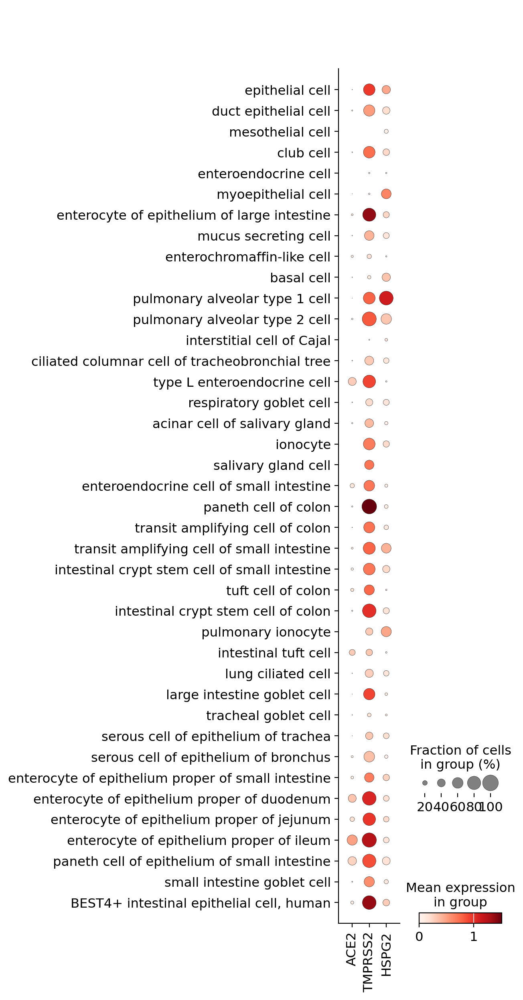

In [ ]:
with rc_context({"figure.figsize": (6,2)}):
    axes = sc.pl.dotplot(
        adata = ts_epi_adata_GiLung,
        var_names=["ACE2", "TMPRSS2","HSPG2"],
        groupby="cell_type",use_raw=False,
        show=False,)
    fig = plt.gcf() # get current figure
    # fig.suptitle(f"Cell Type Group: Epithelia", fontsize=14, fontweight="bold",x=0.1, y=0.8)
    # fig.savefig("figures/lung/lung_dotplot.pdf",dpi=300,bbox_inches='tight')

In [ ]:
ts_epi_adata_GiLung.obs["tissue_in_publication"].cat.categories

Index(['Trachea', 'Lung', 'Salivary_Gland', 'Stomach', 'Small_Intestine',
       'Large_Intestine'],
      dtype='str')

In [ ]:
ts_epi_adata_GiLung.var

,ensembl_id,genome,mt,ercc,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,mean,std,feature_is_filtered,feature_reference,feature_biotype,feature_length,feature_type
feature_name,,,,,,,,,,,,,,,
TSPAN6,ENSG00000000003.15,Gencode_v41,False,False,161872,2.379617,91.800375,4697694.0,0.202621,0.368180,False,NCBITaxon:9606,gene,2396,protein_coding
TNMD,ENSG00000000005.6,Gencode_v41,False,False,9323,0.220273,99.527743,434850.0,0.002081,0.048563,False,NCBITaxon:9606,gene,873,protein_coding
DPM1,ENSG00000000419.14,Gencode_v41,False,False,461590,3.523875,76.618161,6956619.0,0.298359,0.398492,False,NCBITaxon:9606,gene,1262,protein_coding
SCYL3,ENSG00000000457.14,Gencode_v41,False,False,156149,0.493041,92.090273,973332.0,0.088291,0.242396,False,NCBITaxon:9606,gene,2916,protein_coding
C1orf112,ENSG00000000460.17,Gencode_v41,False,False,120250,0.281519,93.908737,555757.0,0.031793,0.149903,False,NCBITaxon:9606,gene,2661,protein_coding
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ENSG00000290162.1,ENSG00000290162.1,Gencode_v41,False,False,600,0.001394,99.969607,2751.0,0.000155,0.009765,False,NCBITaxon:9606,gene,149,unprocessed_pseudogene
ENSG00000290163.1,ENSG00000290163.1,Gencode_v41,False,False,1814,0.006923,99.908112,13667.0,0.000650,0.020350,False,NCBITaxon:9606,gene,144,unprocessed_pseudogene
ENSG00000290164.1,ENSG00000290164.1,Gencode_v41,False,False,934,0.005787,99.952688,11424.0,0.000311,0.013881,False,NCBITaxon:9606,gene,138,unprocessed_pseudogene


In [ ]:
ts_epi_adata_GiLung.var.query('feature_name.str.contains("HPSE")')

,ensembl_id,genome,mt,ercc,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,mean,std,feature_is_filtered,feature_reference,feature_biotype,feature_length,feature_type
feature_name,,,,,,,,,,,,,,,
HPSE2,ENSG00000172987.13,Gencode_v41,False,False,46230,0.126849,97.658220,250417.0,0.012204,0.122050,False,NCBITaxon:9606,gene,2121,protein_coding
HPSE,ENSG00000173083.16,Gencode_v41,False,False,95424,0.319011,95.166298,629773.0,0.033814,0.155712,False,NCBITaxon:9606,gene,1624,protein_coding


: 

In [ ]:
from itertools import product
# https://www.nature.com/articles/s41586-022-04474-x/figures/11
genes_of_interest = ["ACE2", "TMPRSS2","HSPG2","HPSE","HPSE2","CDKN1A"
                    #  "XYLT2","SLC35B2"
                    ] 

ncols = len(genes_of_interest)
nrows = len(ts_epi_tissue_of_interest)
figsize = 6
wspace = 0.5

fig, axs = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(ncols * figsize + figsize * wspace * (ncols - 1), nrows * figsize),
)
plt.subplots_adjust(wspace=wspace,hspace=1)
# This produces two Axes objects in a single Figure
print("axes:", axs)
for (i,tissue), (j,gene) in product(enumerate(ts_epi_adata_GiLung.obs["tissue_in_publication"].cat.categories),enumerate(genes_of_interest)):
    ax = axs[i][j]

    sc.pl.violin(
            adata = ts_epi_adata_GiLung[(ts_epi_adata_GiLung.obs["tissue_in_publication"]==tissue)],
            keys=gene,
            groupby="cell_type",use_raw=False,
            # use_raw=False,layer="soupX",
            size=0.5, # stripplot=False,  # remove the internal dots
            # inner="box",  # adds a boxplot inside violins
            rotation = 90,
            ax=ax,
            show=False
        )
    ax.set_title(tissue)
fig = plt.gcf() # get current figure
fig.suptitle(f"Lung and GI epithelial cells", fontsize=14, fontweight="bold",x=0.5, y=0.95)
fig.savefig("figures/lung/TS_violin_plot.pdf",dpi=300,bbox_inches='tight')
plt.close()

axes: [[<Axes: > <Axes: > <Axes: > <Axes: > <Axes: > <Axes: >]
 [<Axes: > <Axes: > <Axes: > <Axes: > <Axes: > <Axes: >]
 [<Axes: > <Axes: > <Axes: > <Axes: > <Axes: > <Axes: >]
 [<Axes: > <Axes: > <Axes: > <Axes: > <Axes: > <Axes: >]
 [<Axes: > <Axes: > <Axes: > <Axes: > <Axes: > <Axes: >]
 [<Axes: > <Axes: > <Axes: > <Axes: > <Axes: > <Axes: >]]


/home/mark/miniconda3/envs/decoupler/lib/python3.12/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list
/home/mark/miniconda3/envs/decoupler/lib/python3.12/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list
/home/mark/miniconda3/envs/decoupler/lib/python3.12/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list
/home/mark/miniconda3/envs/decoupler/lib/python3.12/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colo

In [ ]:
for tissue in ts_epi_adata_GiLung.obs["tissue_in_publication"].cat.categories:
    print(tissue)

In [ ]:
ts_epi_adata_GiLung.obs["tissue_in_publication"].value_counts()

In [ ]:
ts_epi_adata_GiLung[
                ts_epi_adata_GiLung.obs["tissue"] == tissue
            ]

In [ ]:
tissues = ts_epi_adata_GiLung.obs["tissue_in_publication"].cat.categories
n = len(tissues)

ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(24, 5 * nrows)
)

axes = axes.flatten()  # ← important

with PdfPages("figures/lung/TS_dotplots_by_tissue.pdf") as pdf:
    for ax, tissue in zip(axes, tissues):
        sc.pl.dotplot(
            adata=ts_epi_adata_GiLung[
                ts_epi_adata_GiLung.obs["tissue_in_publication"] == tissue
            ],
            var_names=genes_of_interest,
            groupby="cell_type",
            use_raw=False,show=False,
            # dot_max=1,dot_min=0,
            ax=ax
        )
        ax.set_title(
            f"Tissue: {tissue}",fontsize=11,
            fontweight="bold",pad=0,y=0.9
        )

    # Hide unused axes (if odd number of tissues)
    for ax in axes[len(tissues):]:
        ax.axis("off")

    fig.subplots_adjust(hspace=0.8, wspace=0.4)
    pdf.savefig(fig)
    plt.show()
    plt.close(fig)

In [ ]:
ts_epi_adata_GiLung.obs

### cell cycling scores
Load cell cycle genes defined in [Tirosh et al, 2015](https://www.science.org/doi/10.1126/science.aad0501)

In [ ]:
# import cell cycling genes
import pooch
p_zip = pooch.retrieve(
    "https://www.dropbox.com/s/3dby3bjsaf5arrw/cell_cycle_vignette_files.zip?dl=1",
    known_hash="sha256:6557fe2a2761d1550d41edf61b26c6d5ec9b42b4933d56c3161164a595f145ab",
    path="data/cell_cycle_genes",
)

In [ ]:
import zipfile
with zipfile.ZipFile(p_zip, "r") as f_zip:
    f_csv = zipfile.Path(f_zip, "nestorawa_forcellcycle_expressionMatrix.txt").open()
    # adata = sc.read_csv(f_csv, delimiter="\t").T
    cell_cycle_genes = zipfile.Path(f_zip, "regev_lab_cell_cycle_genes.txt").read_text().splitlines()
s_genes = [x for x in cell_cycle_genes[:43] if x in ts_epi_adata_GiLung.var_names]
g2m_genes = [x for x in cell_cycle_genes[43:] if x in ts_epi_adata_GiLung.var_names]
cell_cycle_genes = [*s_genes, *g2m_genes]

In [ ]:
sc.tl.score_genes_cell_cycle(ts_epi_adata_GiLung, s_genes=s_genes, g2m_genes=g2m_genes,use_raw=False)

In [ ]:
ts_epi_adata_GiLung.obs

In [ ]:
ts_epi_adata_GiLung_cc_genes = ts_epi_adata_GiLung[:, cell_cycle_genes].copy()
sc.tl.pca(ts_epi_adata_GiLung_cc_genes)
sc.pl.pca_scatter(ts_epi_adata_GiLung_cc_genes, color="phase")

In [ ]:
rsc.get.anndata_to_GPU(ts_epi_adata_GiLung)
rsc.get.anndata_to_CPU(ts_epi_adata_GiLung) # moves `.X` to the CPU

In [ ]:
with rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(
        adata = ts_epi_adata_GiLung,
        color = [
            "ACE2","TMPRSS2","HSPG2","tissue_in_publication",
            "S_score","G2M_score","phase","CDKN1A"],
        ncols=4,size=3,
        use_raw=False,
        color_map=reds,vmin=0.00001,
        show=False
        # layer="soupX",
    )

## Ziegler et al., Cell 2020
A rare dataset with nasal, lung, and small intestine!